<a id="sec-title"></a>

# **Computational Urban Comfort Indexing and Annealed Optimisation for Latent Potentials**

**Authors:** [Sijie Yang](https://sijie-yang.com), [Zdravko Trivic](https://cde.nus.edu.sg/arch/staffs/zdravko-trivic-dr/), [Yihan Zhu](https://ual.sg/author/yihan-zhu/), [Mahmoud Abdelrahman](https://ual.sg/author/mahmoud-abdelrahman/), [Filip Biljecki](https://filipbiljecki.com)*

by [Urban Analytics Lab](https://ual.sg), [Department of Architecture](https://cde.nus.edu.sg/arch/), [College of Design and Engineering](https://cde.nus.edu.sg), [National University of Singapore](https://www.nus.edu.sg)

---

**Note:** Each .ipynb file can be run independently. This work is licensed under a [Creative Commons Attribution 4.0 International License](https://creativecommons.org/licenses/by/4.0/).

**All notebooks in this project (code series):**

- <a href="code_0_social_media_post_embedding.ipynb" target="_blank" rel="noopener noreferrer">code_0 — social media post embedding</a>
- <a href="code_1_social_activity_data.ipynb" target="_blank" rel="noopener noreferrer">code_1 — social activity data</a>
- <a href="code_2_geospatial_data.ipynb" target="_blank" rel="noopener noreferrer">code_2 — geospatial data</a>
- <a href="code_3_uci_social_activity_field.ipynb" target="_blank" rel="noopener noreferrer">code_3 — UCI social activity field</a>
- <a href="code_4_uci_causal_forest.ipynb" target="_blank" rel="noopener noreferrer">code_4 — UCI causal forest</a>
- <a href="code_5_uci_resident_expert_survey.ipynb" target="_blank" rel="noopener noreferrer">code_5 — resident & expert survey for UCI modelling</a>
- <a href="code_6_uci_modelling.ipynb" target="_blank" rel="noopener noreferrer">code_6 — UCI modelling</a>
- <a href="code_7_uci_optimisation_puci.ipynb" target="_blank" rel="noopener noreferrer">code_7 — UCI optimisation (pUCI & UCP)</a>
- <a href="code_8_result_analytics.ipynb" target="_blank" rel="noopener noreferrer">code_8 — result analytics</a>


**Abbreviations used in this codebase series:**  
- Comfort metrics: `UCI` (Urban Comfort Index), `UCP` (Urban Comfort Potential), `pUCI` (policy-driven Urban Comfort Index).  
- Variation metrics: `SSV` (Social-Spatial Variation), `SVI` (Social Variation Index), `SPVI` (Spatial Variation Index), `SSVI` (Socio-Spatial Variation Index).  
- Geospatial dimensions: `SP` (Streetscape Perception), `FC` (Functionality), `AC` (Accessibility), `CD` (Contact Density).
- Model and dimensions: `HGWR` (Hierarchical Geographically Weighted Regression), `CATE` (Conditional Average Treatment Effect).

<a id="sec-overview"></a>

# Result Analytics

This notebook visualises **UCI**, **UCP**, and **SSV** outputs, runs multi-run UCP integration, **ΔUCP** district analytics, and produces paper figures under `figure/`.

**Primary data (committed for paper reproduction):**
- `data/data_uci_puci.gpkg` — canonical UCI / pUCI
- `data/optimisation_result/` — multi-run Ising outputs

**Pipeline outputs (may differ slightly if regenerated):**
- `data/data_uci_modelling_with_preds_uci.gpkg` ([code_6](code_6_uci_modelling.ipynb))
- `data/optimisation_result_user/` ([code_7](code_7_uci_optimisation_puci.ipynb))

**Section list:**

- [Title & license](#sec-title)
- [1. UCI visualisation](#sec-1-uci)
  - [1.1 Load UCI data](#sec-1-1-load)
  - [1.2 Activity UCI maps](#sec-1-2-maps)
  - [1.3 Field vs UCI regression](#sec-1-3-regression)
- [2. UCP visualisation](#sec-2-ucp)
  - [2.1 Load optimisation outputs](#sec-2-1-load)
  - [2.2 Policy × feature maps](#sec-2-2-maps)
  - [2.3 Single policy × feature selector](#sec-2-3-single)
- [3. Socio-spatial variation (SSV)](#sec-3-ssv)
  - [3.1 Overlap in UCP results](#sec-3-1-overlap)
  - [3.2 SSVI maps and boxplots](#sec-3-2-ssvi)
  - [3.3 SVI visualisation](#sec-3-3-svi)
  - [3.4 SPVI visualisation](#sec-3-4-spvi)
- [4. UCP result analytics](#sec-4-analytics)
  - [4.1 Multi-run integrated UCP](#sec-4-1-integrate)
  - [4.2 Normalisation experiment](#sec-4-2-norm-exp)
  - [4.3 Normalisation quality metrics](#sec-4-3-norm-metrics)
  - [4.4 Normalisation selection](#sec-4-4-norm-select)
  - [4.5 ΔUCP maps](#sec-4-5-delta)
- [5. Administrative district analytics](#sec-5-admin)
  - [5.1 District-level UCP](#sec-5-1-district)
  - [5.2 Optimisation benefit by district](#sec-5-2-benefit)
  - [5.3 Level distribution](#sec-5-3-levels)
  - [5.4 PCA of ΔUCP](#sec-5-4-pca)
  - [5.5 Policy latent panels](#sec-5-5-latent)
  - [5.6 PC distribution plots](#sec-5-6-pc)
  - [5.7 District classification (K-means)](#sec-5-7-kmeans)
  - [5.8 Classification maps and charts](#sec-5-8-viz)
  - [5.9 Admin policy profile](#sec-5-9-profile)
  - [5.10 Representative type maps](#sec-5-10-type)
  - [5.11 Optimisation performance](#sec-5-11-perf)


<a id="sec-1-uci"></a>

## 1. UCI visualisation

Choropleth maps and field–UCI diagnostics for five activity UCIs.


<a id="sec-1-1-load"></a>

### 1.1 Load UCI data

Import libraries; read `data_uci_puci.gpkg`.


In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd

# read saved uci_gdf (UCI and pUCI)
uci_gdf = gpd.read_file(f"data/data_uci_puci.gpkg")

# check the columns
print(uci_gdf.columns)

# define the UCI features to plot
uci_features = [
    'UCI_1_eating_and_drinking',
    'UCI_2_nature_exploration', 
    'UCI_3_community_gathering',
    'UCI_4_walking_and_exercising',
    'UCI_5_urban_sightseeing'
]

# define feature labels for display
feature_labels = [
    'Eating & Drinking',
    'Nature Exploration',
    'Community Gathering', 
    'Walking & Exercising',
    'Urban Sightseeing'
]

# define custom colours for each feature
custom_colours = ['#FF1D00', '#2C9500', '#FF8800', '#1988FF', '#440253']

Index(['id', 'longitude', 'latitude', 'SP_1-E_comfort',
       'SP_2-E_sunshine_intensity', 'SP_3-E_temp_inference',
       'SP_4-E_humidity_inference', 'SP_5-E_wind_inference',
       'SP_6-E_greenery_rate', 'SP_7-E_shading_area', 'SP_8-E_heat_source',
       'SP_9-E_traffic_flow', 'SP_1-D_imageability', 'SP_2-D_enclosure',
       'SP_3-D_human_scale', 'SP_4-D_complexity', 'FC_1-R_eating_rating',
       'FC_1-D_eating_density', 'FC_2-R_retail_rating',
       'FC_2-D_retail_density', 'FC_3-R_life_rating', 'FC_3-D_life_density',
       'FC_4-R_recreation_rating', 'FC_4-D_recreation_density',
       'FC_5-R_health_rating', 'FC_5-D_health_density',
       'FC_6-R_community_rating', 'FC_6-D_community_density',
       'FC_7-R_trans_rating', 'FC_7-D_trans_density', 'FC_1-H_HDB_density',
       'FC_1-G_review_polarity', 'FC_2-G_review_subjectivity',
       'AC_1-L_closeness400', 'AC_2-L_closeness800', 'AC_1-G_closeness2000',
       'AC_2-G_closeness6000', 'AC_1-T_subway_accessibility',
      

<a id="sec-1-2-maps"></a>

### 1.2 Activity UCI maps

Five-panel UCI choropleths on the shared grid.


Saved figure → figure/code_8_uci.png


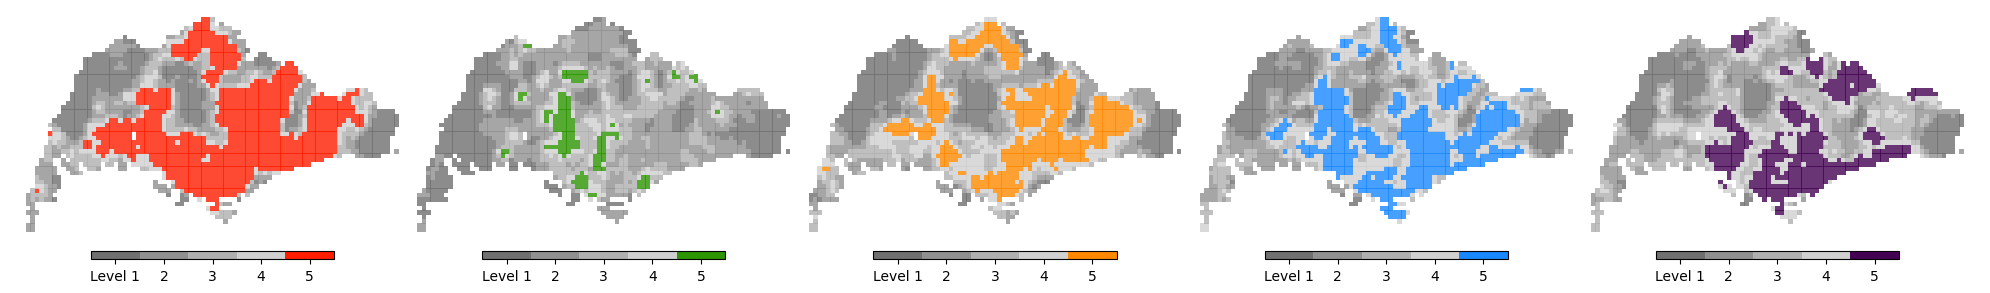

In [2]:

# Create subplots for visualisation
fig, axes = plt.subplots(1, len(uci_features), figsize=(20, 4))

for i, feature in enumerate(uci_features):
    if feature in uci_gdf.columns:
        # Get feature values and create 5-level classification
        feature_values = uci_gdf[feature]
        
        # Create 5 equal-interval bins
        vmin = feature_values.min()
        vmax = feature_values.max()
        bins = np.linspace(vmin, vmax, 6)  # 6 edges for 5 bins
        
        # Classify values into 5 levels
        uci_gdf[f'{feature}_level'] = pd.cut(feature_values, bins=bins, labels=[1, 2, 3, 4, 5], include_lowest=True)
        
        # Define 5 discrete colours from light to dark based on the main colour
        base_colour = custom_colours[i]
        # Convert hex to RGB
        base_rgb = mcolors.hex2color(base_colour)
        
        # Create 5 discrete colours: very light grey to main colour
        discrete_colours = [
            '#707070',  # Level 1: Medium dark grey
            '#909090',  # Level 2: Medium grey
            '#B0B0B0',  # Level 3: Medium light grey
            '#D0D0D0',  # Level 4: Light grey
            base_colour  # Level 5: Main colour
        ]
        
        # Create discrete colourmap
        cmap = mcolors.ListedColormap(discrete_colours)
        
        # Plot the feature using discrete levels with square markers
        im = uci_gdf.plot(ax=axes[i], column=f'{feature}_level', cmap=cmap, alpha=0.8, 
                          markersize=11, marker='s', edgecolor='none', categorical=True)
        
        # Add colourbar with discrete levels
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=0.5, vmax=5.5))
        sm.set_array([])
        cbar = plt.colorbar(sm, ax=axes[i], shrink=0.6, location='bottom', pad=0.03, 
                            aspect=30, fraction=0.03, ticks=[1, 2, 3, 4, 5])
        cbar.set_ticklabels(['Level 1', '2', '3', '4', '5'])
        cbar.ax.tick_params(labelsize=10)  # Set colorbar tick label font size to small

        axes[i].set_axis_off()
    else:
        axes[i].set_axis_off()

plt.tight_layout(w_pad=-1)
import os
os.makedirs("figure", exist_ok=True)
fig.savefig("figure/code_8_uci.png", dpi=300, bbox_inches="tight")
print("Saved figure → figure/code_8_uci.png")
plt.show()


<a id="sec-1-3-regression"></a>

### 1.3 Field vs UCI regression

Dual-axis scatter/bar: activity field vs UCI count.


Saved figure → figure/code_8_uci_field_regression.png
Saved figure → figure/code_8_uci_field_regression.svg


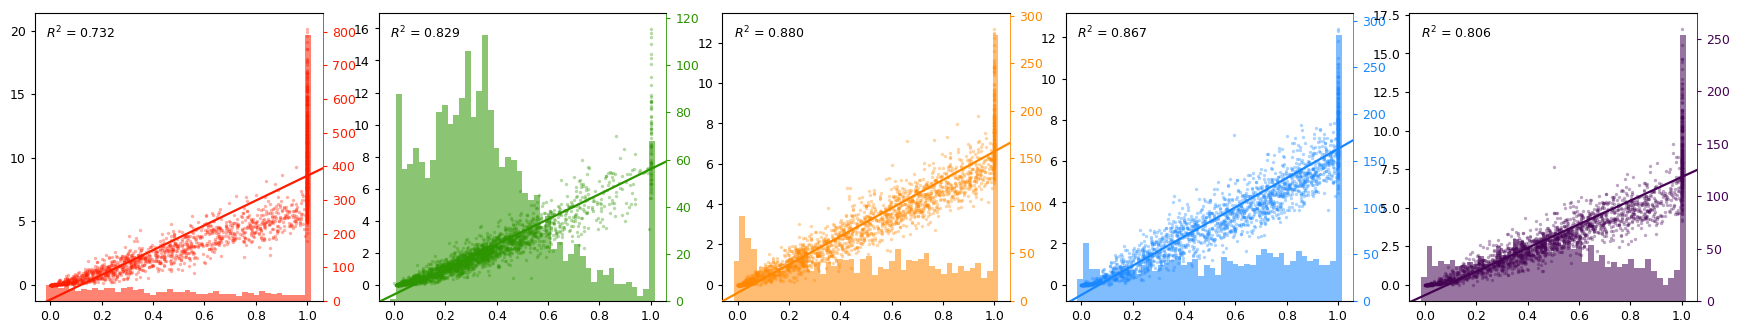

In [3]:
# Field vs UCI regression — dual y-axis: left=field (scatter), right=UCI count (bars)
import os
from scipy.stats import linregress

if "uci_gdf" not in globals():
    raise RuntimeError("Run the UCI load cell first.")

FIELD_COLS = [
    "eating_field", "nature_field", "community_field",
    "walking_field", "sightseeing_field",
]

PANEL_SIZE = 3.5               # inches — square panel (1:1 box aspect)
N_UCI_BINS = 50
BAR_ALPHA = 0.55
COUNT_Y_PAD = 0.08          # headroom above max bin on count axis
SCATTER_SIZE = 6
SCATTER_ALPHA = 0.35
TREND_LW = 1.6
PAD_FRAC = 0.06
TICK_SIZE = 9


def _uci_histogram(uci_vals, x_lo, x_hi):
    uci_vals = np.asarray(uci_vals, dtype=float)
    uci_vals = uci_vals[np.isfinite(uci_vals)]
    edges = np.linspace(x_lo, x_hi, N_UCI_BINS + 1)
    counts, _ = np.histogram(uci_vals, bins=edges)
    return counts, edges


fig, axes = plt.subplots(
    1, len(uci_features),
    figsize=(PANEL_SIZE * len(uci_features), PANEL_SIZE),
)
if not hasattr(axes, "__len__"):
    axes = [axes]

for i, (uci_col, field_col) in enumerate(zip(uci_features, FIELD_COLS)):
    ax = axes[i]
    if uci_col not in uci_gdf.columns or field_col not in uci_gdf.columns:
        ax.set_axis_off()
        continue

    uci_all = uci_gdf[uci_col].to_numpy(dtype=float)
    field_all = uci_gdf[field_col].to_numpy(dtype=float)
    m = np.isfinite(uci_all) & np.isfinite(field_all)
    uci, field = uci_all[m], field_all[m]
    if len(uci) < 3:
        ax.set_axis_off()
        continue

    base_colour = custom_colours[i]
    x0, x1 = float(np.min(uci)), float(np.max(uci))
    y1 = float(np.max(field))
    dx = (x1 - x0) * PAD_FRAC or 0.01
    x_lo, x_hi = x0 - dx, x1 + dx
    y1_pad = y1 * (1.0 + PAD_FRAC) if y1 > 0 else max(y1 + 0.01, 0.01)
    dy = y1_pad * PAD_FRAC or 0.01
    y_lo = -dy

    ax_cnt = ax.twinx()
    counts, edges = _uci_histogram(uci_all, x_lo, x_hi)
    cmax = float(counts.max()) if counts.max() > 0 else 1.0
    ax_cnt.bar(
        edges[:-1], counts, width=np.diff(edges), align="edge",
        color=base_colour, alpha=BAR_ALPHA, edgecolor="none", zorder=0,
    )
    ax_cnt.set_ylim(0.0, cmax * (1.0 + COUNT_Y_PAD))
    ax_cnt.tick_params(axis="y", labelsize=TICK_SIZE, length=3, colors=base_colour)
    ax_cnt.spines["right"].set_linewidth(0.6)
    ax_cnt.spines["right"].set_color(base_colour)

    ax.scatter(uci, field, c=base_colour, s=SCATTER_SIZE, alpha=SCATTER_ALPHA,
               linewidths=0, zorder=3)
    slope, intercept, r_val, _, _ = linregress(uci, field)
    xx = np.linspace(x_lo, x_hi, 100)
    ax.plot(xx, intercept + slope * xx, color=base_colour, lw=TREND_LW, zorder=4)
    ax.text(
        0.04, 0.96, f"$R^2$ = {r_val ** 2:.3f}",
        transform=ax.transAxes, ha="left", va="top", fontsize=TICK_SIZE,
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white", alpha=0.75, edgecolor="none"),
        zorder=5,
    )

    ax.set_xlim(x_lo, x_hi)
    ax.set_ylim(y_lo, y1_pad)
    ax.set_box_aspect(1)
    ax.tick_params(axis="x", labelsize=TICK_SIZE, length=3)
    ax.tick_params(axis="y", labelsize=TICK_SIZE, length=3)
    for sp in ("top", "bottom", "left"):
        ax.spines[sp].set_linewidth(0.6)
    ax.spines["right"].set_visible(False)

    ax.set_zorder(2)
    ax_cnt.set_zorder(1)
    ax.patch.set_visible(False)

plt.tight_layout(w_pad=-1)
os.makedirs("figure", exist_ok=True)
_fig_path_png = "figure/code_8_uci_field_regression.png"
_fig_path_svg = "figure/code_8_uci_field_regression.svg"
fig.savefig(_fig_path_png, dpi=300, bbox_inches="tight")
fig.savefig(_fig_path_svg, bbox_inches="tight")
print(f"Saved figure → {_fig_path_png}")
print(f"Saved figure → {_fig_path_svg}")
plt.show()

<a id="sec-2-ucp"></a>

## 2. UCP visualisation

Maps of optimisation overlap intensity by policy and feature.


<a id="sec-2-1-load"></a>

### 2.1 Load optimisation outputs

Read multi-run recommendation GeoPackages.


In [4]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# read saved ucp_gdf (UCI and pUCI)
ucp_gdf = gpd.read_file(f"data/data_uci_puci.gpkg")

# check the columns
print(ucp_gdf.columns)

Index(['id', 'longitude', 'latitude', 'SP_1-E_comfort',
       'SP_2-E_sunshine_intensity', 'SP_3-E_temp_inference',
       'SP_4-E_humidity_inference', 'SP_5-E_wind_inference',
       'SP_6-E_greenery_rate', 'SP_7-E_shading_area', 'SP_8-E_heat_source',
       'SP_9-E_traffic_flow', 'SP_1-D_imageability', 'SP_2-D_enclosure',
       'SP_3-D_human_scale', 'SP_4-D_complexity', 'FC_1-R_eating_rating',
       'FC_1-D_eating_density', 'FC_2-R_retail_rating',
       'FC_2-D_retail_density', 'FC_3-R_life_rating', 'FC_3-D_life_density',
       'FC_4-R_recreation_rating', 'FC_4-D_recreation_density',
       'FC_5-R_health_rating', 'FC_5-D_health_density',
       'FC_6-R_community_rating', 'FC_6-D_community_density',
       'FC_7-R_trans_rating', 'FC_7-D_trans_density', 'FC_1-H_HDB_density',
       'FC_1-G_review_polarity', 'FC_2-G_review_subjectivity',
       'AC_1-L_closeness400', 'AC_2-L_closeness800', 'AC_1-G_closeness2000',
       'AC_2-G_closeness6000', 'AC_1-T_subway_accessibility',
      

<a id="sec-2-2-maps"></a>

### 2.2 Policy × feature maps

Grid of UCP surfaces for all pUCI × feature pairs.


Loading optimised data for all policies and features...


Creating plots: 100%|██████████| 45/45 [00:19<00:00,  2.35it/s, Plotting UCP_5 - CD_leisure_density]     


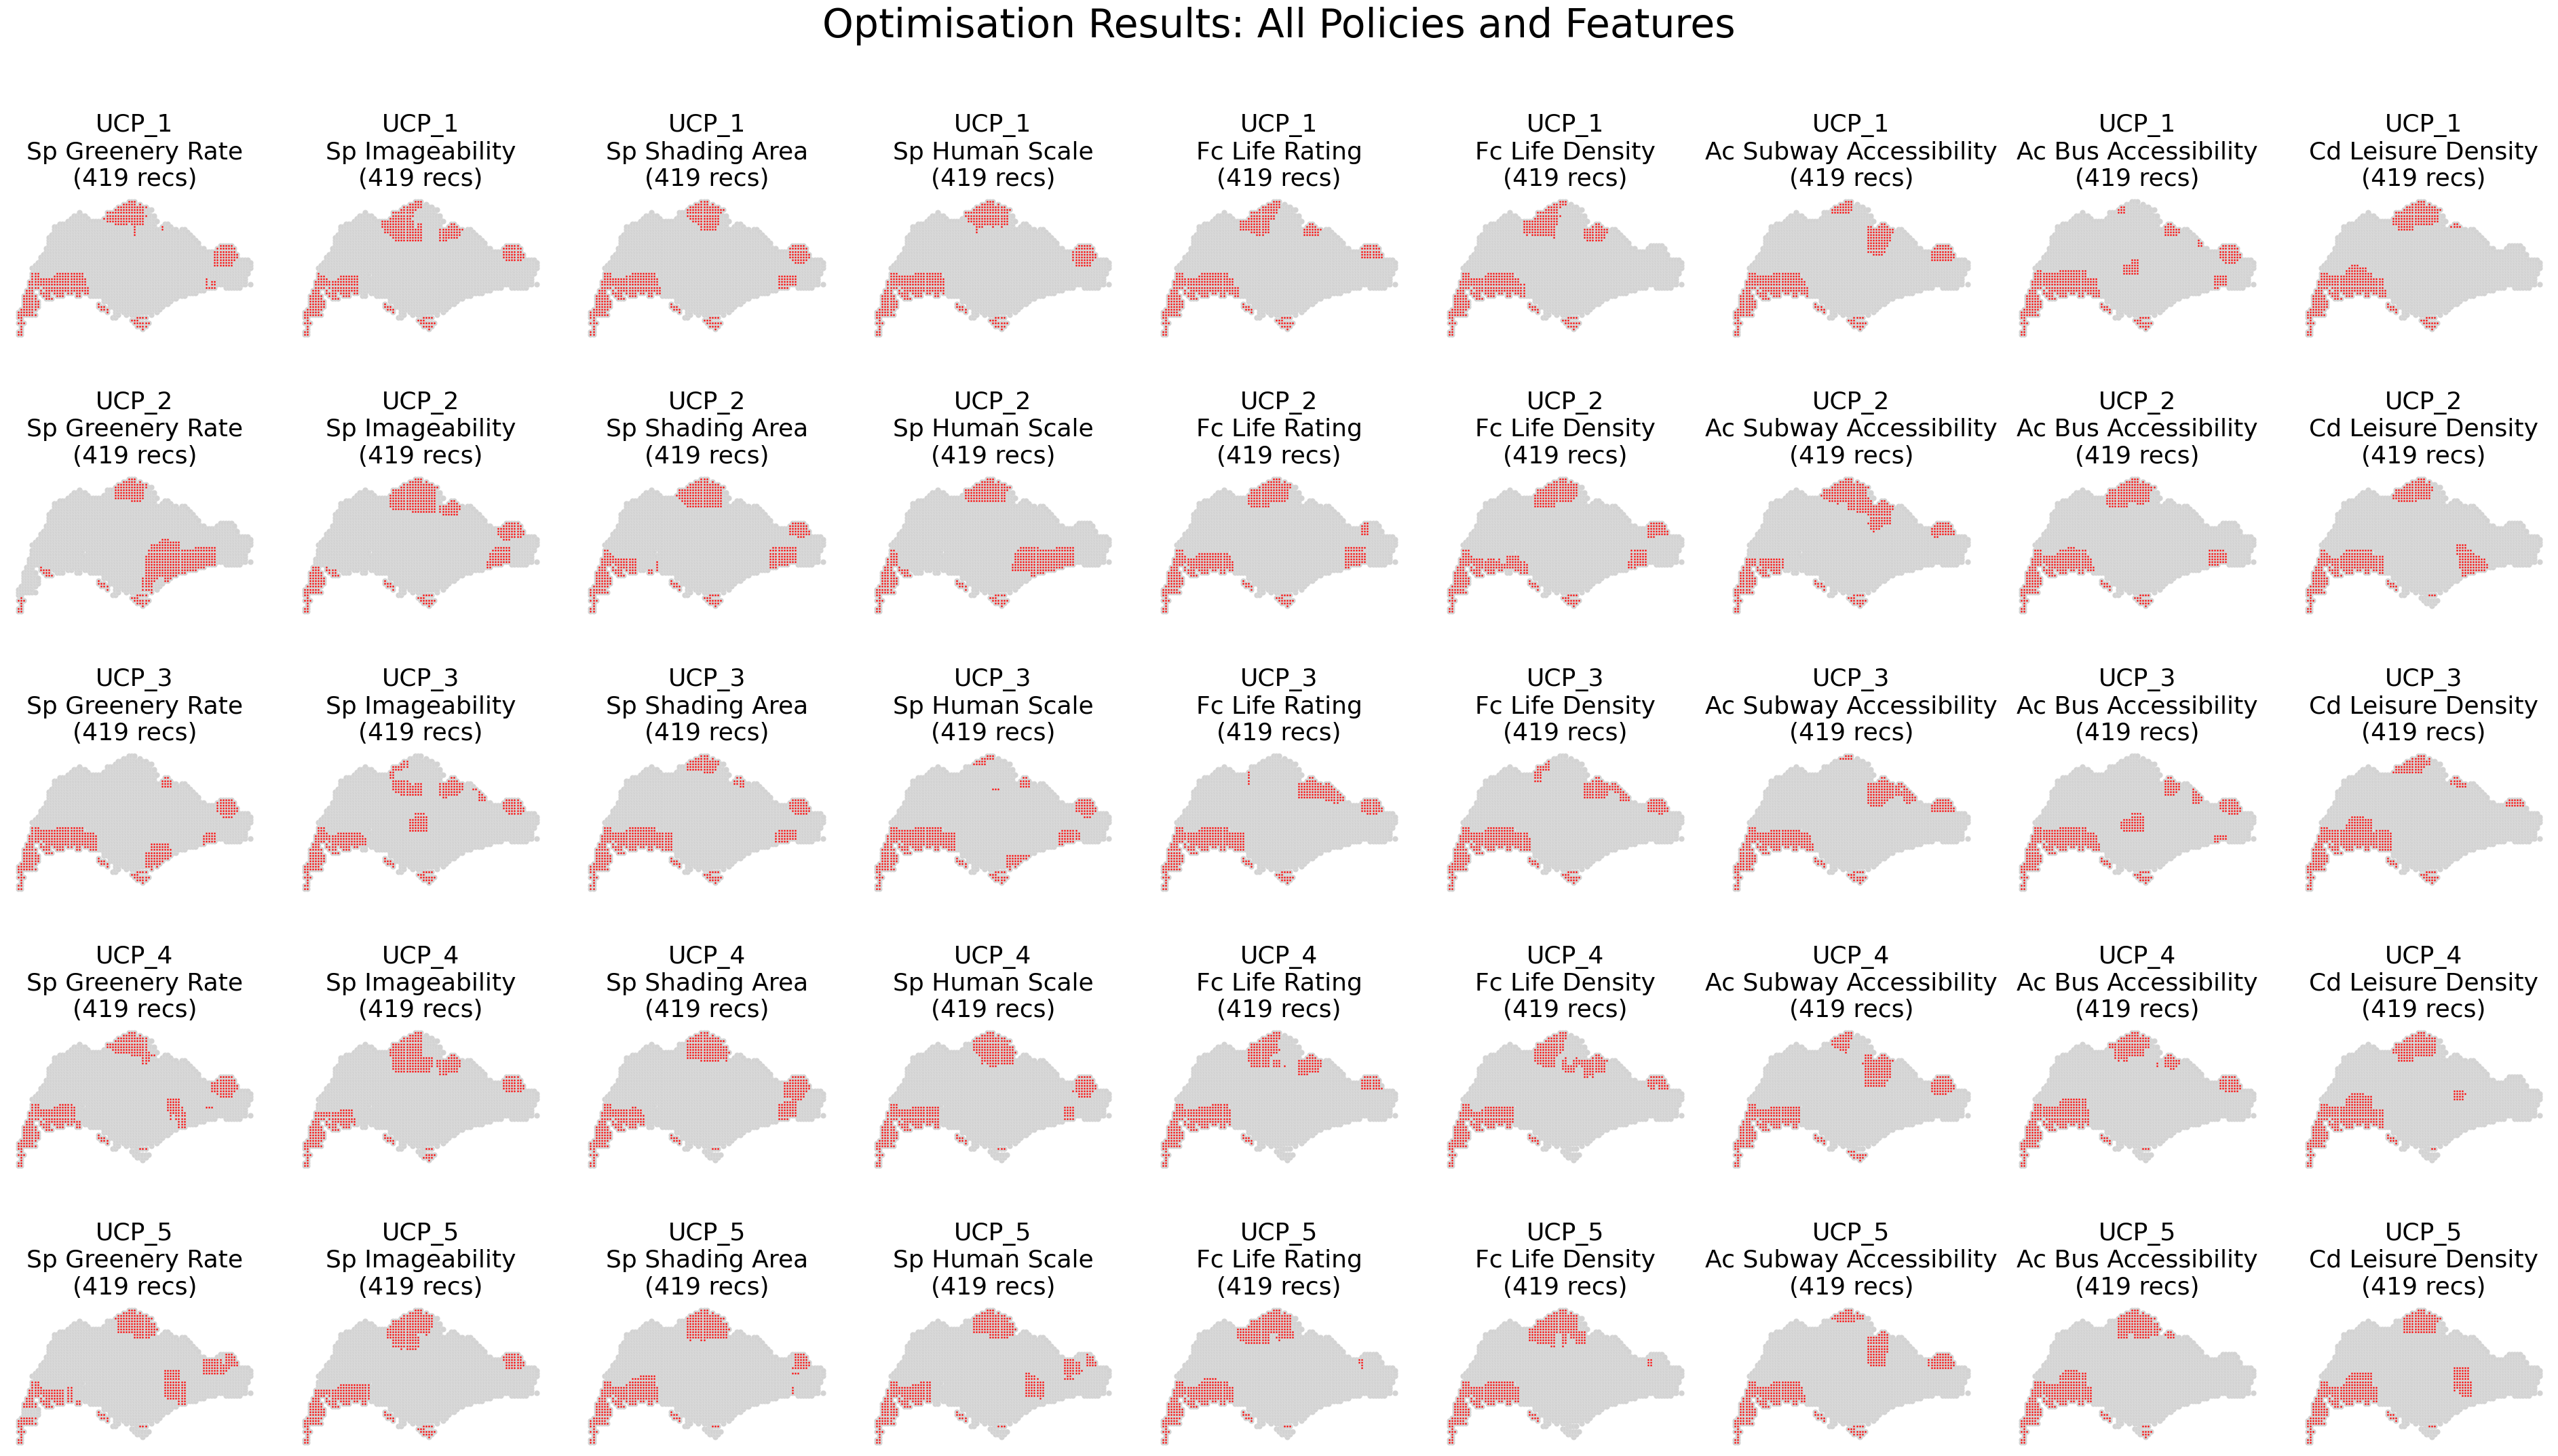


=== Recommendation Summary by Policy and Feature ===
Total spatial units in dataset: 2,096
Generating summary statistics...


Processing policies: 100%|██████████| 5/5 [00:00<00:00, 393.27it/s]


Summary Table:
Policy  SP_greenery_rate  SP_imageability  SP_shading_area  SP_human_scale  FC_life_rating  FC_life_density  AC_subway_accessibility  AC_bus_accessibility  CD_leisure_density  Total
 UCP_1               419              419              419             419             419              419                      419                   419                 419   3771
 UCP_2               419              419              419             419             419              419                      419                   419                 419   3771
 UCP_3               419              419              419             419             419              419                      419                   419                 419   3771
 UCP_4               419              419              419             419             419              419                      419                   419                 419   3771
 UCP_5               419              419              419             419

In [5]:
# Read the optimised data for all pUCI and all features, then visualise
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from tqdm import tqdm
from collections import Counter

# Output directory for optimisation results (same as code_7; change if using a different output folder)
OPTIMISATION_RESULT_DIR = "data/optimisation_result"

# Two naming conventions: use code_7 style (pUCI + full feature names) when output is optimisation_result_user
if "optimisation_result" in OPTIMISATION_RESULT_DIR:
    policy_names = [
        'pUCI_1_balanced_development',
        'pUCI_2_eco_livable',
        'pUCI_3_community_cohension',
        'pUCI_4_active_walkability',
        'pUCI_5_tourism_strategy'
    ]
    feature_names = [
        'SP_6-E_greenery_rate',
        'SP_1-D_imageability',
        'SP_7-E_shading_area',
        'SP_3-D_human_scale',
        'FC_3-R_life_rating',
        'FC_3-D_life_density',
        'AC_1-T_subway_accessibility',
        'AC_3-T_bus_accessibility',
        'CD_1-L_leisure_density'
    ]
    OPTIMISATION_FILE_PREFIX = "PUCI_ising_optimisation"
else:
    policy_names = [
        'UCP_1', 'UCP_2', 'UCP_3', 'UCP_4', 'UCP_5'
    ]
    feature_names = [
        'SP_greenery_rate',
        'SP_imageability',
        'SP_shading_area',
        'SP_human_scale',
        'FC_life_rating',
        'FC_life_density',
        'AC_subway_accessibility',
        'AC_bus_accessibility',
        'CD_leisure_density'
    ]
    OPTIMISATION_FILE_PREFIX = "ising_optimisation"

# Dictionary to store all loaded data
ucp_gdfs = {}

# Calculate total number of files to load
total_files = len(policy_names) * len(feature_names)

# Load data for each policy and feature combination with progress bar
print("Loading optimised data for all policies and features...")
with tqdm(total=total_files, desc="Loading files") as pbar:
    for policy in policy_names:
        ucp_gdfs[policy] = {}
        for feature in feature_names:
            input_name = f'{OPTIMISATION_FILE_PREFIX}_{policy}_{feature}'
            input_path = f'{OPTIMISATION_RESULT_DIR}/{input_name}.gpkg'
            
            try:
                gdf = gpd.read_file(input_path)
                ucp_gdfs[policy][feature] = gdf
                pbar.set_postfix_str(f"✓ {policy} - {feature}: {len(gdf)} records")
            except Exception as e:
                pbar.set_postfix_str(f"✗ {policy} - {feature}: Error")
                ucp_gdfs[policy][feature] = None
            
            pbar.update(1)

# Canonical names (optimisation_result state): unify keys and column names so downstream code always sees the same naming
CANONICAL_POLICY_NAMES = ['UCP_1', 'UCP_2', 'UCP_3', 'UCP_4', 'UCP_5']
CANONICAL_FEATURE_NAMES = [
    'SP_greenery_rate', 'SP_imageability', 'SP_shading_area', 'SP_human_scale',
    'FC_life_rating', 'FC_life_density', 'AC_subway_accessibility', 'AC_bus_accessibility', 'CD_leisure_density'
]
if "optimisation_result" in OPTIMISATION_RESULT_DIR:
    # Re-key ucp_gdfs to canonical policy/feature names and rename gdf columns (full_feature_* -> short_feature_*)
    full_to_short = {
        'SP_6-E_greenery_rate': 'SP_greenery_rate',
        'SP_1-D_imageability': 'SP_imageability',
        'SP_7-E_shading_area': 'SP_shading_area',
        'SP_3-D_human_scale': 'SP_human_scale',
        'FC_3-R_life_rating': 'FC_life_rating',
        'FC_3-D_life_density': 'FC_life_density',
        'AC_1-T_subway_accessibility': 'AC_subway_accessibility',
        'AC_3-T_bus_accessibility': 'AC_bus_accessibility',
        'CD_1-L_leisure_density': 'CD_leisure_density'
    }
    ucp_gdfs_canonical = {}
    for i, p in enumerate(policy_names):
        ucp_gdfs_canonical[CANONICAL_POLICY_NAMES[i]] = {}
        for j, f in enumerate(feature_names):
            gdf = ucp_gdfs[p][f]
            if gdf is not None:
                short_f = full_to_short.get(f, f)
                rename_cols = {}
                if f'{f}_recommendation' in gdf.columns:
                    rename_cols[f'{f}_recommendation'] = f'{short_f}_recommendation'
                if f'{f}_score' in gdf.columns:
                    rename_cols[f'{f}_score'] = f'{short_f}_score'
                if rename_cols:
                    gdf = gdf.rename(columns=rename_cols)
                ucp_gdfs_canonical[CANONICAL_POLICY_NAMES[i]][CANONICAL_FEATURE_NAMES[j]] = gdf
            else:
                ucp_gdfs_canonical[CANONICAL_POLICY_NAMES[i]][CANONICAL_FEATURE_NAMES[j]] = None
    ucp_gdfs = ucp_gdfs_canonical
    policy_names = CANONICAL_POLICY_NAMES
    feature_names = CANONICAL_FEATURE_NAMES
else:
    policy_names = CANONICAL_POLICY_NAMES
    feature_names = CANONICAL_FEATURE_NAMES

# Create comprehensive visualisation for all policies and features
if any(any(data is not None for data in policy_data.values()) for policy_data in ucp_gdfs.values()):

    from pathlib import Path
    FIG_DIR = Path("figure")
    FIG_DIR.mkdir(parents=True, exist_ok=True)

    # Font sizes for the 5×9 grid
    SUBTITLE_SIZE = 26
    SUPTITLE_SIZE = 42
    EMPTY_TEXT_SIZE = 20

    # Create a large subplot grid: policies as rows, features as columns
    # Taller rows so maps + 3-line titles breathe; width kept for readability
    fig, axes = plt.subplots(
        len(policy_names),
        len(feature_names),
        figsize=(len(feature_names) * 4.2, len(policy_names) * 4.4),
    )

    # Ensure axes is 2D array
    if len(policy_names) == 1:
        axes = axes.reshape(1, -1)
    elif len(feature_names) == 1:
        axes = axes.reshape(-1, 1)

    # Plot each policy-feature combination with progress bar
    total_plots = len(policy_names) * len(feature_names)
    with tqdm(total=total_plots, desc="Creating plots") as pbar:
        for i, policy in enumerate(policy_names):
            for j, feature in enumerate(feature_names):
                ax = axes[i, j]

                gdf = ucp_gdfs[policy][feature]

                if gdf is not None:
                    # Plot base map in light grey
                    gdf.plot(ax=ax, color="lightgrey", edgecolor="white", linewidth=0.1)

                    # Plot recommended locations in red
                    rec_col = f"{feature}_recommendation"
                    if rec_col in gdf.columns:
                        recommended = gdf[gdf[rec_col] == 1]
                        if not recommended.empty:
                            recommended.plot(ax=ax, color="red", markersize=1, alpha=0.8)
                            recommendation_count = len(recommended)
                        else:
                            recommendation_count = 0
                    else:
                        recommendation_count = 0

                    # Set title
                    feature_short = feature.replace("_", " ").title()
                    ax.set_title(
                        f"{policy}\n{feature_short}\n({recommendation_count} recs)",
                        fontsize=SUBTITLE_SIZE,
                        pad=10,
                    )
                else:
                    # If data not available, show empty plot with message
                    ax.text(
                        0.5,
                        0.5,
                        "Data\nNot Available",
                        ha="center",
                        va="center",
                        transform=ax.transAxes,
                        fontsize=EMPTY_TEXT_SIZE,
                        color="red",
                    )
                    ax.set_title(
                        f'{policy}\n{feature.replace("_", " ").title()}\n(No Data)',
                        fontsize=SUBTITLE_SIZE,
                        pad=10,
                    )

                ax.set_axis_off()
                pbar.set_postfix_str(f"Plotting {policy} - {feature}")
                pbar.update(1)

    plt.suptitle("Optimisation Results: All Policies and Features", fontsize=SUPTITLE_SIZE, y=0.99)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.subplots_adjust(top=0.88, hspace=0.42, wspace=0.12)
    fig.savefig(FIG_DIR / "code_8_optimisation_results.png", dpi=200, bbox_inches="tight")
    plt.show()
    
    # Create summary statistics table
    print("\n=== Recommendation Summary by Policy and Feature ===")
    
    # First, get total number of spatial units from any available dataset
    total_units = None
    for policy in policy_names:
        for feature in feature_names:
            gdf = ucp_gdfs[policy][feature]
            if gdf is not None:
                total_units = len(gdf)
                break
        if total_units is not None:
            break
    
    if total_units is not None:
        print(f"Total spatial units in dataset: {total_units:,}")
    else:
        print("Could not determine total number of spatial units")
    
    summary_data = []
    
    print("Generating summary statistics...")
    for policy in tqdm(policy_names, desc="Processing policies"):
        policy_summary = {'Policy': policy}
        total_recommendations = 0
        
        for feature in feature_names:
            gdf = ucp_gdfs[policy][feature]
            if gdf is not None:
                rec_col = f'{feature}_recommendation'
                if rec_col in gdf.columns:
                    count = len(gdf[gdf[rec_col] == 1])
                else:
                    count = 0
            else:
                count = 0
            
            policy_summary[feature] = count
            total_recommendations += count
        
        policy_summary['Total'] = total_recommendations
        summary_data.append(policy_summary)
    
    # Create and display summary DataFrame
    summary_df = pd.DataFrame(summary_data)
    print("\nSummary Table:")
    print(summary_df.to_string(index=False))
    
else:
    print("No data was successfully loaded!")

# Alias for Socio-Spatial Variation section (same structure: policy -> feature -> gdf)
all_policy_feature_data = ucp_gdfs


<a id="sec-2-3-single"></a>

### 2.3 Single policy × feature selector

Interactive single-map view (`SELECT_POLICY`, `SELECT_FEATURE`).


Map: UCP_2 × SP_greenery_rate  |  recommended (≥1.0): 419 / 2,096
Saved figure → figure/opt_map_UCP_2_SP_greenery_rate.png


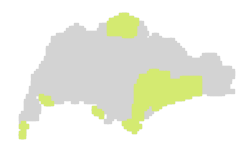

In [7]:
# ── Single policy × feature map (edit selectors) ─────────────────────────────
# Requires the optimisation load cell above (all_policy_feature_data / ucp_gdfs).
# SELECT_POLICY: UCP_1 … UCP_5  (pUCI policies, canonical names)
# SELECT_FEATURE: e.g. SP_greenery_rate, FC_life_density, …
# SELECT_COLOR:   any matplotlib colour / hex for recommended cells
# REC_MIN:        highlight where {feature}_recommendation >= REC_MIN
#                 (1.0 for binary single-run; try 0.5 for fractional P)

SELECT_POLICY = "UCP_2"
SELECT_FEATURE = "SP_greenery_rate"
SELECT_COLOR = "#D4EA71"
REC_MIN = 1.0
MARKER_SIZE = 5
FIG_W, FIG_H = 3, 3
SAVE_FIG = True
FIG_OUT = None   # None → figure/opt_map_{policy}_{feature}.png

import os
import matplotlib.pyplot as plt

_src = globals().get("all_policy_feature_data") or globals().get("ucp_gdfs")
if _src is None:
    raise RuntimeError("Run the optimisation load cell above first.")

if SELECT_POLICY not in _src:
    raise ValueError(f"Unknown policy {SELECT_POLICY!r}. Options: {list(_src.keys())}")
if SELECT_FEATURE not in _src[SELECT_POLICY]:
    raise ValueError(
        f"Unknown feature {SELECT_FEATURE!r} for {SELECT_POLICY}. "
        f"Options: {list(_src[SELECT_POLICY].keys())}"
    )

gdf = _src[SELECT_POLICY][SELECT_FEATURE]
if gdf is None or gdf.empty:
    raise RuntimeError(f"No data for {SELECT_POLICY} × {SELECT_FEATURE}")

rec_col = f"{SELECT_FEATURE}_recommendation"
if rec_col not in gdf.columns:
    raise KeyError(f"Column {rec_col!r} not in loaded gdf")

recommended = gdf[gdf[rec_col].astype(float) >= REC_MIN]
n_rec = len(recommended)
print(f"Map: {SELECT_POLICY} × {SELECT_FEATURE}  |  recommended (≥{REC_MIN}): {n_rec:,} / {len(gdf):,}")

fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))
ax.scatter(gdf.geometry.x, gdf.geometry.y, color="lightgrey", s=MARKER_SIZE, marker="s")
if n_rec:
    ax.scatter(
        recommended.geometry.x, recommended.geometry.y,
        color=SELECT_COLOR, s=MARKER_SIZE, marker="s",
    )

ax.set_xticks([]); ax.set_yticks([])
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_aspect("equal")

if SAVE_FIG:
    os.makedirs("figure", exist_ok=True)
    _out = FIG_OUT or os.path.join("figure", f"opt_map_{SELECT_POLICY}_{SELECT_FEATURE}.png")
    fig.savefig(_out, dpi=300, bbox_inches="tight")
    print(f"Saved figure → {_out}")

plt.show()

<a id="sec-3-ssv"></a>

## 3. Socio-spatial variation (SSV) indexing and visualisation

Overlap maps, SVI/SPVI/SSVI scatter plots and boxplots.


<a id="sec-3-1-overlap"></a>

### 3.1 Overlap in UCP results

Policy-unique vs shared recommendation zones.


In [8]:
import sys
from pathlib import Path
from collections import defaultdict
from itertools import product

import numpy as np
from tqdm.auto import tqdm

_REPO_ROOT = Path.cwd().resolve()
if str(_REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(_REPO_ROOT))
import importlib.util

_uvm_path = _REPO_ROOT / "scripts" / "uci_variation_metrics.py"
_spec = importlib.util.spec_from_file_location("uci_variation_metrics_repo", _uvm_path)
_uvm = importlib.util.module_from_spec(_spec)
assert _spec.loader is not None
_spec.loader.exec_module(_uvm)
discover_optimisation_run_dirs = _uvm.discover_optimisation_run_dirs
load_canonical_optimisation_gdfs = _uvm.load_canonical_optimisation_gdfs
compute_spatial_social_indices = _uvm.compute_spatial_social_indices


def aggregate_recommendations_multirun(policy_names, feature_names, run_dirs):
    run_gdfs_list = []
    for _rid, run_path in tqdm(run_dirs, desc="Load runs", unit="run"):
        gdfs, _, _ = load_canonical_optimisation_gdfs(run_path)
        run_gdfs_list.append(gdfs)
    n_runs = len(run_gdfs_list)
    if n_runs == 0:
        return {p: {f: None for f in feature_names} for p in policy_names}

    inv_n = 1.0 / float(n_runs)
    out = {p: {f: None for f in feature_names} for p in policy_names}
    combos = list(product(policy_names, feature_names))
    for policy, feature in tqdm(combos, desc="P(recommend) per pair", unit="pair"):
        votes = defaultdict(int)
        base_gdf = None
        for gdfs in run_gdfs_list:
            if policy not in gdfs or feature not in gdfs[policy]:
                continue
            gdf = gdfs[policy][feature]
            if gdf is None or gdf.empty:
                continue
            if base_gdf is None:
                base_gdf = gdf.copy()
            rec_col = f"{feature}_recommendation"
            if rec_col not in gdf.columns:
                continue
            rec_mask = gdf[rec_col].astype(float).eq(1.0).to_numpy()
            geoms = gdf.geometry.values
            for i in np.flatnonzero(rec_mask):
                geom = geoms[i]
                k = (round(geom.x, 6), round(geom.y, 6))
                votes[k] += 1
        if base_gdf is None:
            continue
        merged = base_gdf.copy()
        rec_col = f"{feature}_recommendation"
        merged[rec_col] = [
            votes[(round(geom.x, 6), round(geom.y, 6))] * inv_n for geom in merged.geometry.values
        ]
        out[policy][feature] = merged
    return out


DATA_ROOT = "data"
PLOT_P_EPS = 1e-9
run_dirs = discover_optimisation_run_dirs(DATA_ROOT)

if len(run_dirs) >= 1:
    print(
        "Overlap maps: multi-run P(recommend) in [0,1] from "
        f"{len(run_dirs)} folder(s) (no threshold on P)"
    )
    overlap_maps_data = aggregate_recommendations_multirun(policy_names, feature_names, run_dirs)
    _mr_tag = "_multirun" if len(run_dirs) > 1 else ""
else:
    print("Overlap maps: no optimisation_result_<n>; using all_policy_feature_data")
    overlap_maps_data = all_policy_feature_data
    _mr_tag = ""

print("Ready: overlap_maps_data, _mr_tag, PLOT_P_EPS — run next cell for figures.")


Overlap maps: multi-run P(recommend) in [0,1] from 50 folder(s) (no threshold on P)


Load runs:   0%|          | 0/50 [00:00<?, ?run/s]

P(recommend) per pair:   0%|          | 0/45 [00:00<?, ?pair/s]

Ready: overlap_maps_data, _mr_tag, PLOT_P_EPS — run next cell for figures.


Figure Title: Policy maps (colour strength ∝ P; light overlap grey ∝ mean P)
Calculated center point: (103.810542, 1.357035)
Saved figure → figure/ssv_policy_overlap_maps_multirun.png


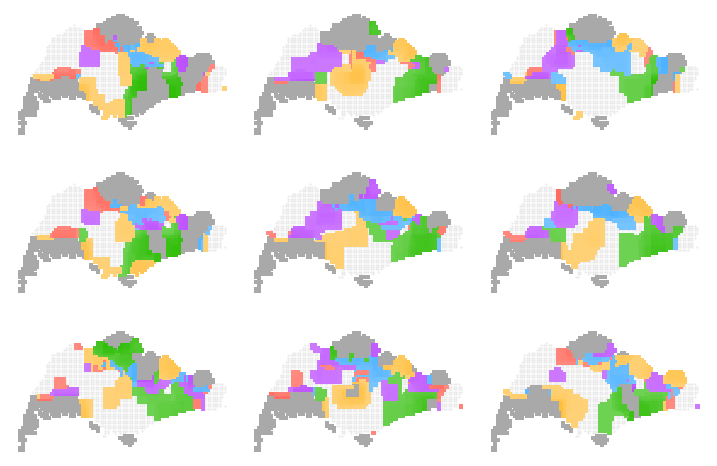

Figure Title: Expected policy overlap intensity (sum of P(recommend))
Saved figure → figure/ssv_overlap_intensity_maps_multirun.png


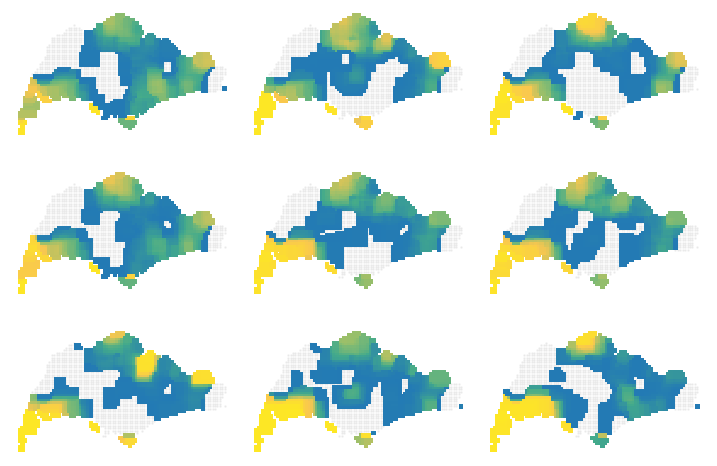

In [9]:
import geopandas as gpd

# --- Visualize overlap_maps_data (run previous cell first) ---
import os
from collections import defaultdict

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, to_rgb
import numpy as np

policy_colors = ["#FF5445", "#29BB00", "#FFBC37", "#35A7FF", "#B339FF"]

# Grey overlap only when >=2 policies have P >= this
OVERLAP_MIN_P = 0.25

# --- Tune colour contrast vs P (LinearSegmentedColormap per policy) ---
POLICY_P_GAMMA = 0.6        # <1 stretches low-P colours; adjust 0.4–1.0 to taste

# Overlap: fixed solid grey for all overlapping points
GRAY_COLOR = "#A9A9A9"      # adjust this single value to tune overlap grey


def _make_policy_cmap(hex_c, light_factor=0.65):
    """Build a sequential colormap: near-white tint → full hue."""
    r, g, b = to_rgb(hex_c)
    light = (1 - (1 - r) * light_factor,
             1 - (1 - g) * light_factor,
             1 - (1 - b) * light_factor)
    return LinearSegmentedColormap.from_list("", [light, (r, g, b)])


policy_cmaps = [_make_policy_cmap(c) for c in policy_colors]


def rgba_strong_policy(policy_idx, p):
    """Map p → colour using per-policy LinearSegmentedColormap. Fully opaque."""
    return policy_cmaps[policy_idx](float(np.power(np.clip(p, 0.0, 1.0), POLICY_P_GAMMA)))


def rgba_overlap_gray(_=None):
    """Fixed solid grey for all overlap points."""
    r, g, b = to_rgb(GRAY_COLOR)
    return (r, g, b, 1.0)


print("Figure Title: Policy maps (colour strength ∝ P; light overlap grey ∝ mean P)")
fig, axes = plt.subplots(3, 3, figsize=(9, 6))

all_geometries = []
for policy in policy_names:
    if policy in overlap_maps_data:
        for feature in feature_names:
            if feature in overlap_maps_data[policy]:
                feature_data = overlap_maps_data[policy][feature]
                if (
                    feature_data is not None
                    and hasattr(feature_data, "geometry")
                    and "geometry" in feature_data.columns
                ):
                    all_geometries.extend(feature_data.geometry.tolist())

if all_geometries:
    all_x_coords = [geom.x for geom in all_geometries]
    all_y_coords = [geom.y for geom in all_geometries]
    center_x = np.mean(all_x_coords)
    center_y = np.mean(all_y_coords)
    print(f"Calculated center point: ({center_x:.6f}, {center_y:.6f})")
else:
    center_x, center_y = 121.5, 31.2
    print(f"Using fallback center point: ({center_x}, {center_y})")

_ms = 11.0
for i, feature in enumerate(feature_names):
    row = i // 3
    col = i % 3
    ax = axes[row, col]

    for policy in policy_names:
        if policy in overlap_maps_data and feature in overlap_maps_data[policy]:
            feature_data = overlap_maps_data[policy][feature]
            if (
                feature_data is not None
                and hasattr(feature_data, "geometry")
                and "geometry" in feature_data.columns
            ):
                feature_data.plot(ax=ax, color="lightgray", alpha=0.3, markersize=0.6)
                break

    rec_col = f"{feature}_recommendation"
    coord_policy_p = defaultdict(list)

    for j, policy in enumerate(policy_names):
        if policy not in overlap_maps_data or feature not in overlap_maps_data[policy]:
            continue
        gdf = overlap_maps_data[policy][feature]
        if gdf is None or gdf.empty or rec_col not in gdf.columns:
            continue
        ps = gdf[rec_col].to_numpy(dtype=float)
        geoms = gdf.geometry.values
        for geom, p in zip(geoms, ps):
            if p <= PLOT_P_EPS:
                continue
            rk = (round(geom.x, 6), round(geom.y, 6))
            coord_policy_p[rk].append((j, float(p), float(geom.x), float(geom.y)))

    ov_xya = []
    solo = []
    for _rk, lst in coord_policy_p.items():
        x0, y0 = lst[0][2], lst[0][3]
        strong = [t for t in lst if t[1] >= OVERLAP_MIN_P]
        if len(strong) >= 2:
            ov_xya.append(
                (x0, y0, min(1.0, float(np.mean([pp for _, pp, _, _ in strong]))))
            )
        elif len(strong) == 1:
            j, p = strong[0][0], strong[0][1]
            solo.append((x0, y0, j, p))
        else:
            j, p, _, _ = max(lst, key=lambda t: t[1])
            solo.append((x0, y0, j, p))

    if ov_xya:
        ox, oy, _ = zip(*ov_xya)
        gray = rgba_overlap_gray()
        ax.scatter(ox, oy, s=_ms, marker="s", color=gray[:3], linewidths=0, zorder=3)

    if solo:
        sx, sy, sj, sp = zip(*solo)
        rgba_s = np.array([rgba_strong_policy(j, pp) for j, pp in zip(sj, sp)])
        ax.scatter(sx, sy, s=_ms, marker="s", c=rgba_s, linewidths=0, zorder=4)

    ax.set_xticks([])
    ax.set_yticks([])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_visible(False)
    ax.spines["left"].set_visible(False)

plt.subplots_adjust(hspace=0.1, wspace=0.05)
os.makedirs("figure", exist_ok=True)
fig1_path = os.path.join("figure", f"ssv_policy_overlap_maps{_mr_tag}.png")
fig.savefig(fig1_path, dpi=300, bbox_inches="tight")
print(f"Saved figure → {fig1_path}")
plt.show()

print("Figure Title: Expected policy overlap intensity (sum of P(recommend))")
fig, axes = plt.subplots(3, 3, figsize=(9, 6))

for i, feature in enumerate(feature_names):
    row = i // 3
    col = i % 3
    ax = axes[row, col]

    for policy in policy_names:
        if policy in overlap_maps_data and feature in overlap_maps_data[policy]:
            feature_data = overlap_maps_data[policy][feature]
            if (
                feature_data is not None
                and hasattr(feature_data, "geometry")
                and "geometry" in feature_data.columns
            ):
                feature_data.plot(ax=ax, color="lightgray", alpha=0.3, markersize=0.6)
                break

    rec_col = f"{feature}_recommendation"
    coord_sum = defaultdict(float)
    coord_geom = {}

    for policy in policy_names:
        if policy not in overlap_maps_data or feature not in overlap_maps_data[policy]:
            continue
        gdf = overlap_maps_data[policy][feature]
        if gdf is None or gdf.empty or rec_col not in gdf.columns:
            continue
        ps = gdf[rec_col].to_numpy(dtype=float)
        geoms = gdf.geometry.values
        for geom, p in zip(geoms, ps):
            if p <= PLOT_P_EPS:
                continue
            rk = (round(geom.x, 6), round(geom.y, 6))
            coord_sum[rk] += float(p)
            coord_geom[rk] = geom

    if coord_sum:
        xs = []
        ys = []
        intensities = []
        for rk, s in coord_sum.items():
            g = coord_geom[rk]
            xs.append(g.x)
            ys.append(g.y)
            intensities.append(s)
        vmax = max(float(np.max(intensities)), len(policy_names))
        cmap = LinearSegmentedColormap.from_list(
            "custom",
            ["#2279B5", "#43AA8B", "#90BE6D", "#F9C74F", "#FDE725"],
        )
        norm = plt.Normalize(vmin=0.0, vmax=vmax)
        rgba_i = cmap(norm(np.asarray(intensities)))
        ax.scatter(xs, ys, s=_ms, marker="s", c=rgba_i, linewidths=0)

    ax.set_xticks([])
    ax.set_yticks([])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_visible(False)
    ax.spines["left"].set_visible(False)

plt.subplots_adjust(hspace=0.1, wspace=0.05)
os.makedirs("figure", exist_ok=True)
fig2_path = os.path.join("figure", f"ssv_overlap_intensity_maps{_mr_tag}.png")
fig.savefig(fig2_path, dpi=300, bbox_inches="tight")
print(f"Saved figure → {fig2_path}")
plt.show()


<a id="sec-3-2-ssvi"></a>

### 3.2 SSVI maps and boxplots

Socio-spatial variation index across runs and features.


In [10]:
# Multi-run SPVI / SVI — raw arrays from compute_spatial_social_indices only.
# Global min–max on each raw channel over all runs × features, then (norm_rm + norm_rs) / 2 for SPVI
# and (norm_mu + norm_uc) / 2 for SVI (same rule as scripts.uci_variation_metrics.compute_spatial_social_indices),
# then a second global min–max on the SPVI and SVI tensors respectively.

import numpy as np
from tqdm.auto import tqdm

compute_spatial_social_indices = _uvm.compute_spatial_social_indices


def _global_mm01(a):
    """Min–max to [0, 1] using min/max over all elements of *a*."""
    a = np.asarray(a, dtype=float)
    if a.size == 0:
        return a
    lo, hi = float(np.min(a)), float(np.max(a))
    if hi > lo:
        return (a - lo) / (hi - lo)
    return np.zeros_like(a, dtype=float)


SSV_MULTIRUN_MAX = 50

_run_dirs_ssv = discover_optimisation_run_dirs(DATA_ROOT)[:SSV_MULTIRUN_MAX]

_rows = []
for _rid, _rpath in tqdm(_run_dirs_ssv, desc="SSV index runs", unit="run"):
    _gdfs, _pn, _fn = load_canonical_optimisation_gdfs(_rpath)
    if list(_pn) != list(policy_names) or list(_fn) != list(feature_names):
        print(f"[SSV] skip {_rpath}: policy/feature names do not match notebook")
        continue
    _out = compute_spatial_social_indices(_gdfs, policy_names, feature_names)
    _rows.append(
        {
            "rm": np.asarray(_out["raw_spatial_mean"], dtype=float),
            "rs": np.asarray(_out["raw_spatial_std_across_policies"], dtype=float),
            "mu": np.asarray(_out["raw_mean_unique_count"], dtype=float),
            "uc": np.asarray(_out["raw_unique_count_std_across_policies"], dtype=float),
        }
    )

if not _rows:
    print("[SSV] no optimisation_result_<n> folders — using primary all_policy_feature_data (single stack).")
    _out = compute_spatial_social_indices(all_policy_feature_data, policy_names, feature_names)
    _rows.append(
        {
            "rm": np.asarray(_out["raw_spatial_mean"], dtype=float),
            "rs": np.asarray(_out["raw_spatial_std_across_policies"], dtype=float),
            "mu": np.asarray(_out["raw_mean_unique_count"], dtype=float),
            "uc": np.asarray(_out["raw_unique_count_std_across_policies"], dtype=float),
        }
    )

_RM = np.stack([r["rm"] for r in _rows], axis=0)
_RS = np.stack([r["rs"] for r in _rows], axis=0)
_MU = np.stack([r["mu"] for r in _rows], axis=0)
_UC = np.stack([r["uc"] for r in _rows], axis=0)

_mean_rm = _RM.mean(axis=0)
_mean_rs = _RS.mean(axis=0)
_mean_mu = _MU.mean(axis=0)
_mean_uc = _UC.mean(axis=0)

_n_rm = _global_mm01(_RM)
_n_rs = _global_mm01(_RS)
_spvi_per_run = (_n_rm + _n_rs) / 2.0

_n_mu = _global_mm01(_MU)
_n_uc = _global_mm01(_UC)
_svi_per_run = (_n_mu + _n_uc) / 2.0

# Second global min–max on SPVI/SVI tensors so each combined index spans [0, 1] over runs×features.
_spvi_per_run = _global_mm01(_spvi_per_run)
_svi_per_run = _global_mm01(_svi_per_run)

_n_ssv, _nf = int(_spvi_per_run.shape[0]), int(_spvi_per_run.shape[1])

_mean_spvi = _spvi_per_run.mean(axis=0)
_mean_svi = _svi_per_run.mean(axis=0)
spatial_variation_indices = list(np.asarray(_mean_spvi, dtype=float))
social_variation_indices = list(np.asarray(_mean_svi, dtype=float))

spvi_per_run = np.asarray(_spvi_per_run, dtype=float)
svi_per_run = np.asarray(_svi_per_run, dtype=float)
ssvi_per_run = (spvi_per_run + svi_per_run) / 2.0

mu_per_run = _MU
uc_per_run = _UC
rm_per_run = _RM
rs_per_run = _RS

global_spatial_dispersions = list(np.asarray(_mean_rm, dtype=float))
global_dispersion_std = list(np.asarray(_mean_rs, dtype=float))
total_unique_counts = list(np.asarray(_mean_mu, dtype=float))
unique_count_stds = list(np.asarray(_mean_uc, dtype=float))

print(
    f"SSV multi-run: {_n_ssv} run(s) (cap {SSV_MULTIRUN_MAX}); global min–max per raw channel (runs×features), "
    f"then SPVI=(norm_rm+norm_rs)/2, SVI=(norm_mu+norm_uc)/2, then another global min–max on each of those tensors; "
    f"scatter uses mean over runs per feature."
)


SSV index runs:   0%|          | 0/50 [00:00<?, ?run/s]

SSV multi-run: 50 run(s) (cap 50); global min–max per raw channel (runs×features), then SPVI=(norm_rm+norm_rs)/2, SVI=(norm_mu+norm_uc)/2, then another global min–max on each of those tensors; scatter uses mean over runs per feature.


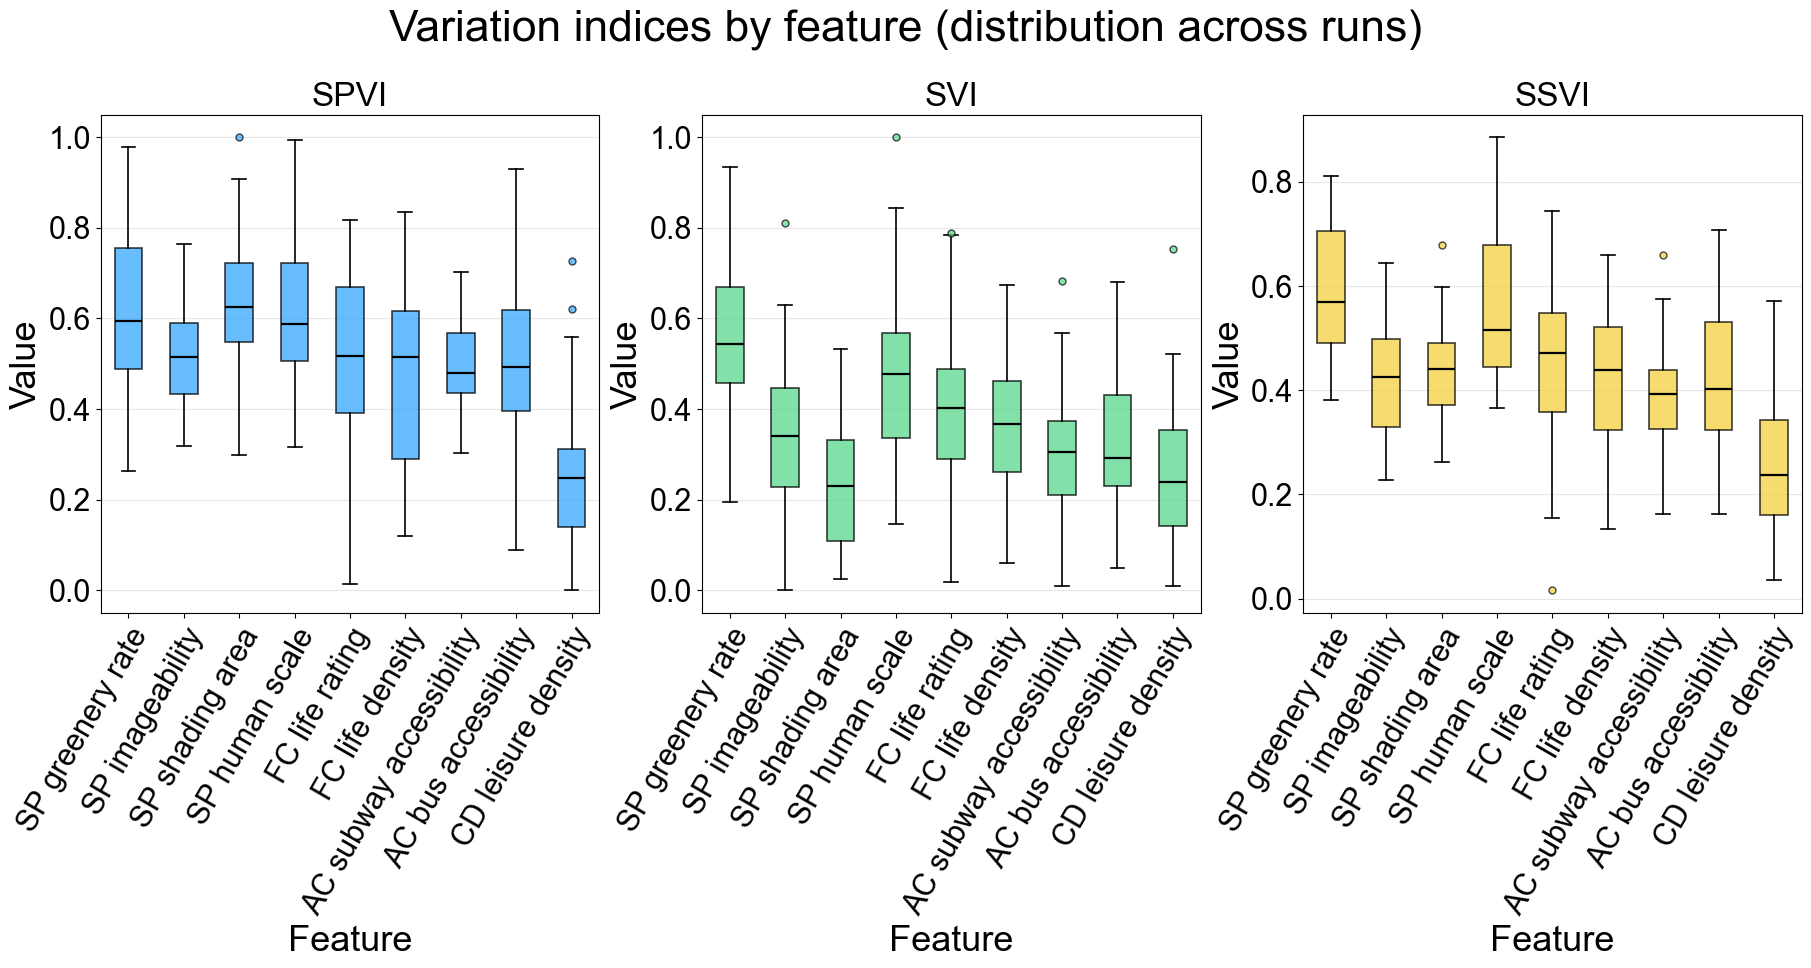

In [12]:
# Boxplots: SPVI, SVI, SSVI across optimisation runs for each feature (one row × three panels)
# X ticks: single-line labels (no "\n"), rotated 60° for readability.

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

_nf_box = int(spvi_per_run.shape[1])
_feat_labels = [str(f).replace("_", " ") for f in feature_names]

_data_spvi = [np.asarray(spvi_per_run[:, j], dtype=float).ravel() for j in range(_nf_box)]
_data_svi = [np.asarray(svi_per_run[:, j], dtype=float).ravel() for j in range(_nf_box)]
_data_ssvi = [np.asarray(ssvi_per_run[:, j], dtype=float).ravel() for j in range(_nf_box)]

plt.rcParams["font.family"] = "Arial"
plt.rcParams["axes.labelsize"] = 22
plt.rcParams["xtick.labelsize"] = 18
plt.rcParams["ytick.labelsize"] = 18
plt.rcParams["axes.titlesize"] = 24
plt.rcParams["legend.fontsize"] = 16

fig, axes = plt.subplots(1, 3, figsize=(18, 10), constrained_layout=True)

_titles = ("SPVI", "SVI", "SSVI")
_colors = ("#35A7FF", "#58D68D", "#F4D03F")  # blue, green, yellow
for ax, data, title, color in zip(axes, (_data_spvi, _data_svi, _data_ssvi), _titles, _colors):
    bp = ax.boxplot(data, patch_artist=True)
    for box in bp["boxes"]:
        box.set_facecolor(color)
        box.set_alpha(0.75)
        box.set_edgecolor("black")
        box.set_linewidth(1.2)
    for whisker in bp["whiskers"]:
        whisker.set_color("black")
        whisker.set_linewidth(1.2)
    for cap in bp["caps"]:
        cap.set_color("black")
        cap.set_linewidth(1.2)
    for median in bp["medians"]:
        median.set_color("black")
        median.set_linewidth(1.6)
    for flier in bp["fliers"]:
        flier.set(marker="o", markerfacecolor=color, markeredgecolor="black", alpha=0.7, markersize=5)
    ax.set_xticks(range(1, _nf_box + 1))
    ax.set_xticklabels(_feat_labels, rotation=60, ha="right", rotation_mode="anchor", fontsize=18)
    ax.set_title(title, fontsize=24)
    ax.set_ylabel("Value", fontsize=26)
    ax.set_xlabel("Feature", fontsize=26)
    ax.tick_params(axis="x", labelsize=22)
    ax.tick_params(axis="y", labelsize=22)
    ax.grid(True, axis="y", alpha=0.3)
    ax.set_box_aspect(1)  # keep the plotting box itself square (1:1)

fig.suptitle("Variation indices by feature (distribution across runs)", fontsize=32, y=0.95)

FIG_DIR = Path("figure")
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIG_DIR / "code_8_variation_indices_by_feature.png", dpi=200, bbox_inches="tight")
plt.show()


Figure Title: Socio-Spatial Variation Index
X axis: spatial variation index - SPVI
Y axis: social variation index - SVI
Each main point represents a feature


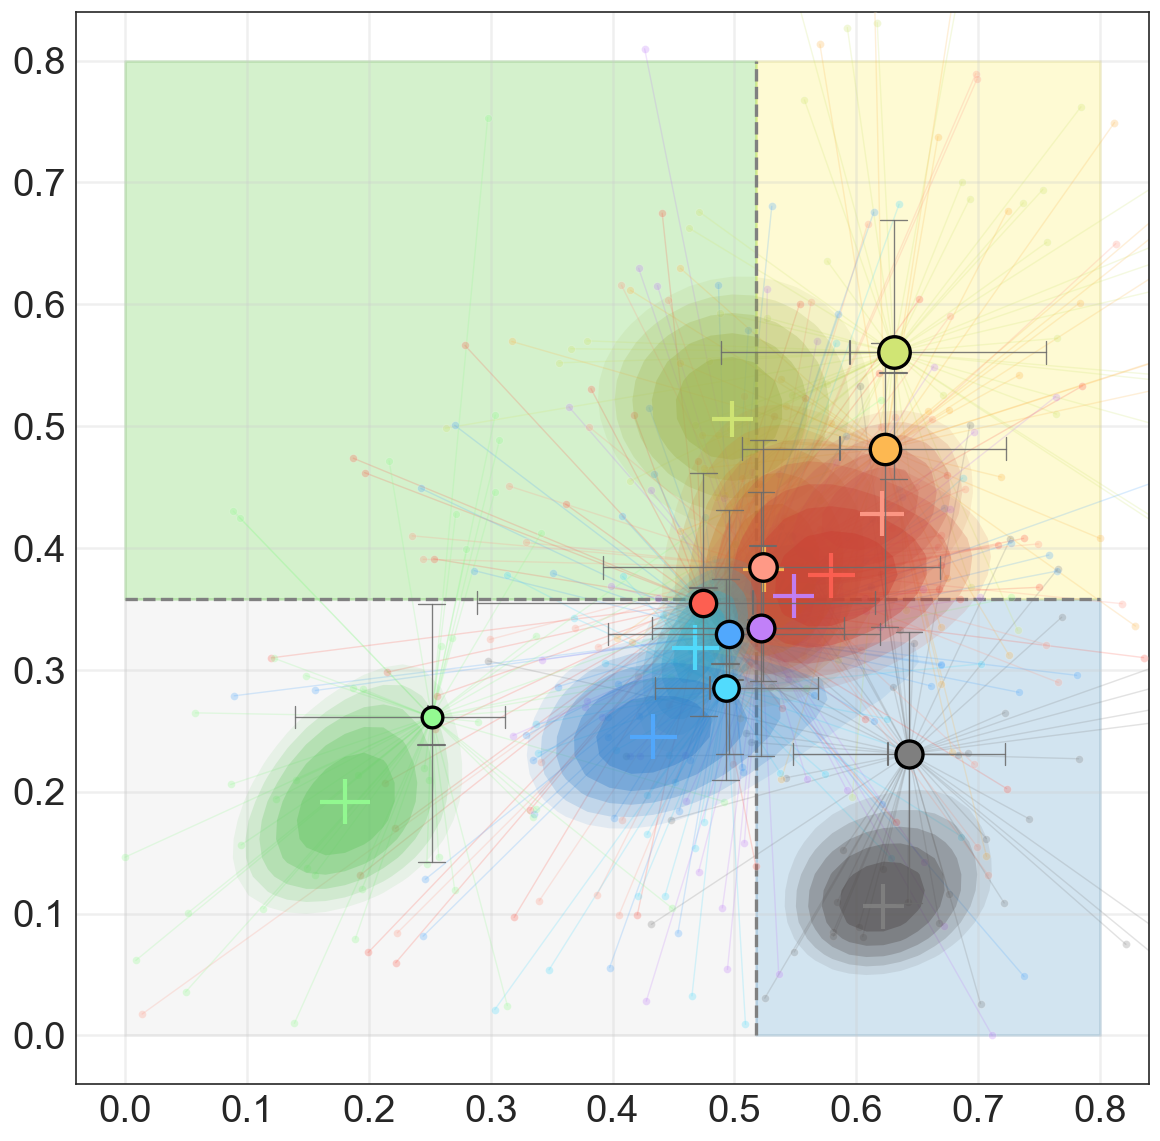

In [40]:
# ===== VISUALIZATION SSVI: Socio-Spatial Variation Index =====

print('Figure Title: Socio-Spatial Variation Index')
print('X axis: spatial variation index - SPVI')
print('Y axis: social variation index - SVI')
print('Each main point represents a feature')

# Set font properties for all text elements at the beginning
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 23  # Default font size
plt.rcParams['axes.labelsize'] = 30  # Axis label font size
plt.rcParams['xtick.labelsize'] = 23  # X-axis tick label font size
plt.rcParams['ytick.labelsize'] = 23  # Y-axis tick label font size
plt.rcParams['axes.titlesize'] = 32  # Title font size
annotation_fontsize = 12  # Annotation font size

# ===== AXIS RANGE & PADDING =====
# Set to (min, max) to pin the axis range; None = auto-detect from plotted data.
# Padding is white space outside the data viewport (no background colour there).
AXIS_XLIM = (0.0, 0.8)   # e.g. (0.0, 1.0)
AXIS_YLIM = (0.0, 0.8)   # e.g. (0.0, 1.0)
AXIS_PAD  = 0.05  # fractional padding beyond the viewport on each side
IQR_CAP_SCALE = 2.0         # length of Q1/Q3 end-cap ticks (multiplier of axis-range × 0.012)
IQR_LINE_WIDTH = 0.8        # line width for IQR bar and caps (median tick is 1.6× this)
CONTOUR_SHOW_KDE_CROSS = True   # draw a small + at the KDE density peak (per-run mean)
CONTOUR_SHOW_LINK      = False  # draw a dashed line from main marker to KDE centre
CONTOUR_CROSS_LW = 2.5   # 十字线宽（调大更粗）
CONTOUR_LINK_LW  = 2.5   # 连线线宽
MARKER_SIZE_BASE  = 0    # 所有点的底座尺寸（pts²），整体抬高
MARKER_SIZE_SCALE = 600   # 每单位指数值额外增加的尺寸

# ===== GRADIENT CONTOUR PARAMETERS (KDE halo around mean markers) =====
CONTOUR_MAX_SIGMA   = 0.5   # grid extent in std-devs of per-run spread
CONTOUR_N_LEVELS    = 5    # density contour layers (more → smoother gradient)
CONTOUR_ALPHA_INNER = 0.40  # alpha at innermost (highest-density) layer
CONTOUR_ALPHA_OUTER = 0.10  # alpha at outermost (lowest-density) layer
CONTOUR_DARKEN      = 0.2   # darken fill color (0 = original, 1 = max darkening)
CONTOUR_GRID_RES = 80  # 越大越平滑，但越慢

# Per-feature highlight: keys must match entries in feature_names. Large markers use solid fill;
# per-run small markers and connector lines use the same colour with higher transparency.
FEATURE_HIGHLIGHT_COLORS = {
        'SP_greenery_rate': '#D0E574',
        'SP_imageability': '#C180F8',
        'SP_shading_area': '#7F7F7F',
        'SP_human_scale': '#FDB851',
        'FC_life_rating': '#FF9986',
        'FC_life_density': '#FD5F51',
        'AC_subway_accessibility': '#51DBFD',
        'AC_bus_accessibility': '#51A8FD',
        'CD_leisure_density': '#93FA91',
}
FEATURE_HIGHLIGHT_SMALL_ALPHA = 0.28
FEATURE_HIGHLIGHT_LINE_ALPHA = 0.22

# Dispersion helper: marginal Q1/Q3 ticks + IQR cross at (cx, cy). KDE gradient removed.
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize


def _dispersion_whiskers_and_rings(
    ax,
    cx,
    cy,
    x_runs,
    y_runs,
    ring_color,
    whisker_color="0.42",
    tick_scale_x=None,
    tick_scale_y=None,
    z_rings=5.3,
    z_lines=5.5,
    **kwargs,
):
    """2-D cross box-whisker plot centred at (cx, cy).

    Each axis arm is drawn as a standard 1-D boxplot:
      - thin whisker line from min to max
      - cap ticks at min and max (perpendicular to the arm)
      - filled white box (rectangle) spanning Q1 to Q3
      - median line inside the box
    """
    _ = ring_color, z_rings, kwargs
    x_runs = np.asarray(x_runs, dtype=float).ravel()
    y_runs = np.asarray(y_runs, dtype=float).ravel()
    if x_runs.size <= 1:
        return
    q1x, medx, q3x = np.percentile(x_runs, [25, 50, 75])
    q1y, medy, q3y = np.percentile(y_runs, [25, 50, 75])
    if tick_scale_x is None:
        tick_scale_x = max(np.ptp(ax.get_xlim()), 1e-12) * 0.012
    if tick_scale_y is None:
        tick_scale_y = max(np.ptp(ax.get_ylim()), 1e-12) * 0.012
    # Cap half-sizes (perpendicular to each arm)
    cap_y = max(float(tick_scale_y) * IQR_CAP_SCALE, 1e-12)
    cap_x = max(float(tick_scale_x) * IQR_CAP_SCALE, 1e-12)

    kw = dict(color=whisker_color, clip_on=True)

    # ── X arm: Q1──median──Q3 with end caps ──────────────────────────────────
    _lw = IQR_LINE_WIDTH
    ax.plot([q1x, q3x], [cy, cy], linewidth=_lw, alpha=0.88, zorder=z_lines, **kw)
    ax.plot([q1x, q1x], [cy - cap_y, cy + cap_y], linewidth=_lw, alpha=0.88, zorder=z_lines, **kw)
    ax.plot([q3x, q3x], [cy - cap_y, cy + cap_y], linewidth=_lw, alpha=0.88, zorder=z_lines, **kw)
    ax.plot([medx, medx], [cy - cap_y, cy + cap_y],
            linewidth=_lw * 1.6, alpha=0.95, zorder=z_lines + 0.05, **kw)

    # ── Y arm: Q1──median──Q3 with end caps ──────────────────────────────────
    ax.plot([cx, cx], [q1y, q3y], linewidth=_lw, alpha=0.88, zorder=z_lines, **kw)
    ax.plot([cx - cap_x, cx + cap_x], [q1y, q1y], linewidth=_lw, alpha=0.88, zorder=z_lines, **kw)
    ax.plot([cx - cap_x, cx + cap_x], [q3y, q3y], linewidth=_lw, alpha=0.88, zorder=z_lines, **kw)
    ax.plot([cx - cap_x, cx + cap_x], [medy, medy],
            linewidth=_lw * 1.6, alpha=0.95, zorder=z_lines + 0.05, **kw)


def _gradient_contour(ax, cx, cy, x_runs, y_runs, color,
                      max_sigma=None, n_levels=None,
                      alpha_inner=None, alpha_outer=None,
                      darken=None, zorder=4.5,
                      show_kde_cross=None, show_link=None):
    """KDE-based gradient contour halo following the true per-run density shape.

    The evaluation grid extends well beyond max_sigma so its edges have near-zero
    density and never produce a rectangular clip.  The outermost visible contour
    threshold is set by sampling the KDE on the max_sigma ring around (cx, cy),
    so CONTOUR_MAX_SIGMA controls the spatial reach while the shape follows the data.
    """
    from scipy.stats import gaussian_kde
    import colorsys
    import matplotlib.colors as mcolors
    _ms = CONTOUR_MAX_SIGMA   if max_sigma   is None else max_sigma
    _nl = CONTOUR_N_LEVELS    if n_levels    is None else n_levels
    _ai = CONTOUR_ALPHA_INNER if alpha_inner is None else alpha_inner
    _ao = CONTOUR_ALPHA_OUTER if alpha_outer is None else alpha_outer
    _dk = CONTOUR_DARKEN      if darken      is None else darken
    _gr = CONTOUR_GRID_RES
    x_runs = np.asarray(x_runs, dtype=float).ravel()
    y_runs = np.asarray(y_runs, dtype=float).ravel()
    if x_runs.size < 3:
        return
    rgb_orig = mcolors.to_rgb(color)  # original colour (for cross marker)
    rgb = rgb_orig
    if _dk > 0:
        h, s, v = colorsys.rgb_to_hsv(*rgb)
        rgb = colorsys.hsv_to_rgb(h, min(1.0, s + _dk * 0.4), max(0.0, v - _dk))
    try:
        kde = gaussian_kde(np.vstack([x_runs, y_runs]))
    except Exception:
        return
    sx = float(np.std(x_runs))
    sy = float(np.std(y_runs))
    if sx < 1e-12 or sy < 1e-12:
        return
    # Grid centered on the per-run cloud; extended far beyond max_sigma so
    # density at grid edges ≈ 0 and no rectangular boundary is ever visible.
    xc = float(np.mean(x_runs))
    yc = float(np.mean(y_runs))
    ext = max(_ms + 3.0, 4.0)
    pad_x, pad_y = ext * sx, ext * sy
    xx, yy = np.meshgrid(
        np.linspace(xc - pad_x, xc + pad_x, _gr),
        np.linspace(yc - pad_y, yc + pad_y, _gr),
    )
    zz = kde(np.vstack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
    # Outer threshold: mean KDE density sampled on the max_sigma ring around (cx, cy).
    # This ties the visible boundary to max_sigma while letting the shape be free.
    n_ring = 48
    ring_a = np.linspace(0, 2 * np.pi, n_ring, endpoint=False)
    ring_pts = np.vstack([cx + _ms * sx * np.cos(ring_a),
                          cy + _ms * sy * np.sin(ring_a)])
    outer_density = float(np.mean(kde(ring_pts)))
    zz_min, zz_max = float(zz.min()), float(zz.max())
    zz_norm = (zz - zz_min) / (zz_max - zz_min + 1e-12)
    outer_norm = float(np.clip(
        (outer_density - zz_min) / (zz_max - zz_min + 1e-12), 0.01, 0.95
    ))
    thresholds = np.linspace(outer_norm, 1.0, _nl + 2)[1:-1]
    for i, thresh in enumerate(thresholds):
        t = i / max(_nl - 1, 1)
        alpha = _ao + (_ai - _ao) * t
        try:
            ax.contourf(
                xx, yy, zz_norm,
                levels=[float(thresh), 1.0 + 1e-6],
                colors=[(*rgb, alpha)],
                zorder=zorder,
                antialiased=True,
            )
        except Exception:
            pass
    _show_cross = CONTOUR_SHOW_KDE_CROSS if show_kde_cross is None else show_kde_cross
    _show_link  = CONTOUR_SHOW_LINK      if show_link       is None else show_link
    # KDE peak (mode): location of maximum density in the evaluated grid
    peak_idx = np.unravel_index(np.argmax(zz), zz.shape)
    xp = float(xx[peak_idx])
    yp = float(yy[peak_idx])
    # Small + cross at KDE density peak (mode), not the mean
    if _show_cross:
        # Equal visual arm length: same fraction of each axis data range
        _xl = ax.get_xlim(); _yl = ax.get_ylim()
        cs_x = (_xl[1] - _xl[0]) * 0.012
        cs_y = (_yl[1] - _yl[0]) * 0.012
        kw_cross = dict(color=rgb_orig, linewidth=CONTOUR_CROSS_LW, alpha=0.96,
                        zorder=5.0, clip_on=True, solid_capstyle="butt")
        ax.plot([xp - cs_x, xp + cs_x], [yp, yp], **kw_cross)
        ax.plot([xp, xp], [yp - cs_y, yp + cs_y], **kw_cross)
    # Optional dashed connector from main marker (mean) to KDE peak (mode)
    if _show_link and (abs(cx - xp) > 1e-10 or abs(cy - yp) > 1e-10):
        import colorsys as _cs3
        import matplotlib.colors as _mc3
        _rgb3 = _mc3.to_rgb(rgb) if not isinstance(rgb, tuple) or len(rgb) == 4 else rgb[:3]
        _h3, _s3, _v3 = _cs3.rgb_to_hsv(*_rgb3)
        link_color = _cs3.hsv_to_rgb(_h3, min(1.0, _s3 + 0.2), max(0.0, _v3 - 0.25))
        ax.plot([cx, xp], [cy, yp], color=link_color, linewidth=CONTOUR_LINK_LW,
                linestyle=(0, (5, 2)), alpha=0.82, zorder=4.8, clip_on=True)


# SSVI = (SPVI + SVI) / 2 — upstream: raw from compute_spatial_social_indices, one global min–max per raw channel, then two-stage SPVI/SVI (same recipe as script)
_spvi_plot = np.asarray(spatial_variation_indices, dtype=float)
_svi_plot = np.asarray(social_variation_indices, dtype=float)
ssvi = (_spvi_plot + _svi_plot) / 2.0

marker_sizes = MARKER_SIZE_BASE + ssvi * MARKER_SIZE_SCALE  # base + SSVI-scaled size

# Create standalone socio-spatial variation map with adjusted aspect ratio to account for colorbar
fig, ax = plt.subplots(1, 1, figsize=(12, 10))

ax.grid(True, alpha=0.3)

# Per-run SPVI/SVI (raw → same global bounds + two-stage as main point) + segments to mean
if "spvi_per_run" in globals():
    _spm = np.asarray(spatial_variation_indices, dtype=float)
    _svm = np.asarray(social_variation_indices, dtype=float)
    _nr, _nf = spvi_per_run.shape
    for _fi in range(_nf):
        _fname = feature_names[_fi]
        _hc = FEATURE_HIGHLIGHT_COLORS.get(_fname)
        if _hc:
            _lc, _la = _hc, FEATURE_HIGHLIGHT_LINE_ALPHA
            _sc, _sa = _hc, FEATURE_HIGHLIGHT_SMALL_ALPHA
        else:
            _lc, _la = "0.55", 0.35
            _sc, _sa = "#777777", 0.55
        _xr = spvi_per_run[:, _fi]
        _yr = svi_per_run[:, _fi]
        if _nr > 1:
            for _rr in range(_nr):
                ax.plot(
                    [_xr[_rr], _spm[_fi]],
                    [_yr[_rr], _svm[_fi]],
                    color=_lc,
                    alpha=_la,
                    linewidth=0.85,
                    zorder=2,
                )
        ax.scatter(
            _xr,
            _yr,
            s=22,
            c=_sc,
            alpha=_sa,
            zorder=4,
            edgecolors="white",
            linewidths=0.35,
        )

# Gradient contour halos around mean markers (based on per-run spread)
if "spvi_per_run" in globals() and spvi_per_run.shape[0] > 1:
    _norm_ssvi_gc = Normalize(0, 1)
    for _i in range(len(feature_names)):
        _fname = feature_names[_i]
        _hc = FEATURE_HIGHLIGHT_COLORS.get(_fname)
        _gc = _hc if _hc else plt.cm.viridis(float(_norm_ssvi_gc(ssvi[_i])))
        _gradient_contour(
            ax,
            float(_spvi_plot[_i]),
            float(_svi_plot[_i]),
            spvi_per_run[:, _i],
            svi_per_run[:, _i],
            _gc,
        )

# Marginal Q1/Q3 ticks + IQR cross (under main markers)
if "spvi_per_run" in globals() and spvi_per_run.shape[0] > 1:
    _tsx = max(float(np.ptp(_spvi_plot)), 1e-9) * 0.014
    _tsy = max(float(np.ptp(_svi_plot)), 1e-9) * 0.014
    _norm_ssvi_vis = Normalize(0, 1)
    for _i in range(len(feature_names)):
        _dispersion_whiskers_and_rings(
            ax,
            float(_spvi_plot[_i]),
            float(_svi_plot[_i]),
            spvi_per_run[:, _i],
            svi_per_run[:, _i],
            FEATURE_HIGHLIGHT_COLORS[feature_names[_i]]
            if feature_names[_i] in FEATURE_HIGHLIGHT_COLORS
            else plt.cm.viridis(float(_norm_ssvi_vis(ssvi[_i]))),
            tick_scale_x=_tsx,
            tick_scale_y=_tsy,
        )

# Mean markers: cmap for default features; solid colours for FEATURE_HIGHLIGHT_COLORS
_hi_mask = np.array([f in FEATURE_HIGHLIGHT_COLORS for f in feature_names], dtype=bool)
scatter = None
if (~_hi_mask).any():
    scatter = ax.scatter(
        _spvi_plot[~_hi_mask],
        _svi_plot[~_hi_mask],
        s=marker_sizes[~_hi_mask],
        c=ssvi[~_hi_mask],
        cmap="viridis",
        vmin=0,
        vmax=1,
        edgecolor="black",
        linewidth=2,
        zorder=7,
    )
for _i in np.flatnonzero(_hi_mask):
    ax.scatter(
        [_spvi_plot[_i]],
        [_svi_plot[_i]],
        s=marker_sizes[_i],
        c=[FEATURE_HIGHLIGHT_COLORS[feature_names[_i]]],
        edgecolor="black",
        linewidth=2,
        zorder=8,
    )

# Add colorbar for socio-spatial variation index on the bottom with reduced height
# if scatter is not None:
#     cbar = plt.colorbar(scatter, ax=ax, shrink=0.6, location="right", pad=0.03)
# else:
#     _sm = ScalarMappable(norm=Normalize(0, 1), cmap="viridis")
#     _sm.set_array([])
#     cbar = plt.colorbar(_sm, ax=ax, shrink=0.6, location="right", pad=0.03)
# # cbar.set_label('Socio-Spatial Variation Index', fontsize=24)
# # Set colorbar tick label font size to match x and y axis
# cbar.ax.tick_params(labelsize=23)

# ax.set_xlabel('Spatial Variation Index', fontsize=30, fontfamily='Arial')
# ax.set_ylabel('Social Variation Index', fontsize=30, fontfamily='Arial')

# Remove equal aspect ratio since x and y axes have different scales
ax.set_box_aspect(1)

# ── Viewport + white padding ──────────────────────────────────────────────────
_mean_social  = np.mean(social_variation_indices)  if len(social_variation_indices)  > 0 else None
_mean_spatial = np.mean(spatial_variation_indices) if len(spatial_variation_indices) > 0 else None
_auto_xl = ax.get_xlim()
_auto_yl = ax.get_ylim()
_vx0, _vx1 = AXIS_XLIM if AXIS_XLIM is not None else _auto_xl
_vy0, _vy1 = AXIS_YLIM if AXIS_YLIM is not None else _auto_yl
_px = (_vx1 - _vx0) * AXIS_PAD
_py = (_vy1 - _vy0) * AXIS_PAD
ax.set_xlim(_vx0 - _px, _vx1 + _px)
ax.set_ylim(_vy0 - _py, _vy1 + _py)
mean_social  = _mean_social
mean_spatial = _mean_spatial

# Quadrant dividing lines (clipped to viewport, not full axes)
if mean_social is not None:
    ax.plot([_vx0, _vx1], [mean_social, mean_social],
            color='gray', linestyle='--', linewidth=2, zorder=3)
if mean_spatial is not None:
    ax.plot([mean_spatial, mean_spatial], [_vy0, _vy1],
            color='gray', linestyle='--', linewidth=2, zorder=3)

# Colored quadrant backgrounds – only within viewport; padding stays white
alpha_bg = 0.2
if mean_social is not None and mean_spatial is not None:
    ax.fill_between([_vx0, mean_spatial], _vy0, mean_social,
                    color='lightgray', alpha=alpha_bg, zorder=0)
    ax.fill_between([mean_spatial, _vx1], _vy0, mean_social,
                    color='#2279B5', alpha=alpha_bg, zorder=0)
    ax.fill_between([_vx0, mean_spatial], mean_social, _vy1,
                    color='#29BB00', alpha=alpha_bg, zorder=0)
    ax.fill_between([mean_spatial, _vx1], mean_social, _vy1,
                    color='#FDE725', alpha=alpha_bg, zorder=0)

# Add quadrant annotations with colored backgrounds
# ax.text(0.95, 0.95, 'High Social\nHigh Spatial', transform=ax.transAxes, 
#         ha='right', va='top', fontsize=annotation_fontsize, fontweight='bold',
#         bbox=dict(boxstyle='round,pad=0.3', facecolor='#FDE725', alpha=0.7))
# ax.text(0.05, 0.95, 'High Social\nLow Spatial', transform=ax.transAxes, 
#         ha='left', va='top', fontsize=annotation_fontsize, fontweight='bold',
#         bbox=dict(boxstyle='round,pad=0.3', facecolor='#29BB00', alpha=0.7))
# ax.text(0.95, 0.05, 'Low Social\nHigh Spatial', transform=ax.transAxes, 
#         ha='right', va='bottom', fontsize=annotation_fontsize, fontweight='bold',
#         bbox=dict(boxstyle='round,pad=0.3', facecolor='#2279B5', alpha=0.7))
# ax.text(0.05, 0.05, 'Low Social\nLow Spatial', transform=ax.transAxes, 
#         ha='left', va='bottom', fontsize=annotation_fontsize, fontweight='bold',
#         bbox=dict(boxstyle='round,pad=0.3', facecolor='lightgray', alpha=0.7))

plt.tight_layout()
plt.show()


<a id="sec-3-3-svi"></a>

### 3.3 SVI visualisation

Social variation: unique-count mean vs std.


Figure Title: Social Variation Index
X axis: mean unique count (across policies)
Y axis: unique-count std (across policies)
Each main point represents a feature


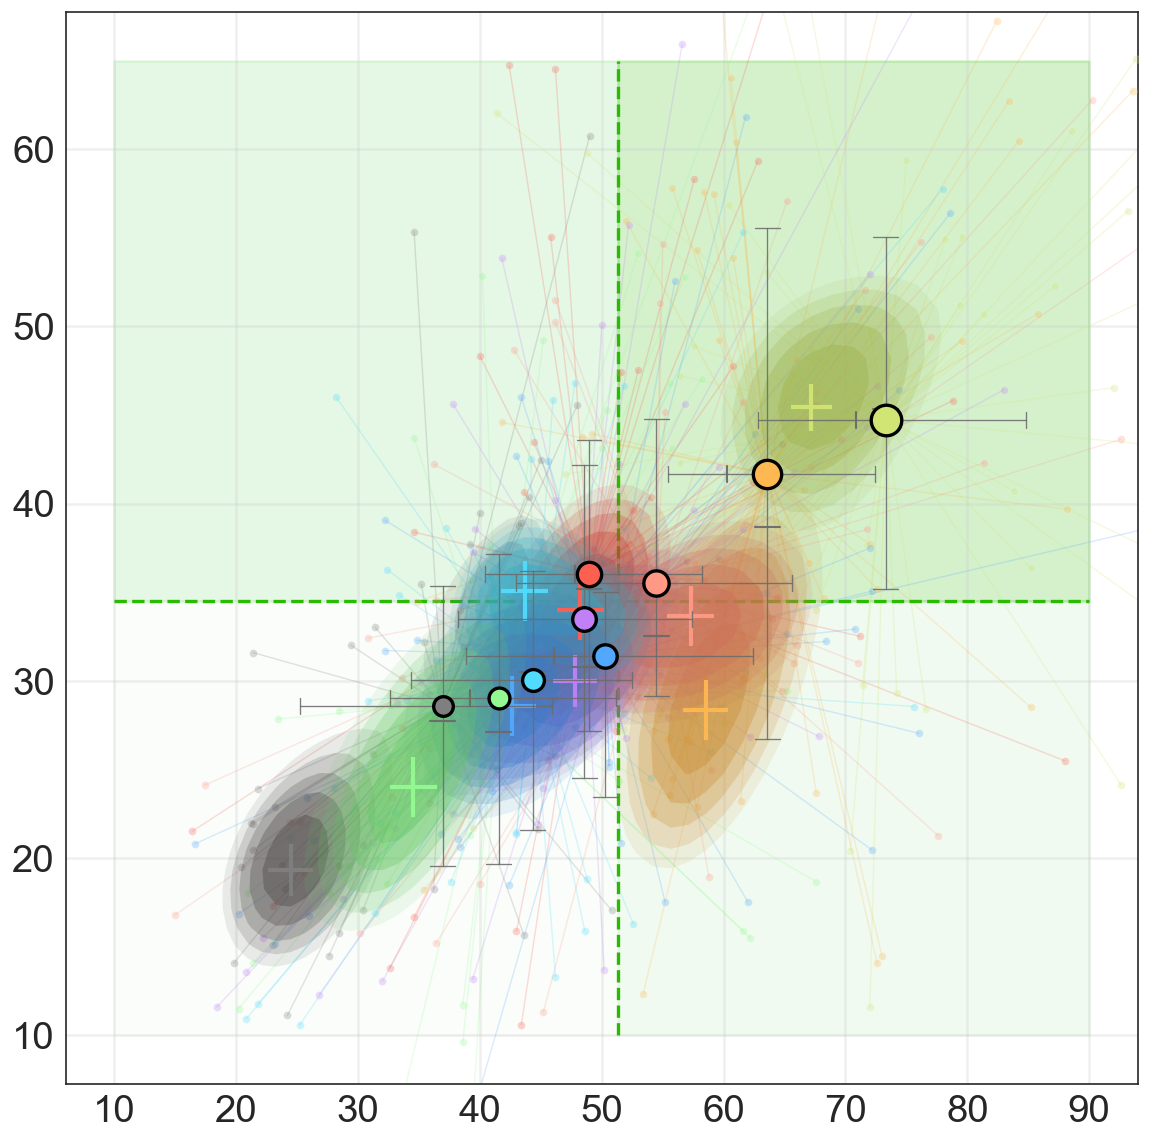

In [41]:
# ===== VISUALIZATION SVI: Social Variation Map (mean unique count vs unique-count std) =====

print('Figure Title: Social Variation Index')
print('X axis: mean unique count (across policies)')
print('Y axis: unique-count std (across policies)')
print('Each main point represents a feature')

# Set font properties for all text elements at the beginning
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 23  # Default font size
plt.rcParams['axes.labelsize'] = 30  # Axis label font size
plt.rcParams['xtick.labelsize'] = 23  # X-axis tick label font size
plt.rcParams['ytick.labelsize'] = 23  # Y-axis tick label font size
plt.rcParams['axes.titlesize'] = 32  # Title font size
annotation_fontsize = 12  # Annotation font size

# ===== AXIS RANGE & PADDING =====
# Set to (min, max) to pin the axis range; None = auto-detect from plotted data.
# Padding is white space outside the data viewport (no background colour there).
AXIS_XLIM = (10, 90)   # e.g. (0.0, 1.0)
AXIS_YLIM = (10, 65)   # e.g. (0.0, 1.0)
AXIS_PAD  = 0.05   # fractional padding beyond the viewport on each side
IQR_CAP_SCALE = 2.0         # length of Q1/Q3 end-cap ticks (multiplier of axis-range × 0.012)
IQR_LINE_WIDTH = 0.8        # line width for IQR bar and caps (median tick is 1.6× this)
CONTOUR_SHOW_KDE_CROSS = True   # draw a small + at the KDE density peak
CONTOUR_SHOW_LINK      = False  # draw a dashed line from main marker to KDE peak
MARKER_SIZE_BASE  = 0    # 所有点的底座尺寸（pts²），整体抬高
MARKER_SIZE_SCALE = 600   # 每单位指数值额外增加的尺寸
CONTOUR_CROSS_LW       = 2.5    # line width of the KDE-peak cross
CONTOUR_LINK_LW        = 1.5    # line width of the mean→mode connector

# ===== GRADIENT CONTOUR PARAMETERS (KDE halo around mean markers) =====
CONTOUR_MAX_SIGMA   = 0.5   # grid extent in std-devs of per-run spread
CONTOUR_N_LEVELS    = 5    # density contour layers (more → smoother gradient)
CONTOUR_ALPHA_INNER = 0.40  # alpha at innermost (highest-density) layer
CONTOUR_ALPHA_OUTER = 0.10  # alpha at outermost (lowest-density) layer
CONTOUR_DARKEN      = 0.2   # darken fill color (0 = original, 1 = max darkening)
CONTOUR_GRID_RES = 80  # 越大越平滑，但越慢

# Per-feature highlight (keys = feature_names). Large markers solid; small per-run markers more transparent.
FEATURE_HIGHLIGHT_SMALL_ALPHA = 0.28
FEATURE_HIGHLIGHT_LINE_ALPHA = 0.22

# Dispersion helper: marginal Q1/Q3 ticks + IQR cross at (cx, cy). KDE gradient removed.
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize


def _dispersion_whiskers_and_rings(
    ax,
    cx,
    cy,
    x_runs,
    y_runs,
    ring_color,
    whisker_color="0.42",
    tick_scale_x=None,
    tick_scale_y=None,
    z_rings=5.3,
    z_lines=5.5,
    **kwargs,
):
    """2-D cross box-whisker plot centred at (cx, cy).

    Each axis arm is drawn as a standard 1-D boxplot:
      - thin whisker line from min to max
      - cap ticks at min and max (perpendicular to the arm)
      - filled white box (rectangle) spanning Q1 to Q3
      - median line inside the box
    """
    _ = ring_color, z_rings, kwargs
    x_runs = np.asarray(x_runs, dtype=float).ravel()
    y_runs = np.asarray(y_runs, dtype=float).ravel()
    if x_runs.size <= 1:
        return
    q1x, medx, q3x = np.percentile(x_runs, [25, 50, 75])
    q1y, medy, q3y = np.percentile(y_runs, [25, 50, 75])
    if tick_scale_x is None:
        tick_scale_x = max(np.ptp(ax.get_xlim()), 1e-12) * 0.012
    if tick_scale_y is None:
        tick_scale_y = max(np.ptp(ax.get_ylim()), 1e-12) * 0.012
    # Cap half-sizes (perpendicular to each arm)
    cap_y = max(float(tick_scale_y) * IQR_CAP_SCALE, 1e-12)
    cap_x = max(float(tick_scale_x) * IQR_CAP_SCALE, 1e-12)

    kw = dict(color=whisker_color, clip_on=True)

    # ── X arm: Q1──median──Q3 with end caps ──────────────────────────────────
    _lw = IQR_LINE_WIDTH
    ax.plot([q1x, q3x], [cy, cy], linewidth=_lw, alpha=0.88, zorder=z_lines, **kw)
    ax.plot([q1x, q1x], [cy - cap_y, cy + cap_y], linewidth=_lw, alpha=0.88, zorder=z_lines, **kw)
    ax.plot([q3x, q3x], [cy - cap_y, cy + cap_y], linewidth=_lw, alpha=0.88, zorder=z_lines, **kw)
    ax.plot([medx, medx], [cy - cap_y, cy + cap_y],
            linewidth=_lw * 1.6, alpha=0.95, zorder=z_lines + 0.05, **kw)

    # ── Y arm: Q1──median──Q3 with end caps ──────────────────────────────────
    ax.plot([cx, cx], [q1y, q3y], linewidth=_lw, alpha=0.88, zorder=z_lines, **kw)
    ax.plot([cx - cap_x, cx + cap_x], [q1y, q1y], linewidth=_lw, alpha=0.88, zorder=z_lines, **kw)
    ax.plot([cx - cap_x, cx + cap_x], [q3y, q3y], linewidth=_lw, alpha=0.88, zorder=z_lines, **kw)
    ax.plot([cx - cap_x, cx + cap_x], [medy, medy],
            linewidth=_lw * 1.6, alpha=0.95, zorder=z_lines + 0.05, **kw)


def _gradient_contour(ax, cx, cy, x_runs, y_runs, color,
                      max_sigma=None, n_levels=None,
                      alpha_inner=None, alpha_outer=None,
                      darken=None, zorder=4.5,
                      show_kde_cross=None, show_link=None):
    """KDE-based gradient contour halo following the true per-run density shape.

    The evaluation grid extends well beyond max_sigma so its edges have near-zero
    density and never produce a rectangular clip.  The outermost visible contour
    threshold is set by sampling the KDE on the max_sigma ring around (cx, cy),
    so CONTOUR_MAX_SIGMA controls the spatial reach while the shape follows the data.
    """
    from scipy.stats import gaussian_kde
    import colorsys
    import matplotlib.colors as mcolors
    _ms = CONTOUR_MAX_SIGMA   if max_sigma   is None else max_sigma
    _nl = CONTOUR_N_LEVELS    if n_levels    is None else n_levels
    _ai = CONTOUR_ALPHA_INNER if alpha_inner is None else alpha_inner
    _ao = CONTOUR_ALPHA_OUTER if alpha_outer is None else alpha_outer
    _dk = CONTOUR_DARKEN      if darken      is None else darken
    _gr = CONTOUR_GRID_RES
    x_runs = np.asarray(x_runs, dtype=float).ravel()
    y_runs = np.asarray(y_runs, dtype=float).ravel()
    if x_runs.size < 3:
        return
    rgb_orig = mcolors.to_rgb(color)  # original colour (for cross marker)
    rgb = rgb_orig
    if _dk > 0:
        h, s, v = colorsys.rgb_to_hsv(*rgb)
        rgb = colorsys.hsv_to_rgb(h, min(1.0, s + _dk * 0.4), max(0.0, v - _dk))
    try:
        kde = gaussian_kde(np.vstack([x_runs, y_runs]))
    except Exception:
        return
    sx = float(np.std(x_runs))
    sy = float(np.std(y_runs))
    if sx < 1e-12 or sy < 1e-12:
        return
    # Grid centered on the per-run cloud; extended far beyond max_sigma so
    # density at grid edges ≈ 0 and no rectangular boundary is ever visible.
    xc = float(np.mean(x_runs))
    yc = float(np.mean(y_runs))
    ext = max(_ms + 3.0, 4.0)
    pad_x, pad_y = ext * sx, ext * sy
    xx, yy = np.meshgrid(
        np.linspace(xc - pad_x, xc + pad_x, _gr),
        np.linspace(yc - pad_y, yc + pad_y, _gr),
    )
    zz = kde(np.vstack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
    # Outer threshold: mean KDE density sampled on the max_sigma ring around (cx, cy).
    # This ties the visible boundary to max_sigma while letting the shape be free.
    n_ring = 48
    ring_a = np.linspace(0, 2 * np.pi, n_ring, endpoint=False)
    ring_pts = np.vstack([cx + _ms * sx * np.cos(ring_a),
                          cy + _ms * sy * np.sin(ring_a)])
    outer_density = float(np.mean(kde(ring_pts)))
    zz_min, zz_max = float(zz.min()), float(zz.max())
    zz_norm = (zz - zz_min) / (zz_max - zz_min + 1e-12)
    outer_norm = float(np.clip(
        (outer_density - zz_min) / (zz_max - zz_min + 1e-12), 0.01, 0.95
    ))
    thresholds = np.linspace(outer_norm, 1.0, _nl + 2)[1:-1]
    for i, thresh in enumerate(thresholds):
        t = i / max(_nl - 1, 1)
        alpha = _ao + (_ai - _ao) * t
        try:
            ax.contourf(
                xx, yy, zz_norm,
                levels=[float(thresh), 1.0 + 1e-6],
                colors=[(*rgb, alpha)],
                zorder=zorder,
                antialiased=True,
            )
        except Exception:
            pass
    _show_cross = CONTOUR_SHOW_KDE_CROSS if show_kde_cross is None else show_kde_cross
    _show_link  = CONTOUR_SHOW_LINK      if show_link       is None else show_link
    # KDE peak (mode): location of maximum density in the evaluated grid
    peak_idx = np.unravel_index(np.argmax(zz), zz.shape)
    xp = float(xx[peak_idx])
    yp = float(yy[peak_idx])
    # Small + cross at KDE density peak (mode), not the mean
    if _show_cross:
        # Equal visual arm length: same fraction of each axis data range
        _xl = ax.get_xlim(); _yl = ax.get_ylim()
        cs_x = (_xl[1] - _xl[0]) * 0.012
        cs_y = (_yl[1] - _yl[0]) * 0.012
        kw_cross = dict(color=rgb_orig, linewidth=CONTOUR_CROSS_LW, alpha=0.96,
                        zorder=5.0, clip_on=True, solid_capstyle="butt")
        ax.plot([xp - cs_x, xp + cs_x], [yp, yp], **kw_cross)
        ax.plot([xp, xp], [yp - cs_y, yp + cs_y], **kw_cross)
    # Optional dashed connector from main marker (mean) to KDE peak (mode)
    if _show_link and (abs(cx - xp) > 1e-10 or abs(cy - yp) > 1e-10):
        import colorsys as _cs3
        import matplotlib.colors as _mc3
        _rgb3 = _mc3.to_rgb(rgb) if not isinstance(rgb, tuple) or len(rgb) == 4 else rgb[:3]
        _h3, _s3, _v3 = _cs3.rgb_to_hsv(*_rgb3)
        link_color = _cs3.hsv_to_rgb(_h3, min(1.0, _s3 + 0.2), max(0.0, _v3 - 0.25))
        ax.plot([cx, xp], [cy, yp], color=link_color, linewidth=CONTOUR_LINK_LW,
                linestyle=(0, (5, 2)), alpha=0.82, zorder=4.8, clip_on=True)


# Axes: mean unique count & std of per-policy unique counts (cross-run means from multi-run cell)

# SVI / marker size: same globally scaled SVI as Visualizations 2 & 4 (from multi-run cell when run)
svi = np.asarray(social_variation_indices, dtype=float)
marker_sizes = MARKER_SIZE_BASE + svi * MARKER_SIZE_SCALE  # base + SVI-scaled size

# Create standalone social variation map with adjusted aspect ratio to account for colorbar
fig, ax = plt.subplots(1, 1, figsize=(12, 10))

ax.grid(True, alpha=0.3)

# Per-run points on raw axes + connectors to cross-run mean (same feature)
if "mu_per_run" in globals():
    _tu_m = np.asarray(total_unique_counts, dtype=float)
    _uc_m = np.asarray(unique_count_stds, dtype=float)
    _nr, _nf = mu_per_run.shape
    for _fi in range(_nf):
        _fname = feature_names[_fi]
        _hc = FEATURE_HIGHLIGHT_COLORS.get(_fname)
        if _hc:
            _lc, _la = _hc, FEATURE_HIGHLIGHT_LINE_ALPHA
            _sc, _sa = _hc, FEATURE_HIGHLIGHT_SMALL_ALPHA
        else:
            _lc, _la = "#7daa7d", 0.38
            _sc, _sa = "#5a8f5a", 0.55
        _xr = mu_per_run[:, _fi]
        _yr = uc_per_run[:, _fi]
        if _nr > 1:
            for _rr in range(_nr):
                ax.plot(
                    [_xr[_rr], _tu_m[_fi]],
                    [_yr[_rr], _uc_m[_fi]],
                    color=_lc,
                    alpha=_la,
                    linewidth=0.85,
                    zorder=2,
                )
        ax.scatter(
            _xr,
            _yr,
            s=22,
            c=_sc,
            alpha=_sa,
            zorder=4,
            edgecolors="white",
            linewidths=0.35,
        )

# Create custom green colormap based on #29BB00
from matplotlib.colors import LinearSegmentedColormap
green_colors = ['#E8F5E8', '#B8E6B8', '#7DD87D', '#29BB00', '#1F8F00', '#156300']
custom_green_cmap = LinearSegmentedColormap.from_list('custom_green', green_colors)

_svi_min, _svi_max = float(np.min(svi)), float(np.max(svi))
if _svi_min >= _svi_max:
    _svi_min, _svi_max = 0.0, 1.0

_tuc = np.asarray(total_unique_counts, dtype=float)
_ucs = np.asarray(unique_count_stds, dtype=float)

# Gradient contour halos around mean markers (based on per-run spread)
if "mu_per_run" in globals() and mu_per_run.shape[0] > 1:
    _norm_svi_gc = Normalize(_svi_min, _svi_max)
    for _i in range(len(feature_names)):
        _fname = feature_names[_i]
        _hc = FEATURE_HIGHLIGHT_COLORS.get(_fname)
        _gc = _hc if _hc else custom_green_cmap(float(_norm_svi_gc(svi[_i])))
        _gradient_contour(
            ax,
            float(_tuc[_i]),
            float(_ucs[_i]),
            mu_per_run[:, _i],
            uc_per_run[:, _i],
            _gc,
        )

if "mu_per_run" in globals() and mu_per_run.shape[0] > 1:
    _tsx = max(float(np.ptp(_tuc)), 1e-9) * 0.014
    _tsy = max(float(np.ptp(_ucs)), 1e-9) * 0.014
    _norm_svi_vis = Normalize(_svi_min, _svi_max)
    for _i in range(len(feature_names)):
        _pc = (
            FEATURE_HIGHLIGHT_COLORS[feature_names[_i]]
            if feature_names[_i] in FEATURE_HIGHLIGHT_COLORS
            else custom_green_cmap(float(_norm_svi_vis(svi[_i])))
        )
        _dispersion_whiskers_and_rings(
            ax,
            float(_tuc[_i]),
            float(_ucs[_i]),
            mu_per_run[:, _i],
            uc_per_run[:, _i],
            _pc,
            tick_scale_x=_tsx,
            tick_scale_y=_tsy,
        )

_hi_mask = np.array([f in FEATURE_HIGHLIGHT_COLORS for f in feature_names], dtype=bool)
scatter = None
if (~_hi_mask).any():
    scatter = ax.scatter(
        np.asarray(total_unique_counts, dtype=float)[~_hi_mask],
        np.asarray(unique_count_stds, dtype=float)[~_hi_mask],
        s=marker_sizes[~_hi_mask],
        c=svi[~_hi_mask],
        cmap=custom_green_cmap,
        vmin=_svi_min,
        vmax=_svi_max,
        edgecolor="black",
        linewidth=2,
        zorder=7,
    )
for _i in np.flatnonzero(_hi_mask):
    ax.scatter(
        [total_unique_counts[_i]],
        [unique_count_stds[_i]],
        s=marker_sizes[_i],
        c=[FEATURE_HIGHLIGHT_COLORS[feature_names[_i]]],
        edgecolor="black",
        linewidth=2,
        zorder=8,
    )

# Add colorbar for social variation index on the bottom with reduced height
# if scatter is not None:
#     cbar = plt.colorbar(scatter, ax=ax, shrink=0.6, location="right", pad=0.03)
# else:
#     _sm = ScalarMappable(norm=Normalize(_svi_min, _svi_max), cmap=custom_green_cmap)
#     _sm.set_array([])
#     cbar = plt.colorbar(_sm, ax=ax, shrink=0.6, location="right", pad=0.03)
# # cbar.set_label('Social Variation Index', fontsize=24)
# # Set colorbar tick label font size to match x and y axis
# cbar.ax.tick_params(labelsize=23)

# ax.set_xlabel('Total Unique Counts', fontsize=30, fontfamily='Arial')
# ax.set_ylabel('Unique Count Standard Deviation', fontsize=30, fontfamily='Arial')

# Remove equal aspect ratio since x and y axes have different scales
ax.set_box_aspect(1)

# ── Viewport + white padding ──────────────────────────────────────────────────
_mean_unique_std   = np.mean(unique_count_stds)   if len(unique_count_stds)   > 0 else None
_mean_total_unique = np.mean(total_unique_counts) if len(total_unique_counts) > 0 else None
_auto_xl = ax.get_xlim()
_auto_yl = ax.get_ylim()
_vx0, _vx1 = AXIS_XLIM if AXIS_XLIM is not None else _auto_xl
_vy0, _vy1 = AXIS_YLIM if AXIS_YLIM is not None else _auto_yl
_px = (_vx1 - _vx0) * AXIS_PAD
_py = (_vy1 - _vy0) * AXIS_PAD
ax.set_xlim(_vx0 - _px, _vx1 + _px)
ax.set_ylim(_vy0 - _py, _vy1 + _py)
mean_unique_std   = _mean_unique_std
mean_total_unique = _mean_total_unique

quadrant_colors = ['#E8F5E8', '#B8E6B8', '#7DD87D', '#29BB00']

# Quadrant dividing lines (clipped to viewport, not full axes)
if mean_unique_std is not None:
    ax.plot([_vx0, _vx1], [mean_unique_std, mean_unique_std],
            color='#29BB00', linestyle='--', linewidth=2, zorder=3)
if mean_total_unique is not None:
    ax.plot([mean_total_unique, mean_total_unique], [_vy0, _vy1],
            color='#29BB00', linestyle='--', linewidth=2, zorder=3)

# Colored quadrant backgrounds – only within viewport; padding stays white
alpha_bg = 0.2
if mean_unique_std is not None and mean_total_unique is not None:
    ax.fill_between([_vx0, mean_total_unique], _vy0, mean_unique_std,
                    color=quadrant_colors[0], alpha=alpha_bg, zorder=0)
    ax.fill_between([mean_total_unique, _vx1], _vy0, mean_unique_std,
                    color=quadrant_colors[1], alpha=alpha_bg, zorder=0)
    ax.fill_between([_vx0, mean_total_unique], mean_unique_std, _vy1,
                    color=quadrant_colors[2], alpha=alpha_bg, zorder=0)
    ax.fill_between([mean_total_unique, _vx1], mean_unique_std, _vy1,
                    color=quadrant_colors[3], alpha=alpha_bg, zorder=0)

# Add quadrant annotations with colored backgrounds
# ax.text(0.95, 0.95, 'High Unique Std\nHigh Total Unique', transform=ax.transAxes, 
#         ha='right', va='top', fontsize=annotation_fontsize, fontweight='bold',
#         bbox=dict(boxstyle='round,pad=0.3', facecolor=quadrant_colors[3], alpha=0.7))
# ax.text(0.05, 0.95, 'High Unique Std\nLow Total Unique', transform=ax.transAxes, 
#         ha='left', va='top', fontsize=annotation_fontsize, fontweight='bold',
#         bbox=dict(boxstyle='round,pad=0.3', facecolor=quadrant_colors[2], alpha=0.7))
# ax.text(0.95, 0.05, 'Low Unique Std\nHigh Total Unique', transform=ax.transAxes, 
#         ha='right', va='bottom', fontsize=annotation_fontsize, fontweight='bold',
#         bbox=dict(boxstyle='round,pad=0.3', facecolor=quadrant_colors[1], alpha=0.7))
# ax.text(0.05, 0.05, 'Low Unique Std\nLow Total Unique', transform=ax.transAxes, 
#         ha='left', va='bottom', fontsize=annotation_fontsize, fontweight='bold',
#         bbox=dict(boxstyle='round,pad=0.3', facecolor=quadrant_colors[0], alpha=0.7))

plt.tight_layout()
plt.show()


<a id="sec-3-4-spvi"></a>

### 3.4 SPVI visualisation

Spatial variation: dispersion mean vs std.


Figure Title: Spatial Variation Index
X axis: mean spatial dispersion (across policies)
Y axis: spatial dispersion std (across policies)
Each main point represents a feature


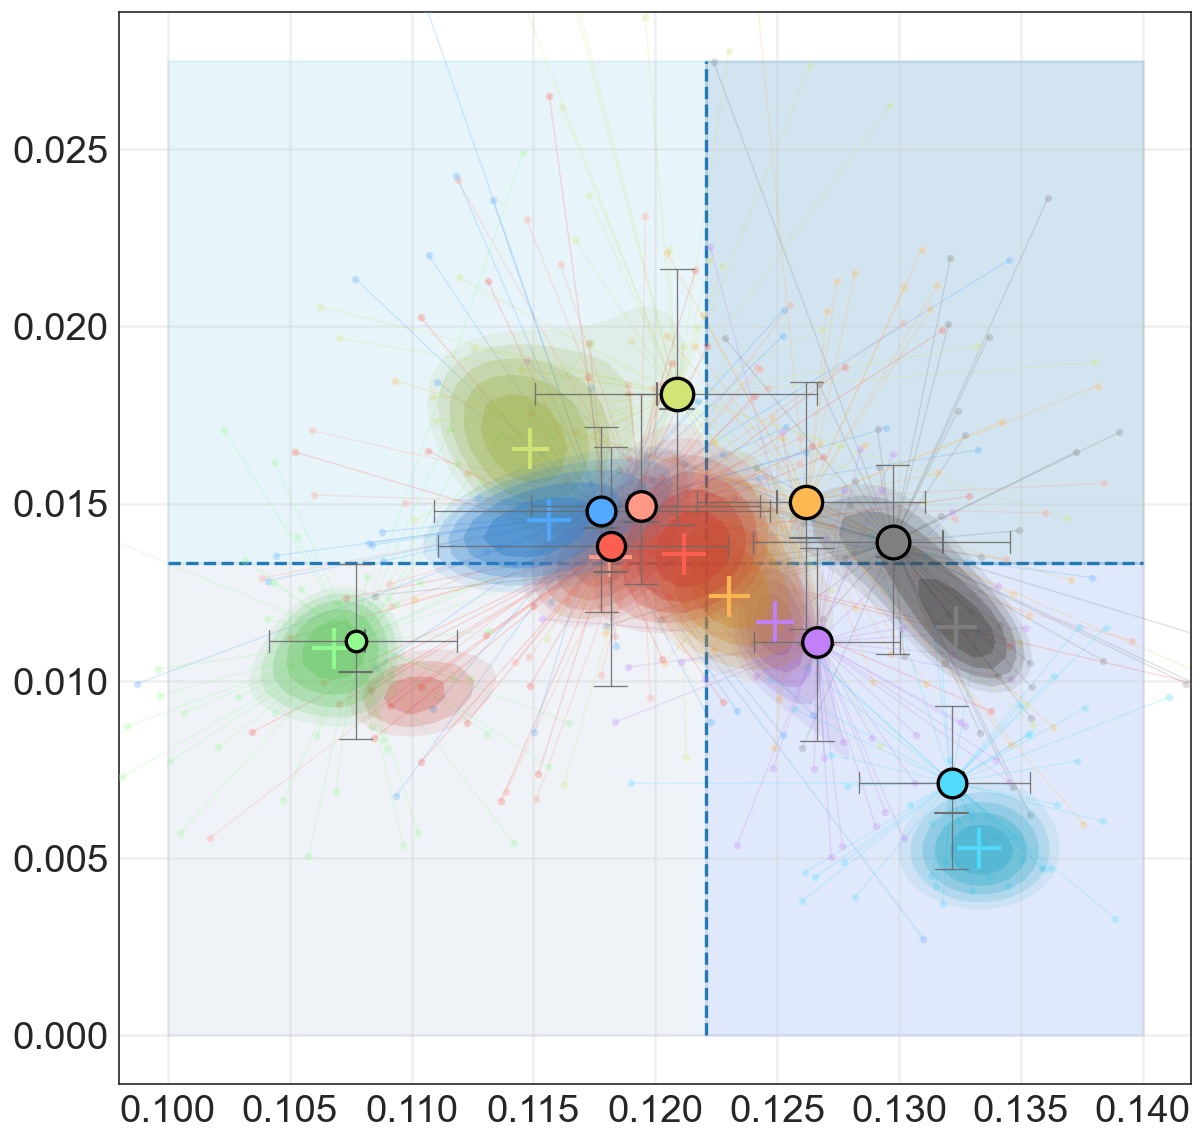

In [42]:
# ===== VISUALIZATION SPVI: Mean spatial dispersion vs spatial dispersion std (across policies) =====

print('Figure Title: Spatial Variation Index')
print('X axis: mean spatial dispersion (across policies)')
print('Y axis: spatial dispersion std (across policies)')
print('Each main point represents a feature')

# Set font properties for all text elements at the beginning
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 23  # Default font size
plt.rcParams['axes.labelsize'] = 30  # Axis label font size
plt.rcParams['xtick.labelsize'] = 23  # X-axis tick label font size
plt.rcParams['ytick.labelsize'] = 23  # Y-axis tick label font size
plt.rcParams['axes.titlesize'] = 32  # Title font size
annotation_fontsize = 12  # Annotation font size

# ===== AXIS RANGE & PADDING =====
# Set to (min, max) to pin the axis range; None = auto-detect from plotted data.
# Padding is white space outside the data viewport (no background colour there).
AXIS_XLIM = (0.100, 0.140)   # e.g. (0.0, 1.0)
AXIS_YLIM = (0.0, 0.0275)   # e.g. (0.0, 1.0)
AXIS_PAD  = 0.05   # fractional padding beyond the viewport on each side
IQR_CAP_SCALE = 2.0         # length of Q1/Q3 end-cap ticks (multiplier of axis-range × 0.012)
IQR_LINE_WIDTH = 0.8        # line width for IQR bar and caps (median tick is 1.6× this)
CONTOUR_SHOW_KDE_CROSS = True   # draw a small + at the KDE density peak
CONTOUR_SHOW_LINK      = False  # draw a dashed line from main marker to KDE peak
MARKER_SIZE_BASE  = 0    # 所有点的底座尺寸（pts²），整体抬高
MARKER_SIZE_SCALE = 600   # 每单位指数值额外增加的尺寸
CONTOUR_CROSS_LW       = 2.5    # line width of the KDE-peak cross
CONTOUR_LINK_LW        = 1.5    # line width of the mean→mode connector

# ===== GRADIENT CONTOUR PARAMETERS (KDE halo around mean markers) =====
CONTOUR_MAX_SIGMA   = 0.5   # grid extent in std-devs of per-run spread
CONTOUR_N_LEVELS    = 5    # density contour layers (more → smoother gradient)
CONTOUR_ALPHA_INNER = 0.40  # alpha at innermost (highest-density) layer
CONTOUR_ALPHA_OUTER = 0.10  # alpha at outermost (lowest-density) layer
CONTOUR_DARKEN      = 0.2   # darken fill color (0 = original, 1 = max darkening)
CONTOUR_GRID_RES = 80  # 越大越平滑，但越慢

# Per-feature highlight (keys = feature_names). Large markers solid; small per-run markers more transparent.
FEATURE_HIGHLIGHT_SMALL_ALPHA = 0.28
FEATURE_HIGHLIGHT_LINE_ALPHA = 0.22

# Dispersion helper: marginal Q1/Q3 ticks + IQR cross at (cx, cy). KDE gradient removed.
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize


def _dispersion_whiskers_and_rings(
    ax,
    cx,
    cy,
    x_runs,
    y_runs,
    ring_color,
    whisker_color="0.42",
    tick_scale_x=None,
    tick_scale_y=None,
    z_rings=5.3,
    z_lines=5.5,
    **kwargs,
):
    """2-D cross box-whisker plot centred at (cx, cy).

    Each axis arm is drawn as a standard 1-D boxplot:
      - thin whisker line from min to max
      - cap ticks at min and max (perpendicular to the arm)
      - filled white box (rectangle) spanning Q1 to Q3
      - median line inside the box
    """
    _ = ring_color, z_rings, kwargs
    x_runs = np.asarray(x_runs, dtype=float).ravel()
    y_runs = np.asarray(y_runs, dtype=float).ravel()
    if x_runs.size <= 1:
        return
    q1x, medx, q3x = np.percentile(x_runs, [25, 50, 75])
    q1y, medy, q3y = np.percentile(y_runs, [25, 50, 75])
    if tick_scale_x is None:
        tick_scale_x = max(np.ptp(ax.get_xlim()), 1e-12) * 0.012
    if tick_scale_y is None:
        tick_scale_y = max(np.ptp(ax.get_ylim()), 1e-12) * 0.012
    # Cap half-sizes (perpendicular to each arm)
    cap_y = max(float(tick_scale_y) * IQR_CAP_SCALE, 1e-12)
    cap_x = max(float(tick_scale_x) * IQR_CAP_SCALE, 1e-12)

    kw = dict(color=whisker_color, clip_on=True)

    # ── X arm: Q1──median──Q3 with end caps ──────────────────────────────────
    _lw = IQR_LINE_WIDTH
    ax.plot([q1x, q3x], [cy, cy], linewidth=_lw, alpha=0.88, zorder=z_lines, **kw)
    ax.plot([q1x, q1x], [cy - cap_y, cy + cap_y], linewidth=_lw, alpha=0.88, zorder=z_lines, **kw)
    ax.plot([q3x, q3x], [cy - cap_y, cy + cap_y], linewidth=_lw, alpha=0.88, zorder=z_lines, **kw)
    ax.plot([medx, medx], [cy - cap_y, cy + cap_y],
            linewidth=_lw * 1.6, alpha=0.95, zorder=z_lines + 0.05, **kw)

    # ── Y arm: Q1──median──Q3 with end caps ──────────────────────────────────
    ax.plot([cx, cx], [q1y, q3y], linewidth=_lw, alpha=0.88, zorder=z_lines, **kw)
    ax.plot([cx - cap_x, cx + cap_x], [q1y, q1y], linewidth=_lw, alpha=0.88, zorder=z_lines, **kw)
    ax.plot([cx - cap_x, cx + cap_x], [q3y, q3y], linewidth=_lw, alpha=0.88, zorder=z_lines, **kw)
    ax.plot([cx - cap_x, cx + cap_x], [medy, medy],
            linewidth=_lw * 1.6, alpha=0.95, zorder=z_lines + 0.05, **kw)


def _gradient_contour(ax, cx, cy, x_runs, y_runs, color,
                      max_sigma=None, n_levels=None,
                      alpha_inner=None, alpha_outer=None,
                      darken=None, zorder=4.5,
                      show_kde_cross=None, show_link=None):
    """KDE-based gradient contour halo following the true per-run density shape.

    The evaluation grid extends well beyond max_sigma so its edges have near-zero
    density and never produce a rectangular clip.  The outermost visible contour
    threshold is set by sampling the KDE on the max_sigma ring around (cx, cy),
    so CONTOUR_MAX_SIGMA controls the spatial reach while the shape follows the data.
    """
    from scipy.stats import gaussian_kde
    import colorsys
    import matplotlib.colors as mcolors
    _ms = CONTOUR_MAX_SIGMA   if max_sigma   is None else max_sigma
    _nl = CONTOUR_N_LEVELS    if n_levels    is None else n_levels
    _ai = CONTOUR_ALPHA_INNER if alpha_inner is None else alpha_inner
    _ao = CONTOUR_ALPHA_OUTER if alpha_outer is None else alpha_outer
    _dk = CONTOUR_DARKEN      if darken      is None else darken
    _gr = CONTOUR_GRID_RES
    x_runs = np.asarray(x_runs, dtype=float).ravel()
    y_runs = np.asarray(y_runs, dtype=float).ravel()
    if x_runs.size < 3:
        return
    rgb_orig = mcolors.to_rgb(color)  # original colour (for cross marker)
    rgb = rgb_orig
    if _dk > 0:
        h, s, v = colorsys.rgb_to_hsv(*rgb)
        rgb = colorsys.hsv_to_rgb(h, min(1.0, s + _dk * 0.4), max(0.0, v - _dk))
    try:
        kde = gaussian_kde(np.vstack([x_runs, y_runs]))
    except Exception:
        return
    sx = float(np.std(x_runs))
    sy = float(np.std(y_runs))
    if sx < 1e-12 or sy < 1e-12:
        return
    # Grid centered on the per-run cloud; extended far beyond max_sigma so
    # density at grid edges ≈ 0 and no rectangular boundary is ever visible.
    xc = float(np.mean(x_runs))
    yc = float(np.mean(y_runs))
    ext = max(_ms + 3.0, 4.0)
    pad_x, pad_y = ext * sx, ext * sy
    xx, yy = np.meshgrid(
        np.linspace(xc - pad_x, xc + pad_x, _gr),
        np.linspace(yc - pad_y, yc + pad_y, _gr),
    )
    zz = kde(np.vstack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
    # Outer threshold: mean KDE density sampled on the max_sigma ring around (cx, cy).
    # This ties the visible boundary to max_sigma while letting the shape be free.
    n_ring = 48
    ring_a = np.linspace(0, 2 * np.pi, n_ring, endpoint=False)
    ring_pts = np.vstack([cx + _ms * sx * np.cos(ring_a),
                          cy + _ms * sy * np.sin(ring_a)])
    outer_density = float(np.mean(kde(ring_pts)))
    zz_min, zz_max = float(zz.min()), float(zz.max())
    zz_norm = (zz - zz_min) / (zz_max - zz_min + 1e-12)
    outer_norm = float(np.clip(
        (outer_density - zz_min) / (zz_max - zz_min + 1e-12), 0.01, 0.95
    ))
    thresholds = np.linspace(outer_norm, 1.0, _nl + 2)[1:-1]
    for i, thresh in enumerate(thresholds):
        t = i / max(_nl - 1, 1)
        alpha = _ao + (_ai - _ao) * t
        try:
            ax.contourf(
                xx, yy, zz_norm,
                levels=[float(thresh), 1.0 + 1e-6],
                colors=[(*rgb, alpha)],
                zorder=zorder,
                antialiased=True,
            )
        except Exception:
            pass
    _show_cross = CONTOUR_SHOW_KDE_CROSS if show_kde_cross is None else show_kde_cross
    _show_link  = CONTOUR_SHOW_LINK      if show_link       is None else show_link
    # KDE peak (mode): location of maximum density in the evaluated grid
    peak_idx = np.unravel_index(np.argmax(zz), zz.shape)
    xp = float(xx[peak_idx])
    yp = float(yy[peak_idx])
    # Small + cross at KDE density peak (mode), not the mean
    if _show_cross:
        # Equal visual arm length: same fraction of each axis data range
        _xl = ax.get_xlim(); _yl = ax.get_ylim()
        cs_x = (_xl[1] - _xl[0]) * 0.012
        cs_y = (_yl[1] - _yl[0]) * 0.012
        kw_cross = dict(color=rgb_orig, linewidth=CONTOUR_CROSS_LW, alpha=0.96,
                        zorder=5.0, clip_on=True, solid_capstyle="butt")
        ax.plot([xp - cs_x, xp + cs_x], [yp, yp], **kw_cross)
        ax.plot([xp, xp], [yp - cs_y, yp + cs_y], **kw_cross)
    # Optional dashed connector from main marker (mean) to KDE peak (mode)
    if _show_link and (abs(cx - xp) > 1e-10 or abs(cy - yp) > 1e-10):
        import colorsys as _cs3
        import matplotlib.colors as _mc3
        _rgb3 = _mc3.to_rgb(rgb) if not isinstance(rgb, tuple) or len(rgb) == 4 else rgb[:3]
        _h3, _s3, _v3 = _cs3.rgb_to_hsv(*_rgb3)
        link_color = _cs3.hsv_to_rgb(_h3, min(1.0, _s3 + 0.2), max(0.0, _v3 - 0.25))
        ax.plot([cx, xp], [cy, yp], color=link_color, linewidth=CONTOUR_LINK_LW,
                linestyle=(0, (5, 2)), alpha=0.82, zorder=4.8, clip_on=True)


# Cross-run means per feature (same raw pieces as SPVI)
spatial_dispersions = global_spatial_dispersions
dispersion_std_values = global_dispersion_std

spvi = np.asarray(spatial_variation_indices, dtype=float)

marker_sizes = MARKER_SIZE_BASE + spvi * MARKER_SIZE_SCALE  # base + SPVI-scaled size

fig, ax = plt.subplots(1, 1, figsize=(12, 10))

ax.grid(True, alpha=0.3)

# Per-run raw axes (mean dispersion vs std across policies) + connectors to cross-run mean
if "rm_per_run" in globals():
    _sd_m = np.asarray(spatial_dispersions, dtype=float)
    _rs_m = np.asarray(dispersion_std_values, dtype=float)
    _nr, _nf = rm_per_run.shape
    for _fi in range(_nf):
        _fname = feature_names[_fi]
        _hc = FEATURE_HIGHLIGHT_COLORS.get(_fname)
        if _hc:
            _lc, _la = _hc, FEATURE_HIGHLIGHT_LINE_ALPHA
            _sc, _sa = _hc, FEATURE_HIGHLIGHT_SMALL_ALPHA
        else:
            _lc, _la = "#6b9ec9", 0.38
            _sc, _sa = "#4a8cbd", 0.55
        _xr = rm_per_run[:, _fi]
        _yr = rs_per_run[:, _fi]
        if _nr > 1:
            for _rr in range(_nr):
                ax.plot(
                    [_xr[_rr], _sd_m[_fi]],
                    [_yr[_rr], _rs_m[_fi]],
                    color=_lc,
                    alpha=_la,
                    linewidth=0.85,
                    zorder=2,
                )
        ax.scatter(
            _xr,
            _yr,
            s=22,
            c=_sc,
            alpha=_sa,
            zorder=4,
            edgecolors="white",
            linewidths=0.35,
        )

_spvi_min, _spvi_max = float(np.min(spvi)), float(np.max(spvi))
if _spvi_min >= _spvi_max:
    _spvi_min, _spvi_max = 0.0, 1.0

_sd_arr = np.asarray(spatial_dispersions, dtype=float)
_dsv_arr = np.asarray(dispersion_std_values, dtype=float)
_hi_mask = np.array([f in FEATURE_HIGHLIGHT_COLORS for f in feature_names], dtype=bool)

# Gradient contour halos around mean markers (based on per-run spread)
if "rm_per_run" in globals() and rm_per_run.shape[0] > 1:
    _norm_spvi_gc = Normalize(_spvi_min, _spvi_max)
    for _i in range(len(feature_names)):
        _fname = feature_names[_i]
        _hc = FEATURE_HIGHLIGHT_COLORS.get(_fname)
        _gc = _hc if _hc else plt.cm.Blues(float(_norm_spvi_gc(spvi[_i])))
        _gradient_contour(
            ax,
            float(_sd_arr[_i]),
            float(_dsv_arr[_i]),
            rm_per_run[:, _i],
            rs_per_run[:, _i],
            _gc,
        )

if "rm_per_run" in globals() and rm_per_run.shape[0] > 1:
    _tsx = max(float(np.ptp(_sd_arr)), 1e-9) * 0.014
    _tsy = max(float(np.ptp(_dsv_arr)), 1e-9) * 0.014
    _norm_spvi_vis = Normalize(_spvi_min, _spvi_max)
    for _i in range(len(feature_names)):
        _pc = (
            FEATURE_HIGHLIGHT_COLORS[feature_names[_i]]
            if feature_names[_i] in FEATURE_HIGHLIGHT_COLORS
            else plt.cm.Blues(float(_norm_spvi_vis(spvi[_i])))
        )
        _dispersion_whiskers_and_rings(
            ax,
            float(_sd_arr[_i]),
            float(_dsv_arr[_i]),
            rm_per_run[:, _i],
            rs_per_run[:, _i],
            _pc,
            tick_scale_x=_tsx,
            tick_scale_y=_tsy,
        )

scatter = None
if (~_hi_mask).any():
    scatter = ax.scatter(
        _sd_arr[~_hi_mask],
        _dsv_arr[~_hi_mask],
        s=marker_sizes[~_hi_mask],
        c=spvi[~_hi_mask],
        cmap="Blues",
        vmin=_spvi_min,
        vmax=_spvi_max,
        edgecolor="black",
        linewidth=2,
        zorder=7,
    )
for _i in np.flatnonzero(_hi_mask):
    ax.scatter(
        [_sd_arr[_i]],
        [_dsv_arr[_i]],
        s=marker_sizes[_i],
        c=[FEATURE_HIGHLIGHT_COLORS[feature_names[_i]]],
        edgecolor="black",
        linewidth=2,
        zorder=8,
    )

# if scatter is not None:
#     cbar = plt.colorbar(scatter, ax=ax, shrink=0.6, location="right", pad=0.03)
# else:
#     _sm = ScalarMappable(norm=Normalize(_spvi_min, _spvi_max), cmap="Blues")
#     _sm.set_array([])
#     cbar = plt.colorbar(_sm, ax=ax, shrink=0.6, location="right", pad=0.03)
# cbar.ax.tick_params(labelsize=23)

ax.set_box_aspect(1)

# ── Viewport + white padding ──────────────────────────────────────────────────
_mean_disp_std  = np.mean(dispersion_std_values) if len(dispersion_std_values) > 0 else None
_mean_dispersion = np.mean(spatial_dispersions)  if len(spatial_dispersions)  > 0 else None
_auto_xl = ax.get_xlim()
_auto_yl = ax.get_ylim()
_vx0, _vx1 = AXIS_XLIM if AXIS_XLIM is not None else _auto_xl
_vy0, _vy1 = AXIS_YLIM if AXIS_YLIM is not None else _auto_yl
_px = (_vx1 - _vx0) * AXIS_PAD
_py = (_vy1 - _vy0) * AXIS_PAD
ax.set_xlim(_vx0 - _px, _vx1 + _px)
ax.set_ylim(_vy0 - _py, _vy1 + _py)
mean_disp_std   = _mean_disp_std
mean_dispersion = _mean_dispersion

quadrant_colors = ['lightsteelblue', 'cornflowerblue', 'skyblue', '#2279B5']

# Quadrant dividing lines (clipped to viewport, not full axes)
if mean_disp_std is not None:
    ax.plot([_vx0, _vx1], [mean_disp_std, mean_disp_std],
            color='#2279B5', linestyle='--', linewidth=2, zorder=3)
if mean_dispersion is not None:
    ax.plot([mean_dispersion, mean_dispersion], [_vy0, _vy1],
            color='#2279B5', linestyle='--', linewidth=2, zorder=3)

# Colored quadrant backgrounds – only within viewport; padding stays white
alpha_bg = 0.2
if mean_disp_std is not None and mean_dispersion is not None:
    ax.fill_between([_vx0, mean_dispersion], _vy0, mean_disp_std,
                    color=quadrant_colors[0], alpha=alpha_bg, zorder=0)
    ax.fill_between([mean_dispersion, _vx1], _vy0, mean_disp_std,
                    color=quadrant_colors[1], alpha=alpha_bg, zorder=0)
    ax.fill_between([_vx0, mean_dispersion], mean_disp_std, _vy1,
                    color=quadrant_colors[2], alpha=alpha_bg, zorder=0)
    ax.fill_between([mean_dispersion, _vx1], mean_disp_std, _vy1,
                    color=quadrant_colors[3], alpha=alpha_bg, zorder=0)

# ax.text(0.95, 0.95, 'High Dispersion Std\nHigh Mean Dispersion', transform=ax.transAxes,
#         ha='right', va='top', fontsize=annotation_fontsize, fontweight='bold',
#         bbox=dict(boxstyle='round,pad=0.3', facecolor=quadrant_colors[3], alpha=0.7))
# ax.text(0.05, 0.95, 'High Dispersion Std\nLow Mean Dispersion', transform=ax.transAxes,
#         ha='left', va='top', fontsize=annotation_fontsize, fontweight='bold',
#         bbox=dict(boxstyle='round,pad=0.3', facecolor=quadrant_colors[2], alpha=0.7))
# ax.text(0.95, 0.05, 'Low Dispersion Std\nHigh Mean Dispersion', transform=ax.transAxes,
#         ha='right', va='bottom', fontsize=annotation_fontsize, fontweight='bold',
#         bbox=dict(boxstyle='round,pad=0.3', facecolor=quadrant_colors[1], alpha=0.7))
# ax.text(0.05, 0.05, 'Low Dispersion Std\nLow Mean Dispersion', transform=ax.transAxes,
#         ha='left', va='bottom', fontsize=annotation_fontsize, fontweight='bold',
#         bbox=dict(boxstyle='round,pad=0.3', facecolor=quadrant_colors[0], alpha=0.7))

plt.tight_layout()
plt.show()


<a id="sec-4-analytics"></a>

## 4. UCP result analytics

Integrate multi-run UCP, select normalisation, compute ΔUCP.


<a id="sec-4-1-integrate"></a>

### 4.1 Multi-run integrated UCP

Mean P(recommend) across features and runs per policy.


=== Calculating multi-run UCP for each policy ===
Standalone: loading ucp_gdf from data/data_uci_puci.gpkg
Standalone: loading multi-run P(recommend) from 50 folder(s) under data/


Load runs:   0%|          | 0/50 [00:00<?, ?run/s]

P(recommend) per pair:   0%|          | 0/45 [00:00<?, ?pair/s]

Computing UCP per policy:   0%|          | 0/5 [00:00<?, ?it/s]

  UCP_1:   0%|          | 0/9 [00:00<?, ?it/s]

  UCP_1: 9 features — mean UCP=0.1767, max=1.0000, points>0=1381


... (4 outputs left out)

  UCP_4:   0%|          | 0/9 [00:00<?, ?it/s]

  UCP_4: 9 features — mean UCP=0.1775, max=0.9978, points>0=1448


  UCP_5:   0%|          | 0/9 [00:00<?, ?it/s]

  UCP_5: 9 features — mean UCP=0.1778, max=0.9933, points>0=1497
Figure Title: Urban Comfort Potential (UCP) — multi-run mean P(recommend) per policy
Saved figure → figure/code_8_ucp_per_policy_multirun.png


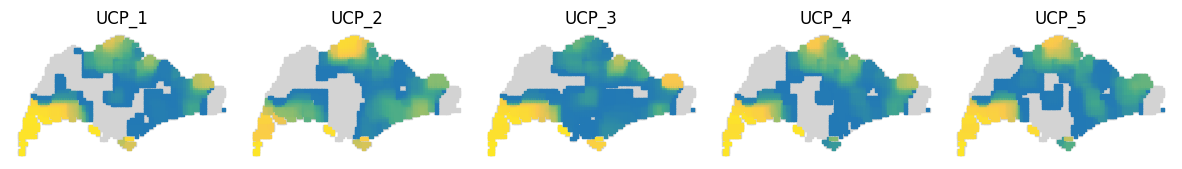

In [3]:
# Calculate multi-run UCP for each policy
# UCP = mean P(recommend) across all features, averaged over all optimisation runs
# Self-contained: run alone — loads ucp_gdf + P(recommend) when missing (same as Section 3 overlap cell).
# Priority: overlap_maps_data → all_policy_feature_data → read multi-run folders → single-run fallback.

import sys
import os
from pathlib import Path
from collections import defaultdict
from itertools import product

import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
from tqdm.auto import tqdm
from matplotlib.colors import LinearSegmentedColormap

print("=== Calculating multi-run UCP for each policy ===")

# ── Standalone bootstrap (no-op when upstream cells already ran) ───────────────
_REPO_ROOT = Path.cwd().resolve()
if str(_REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(_REPO_ROOT))

import importlib.util

_uvm_path = _REPO_ROOT / "scripts" / "uci_variation_metrics.py"
if not _uvm_path.exists():
    raise FileNotFoundError(f"Missing helper script: {_uvm_path}")
_spec = importlib.util.spec_from_file_location("uci_variation_metrics_repo", _uvm_path)
_uvm = importlib.util.module_from_spec(_spec)
assert _spec.loader is not None
_spec.loader.exec_module(_uvm)
discover_optimisation_run_dirs = _uvm.discover_optimisation_run_dirs
load_canonical_optimisation_gdfs = _uvm.load_canonical_optimisation_gdfs
CANONICAL_POLICY_NAMES = _uvm.CANONICAL_POLICY_NAMES
CANONICAL_FEATURE_NAMES = _uvm.CANONICAL_FEATURE_NAMES

if "ucp_gdf" not in globals():
    print("Standalone: loading ucp_gdf from data/data_uci_puci.gpkg")
    ucp_gdf = gpd.read_file("data/data_uci_puci.gpkg")

if "policy_names" not in globals():
    policy_names = list(CANONICAL_POLICY_NAMES)
if "feature_names" not in globals():
    feature_names = list(CANONICAL_FEATURE_NAMES)


def _notebook_var(name, default=None):
    try:
        ip = get_ipython()
        if ip is not None:
            return ip.user_ns.get(name, default)
    except NameError:
        pass
    return globals().get(name, default)


def aggregate_recommendations_multirun(policy_names, feature_names, run_dirs):
    """Same logic as Section 3 overlap cell."""
    run_gdfs_list = []
    for _rid, run_path in tqdm(run_dirs, desc="Load runs", unit="run", mininterval=0.5):
        gdfs, _, _ = load_canonical_optimisation_gdfs(run_path)
        run_gdfs_list.append(gdfs)
    n_runs = len(run_gdfs_list)
    if n_runs == 0:
        return {p: {f: None for f in feature_names} for p in policy_names}

    inv_n = 1.0 / float(n_runs)
    out = {p: {f: None for f in feature_names} for p in policy_names}
    combos = list(product(policy_names, feature_names))
    for policy, feature in tqdm(combos, desc="P(recommend) per pair", unit="pair"):
        votes = defaultdict(int)
        base_gdf = None
        for gdfs in run_gdfs_list:
            if policy not in gdfs or feature not in gdfs[policy]:
                continue
            gdf = gdfs[policy][feature]
            if gdf is None or gdf.empty:
                continue
            if base_gdf is None:
                base_gdf = gdf.copy()
            rec_col = f"{feature}_recommendation"
            if rec_col not in gdf.columns:
                continue
            rec_mask = gdf[rec_col].astype(float).eq(1.0).to_numpy()
            geoms = gdf.geometry.values
            for i in np.flatnonzero(rec_mask):
                geom = geoms[i]
                k = (round(geom.x, 6), round(geom.y, 6))
                votes[k] += 1
        if base_gdf is None:
            continue
        merged = base_gdf.copy()
        rec_col = f"{feature}_recommendation"
        merged[rec_col] = [
            votes[(round(geom.x, 6), round(geom.y, 6))] * inv_n for geom in merged.geometry.values
        ]
        out[policy][feature] = merged
    return out


if (_src_data := _notebook_var("overlap_maps_data")) is not None:
    _run_dirs = _notebook_var("run_dirs") or []
    _n_runs_used = len(_run_dirs) if _run_dirs else "?"
    _mr_tag = _notebook_var("_mr_tag", "")
    print(f"Using overlap_maps_data ({_n_runs_used} run(s) aggregated)")
elif (_src_data := _notebook_var("all_policy_feature_data")) is not None:
    _mr_tag = _notebook_var("_mr_tag", "")
    _n_runs_used = 1
    print("Using all_policy_feature_data (single run)")
else:
    DATA_ROOT = "data"
    run_dirs = discover_optimisation_run_dirs(DATA_ROOT)
    if len(run_dirs) >= 1:
        print(
            f"Standalone: loading multi-run P(recommend) from "
            f"{len(run_dirs)} folder(s) under {DATA_ROOT}/"
        )
        _src_data = aggregate_recommendations_multirun(policy_names, feature_names, run_dirs)
        overlap_maps_data = _src_data
        _mr_tag = "_multirun" if len(run_dirs) > 1 else ""
        _n_runs_used = len(run_dirs)
    else:
        opt_dir = os.path.join(DATA_ROOT, "optimisation_result")
        print(f"Standalone: loading single run from {opt_dir}")
        _src_data, _, _ = load_canonical_optimisation_gdfs(opt_dir)
        overlap_maps_data = _src_data
        _mr_tag = ""
        _n_runs_used = 1

# Initialise UCP columns
for policy in policy_names:
    ucp_gdf[policy] = 0.0

# For each policy compute UCP = mean P(recommend) across all features
for policy in tqdm(policy_names, desc="Computing UCP per policy"):
    if policy not in _src_data:
        print(f"  Warning: {policy} not in source data")
        continue

    p_sum = np.zeros(len(ucp_gdf), dtype=float)
    n_valid = 0

    for feature in tqdm(feature_names, desc=f"  {policy}", leave=False):
        gdf = _src_data[policy].get(feature)
        if gdf is None or gdf.empty:
            continue
        rec_col = f'{feature}_recommendation'
        if rec_col not in gdf.columns:
            continue

        # Align by 'id' column (fast path); fall back to geometry coordinate key
        if 'id' in gdf.columns and 'id' in ucp_gdf.columns:
            id_to_p = dict(zip(gdf['id'], gdf[rec_col].astype(float)))
            p_vec = ucp_gdf['id'].map(id_to_p).fillna(0.0).to_numpy()
        else:
            coord_to_p = {(round(g.x, 6), round(g.y, 6)): float(v)
                          for g, v in zip(gdf.geometry, gdf[rec_col])}
            p_vec = np.array([coord_to_p.get((round(g.x, 6), round(g.y, 6)), 0.0)
                              for g in ucp_gdf.geometry])

        p_sum += p_vec
        n_valid += 1

    if n_valid > 0:
        ucp_gdf[policy] = p_sum / n_valid
        ucp_gdf[f"{policy}_raw"] = ucp_gdf[policy].to_numpy(dtype=float)
        print(f"  {policy}: {n_valid} features — "
              f"mean UCP={ucp_gdf[policy].mean():.4f}, max={ucp_gdf[policy].max():.4f}, "
              f"points>0={(ucp_gdf[policy] > 0).sum()}")

# Visualise UCP per policy — same style as Section 3 intensity maps
_ucp_cmap = LinearSegmentedColormap.from_list(
    "ucp_custom",
    ["#2279B5", "#43AA8B", "#90BE6D", "#F9C74F", "#FDE725"],
)
_ms = 5
_mr_tag_ucp = _mr_tag
_ucp_norm = plt.Normalize(vmin=0.0, vmax=1.0)

print("Figure Title: Urban Comfort Potential (UCP) — multi-run mean P(recommend) per policy")
fig, axes = plt.subplots(1, len(policy_names), figsize=(3 * len(policy_names), 3))
if not hasattr(axes, '__len__'):
    axes = [axes]

for i, policy in enumerate(policy_names):
    ax = axes[i]
    ax.scatter(ucp_gdf.geometry.x, ucp_gdf.geometry.y,
               color="lightgrey", s=_ms, marker="s")
    if policy in ucp_gdf.columns:
        selected = ucp_gdf[ucp_gdf[policy] > 0]
        if not selected.empty:
            ax.scatter(
                selected.geometry.x, selected.geometry.y,
                c=selected[policy].to_numpy(dtype=float), cmap=_ucp_cmap, norm=_ucp_norm,
                s=_ms, marker="s",
            )
    ax.set_title(policy, fontsize=12)
    ax.set_xticks([])
    ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_aspect("equal")

plt.subplots_adjust(hspace=0.1, wspace=0.05)
os.makedirs("figure", exist_ok=True)
_ucp_fig_path = os.path.join("figure", f"code_8_ucp_per_policy{_mr_tag_ucp}.png")
fig.savefig(_ucp_fig_path, dpi=300, bbox_inches="tight")
print(f"Saved figure → {_ucp_fig_path}")
plt.show()

<a id="sec-4-2-norm-exp"></a>

### 4.2 Normalisation experiment

Compare candidate UCP transforms (global MM, robust MM, etc.).


Transform comparison uses UCP_X_raw (safe to re-run after normalisation).
Global raw UCP (non-zero): min=0.00222, P5=0.00222, P95=0.90667, P85(cap)=0.64889, max=1.00000
Saved figure → figure/code_8_ucp_normalisation_raw_vs_cbrt.png


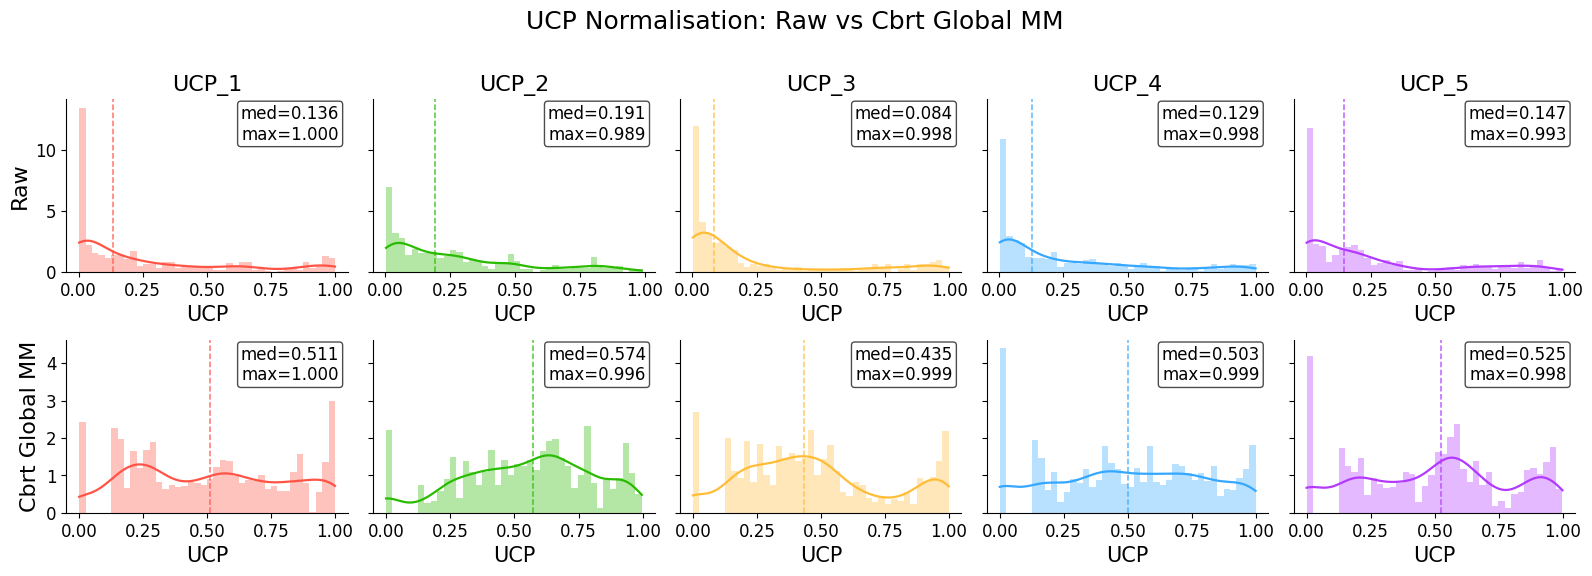

In [4]:
# UCP distribution — compare Raw vs Cbrt Global MM (selected for maps)
# Full 11-method catalogue kept in `transforms` for the quality-metrics cell.

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde, yeojohnson

UCP_NORM_METHOD = "cbrt_global_mm"     # selected method for maps (norm cell)
UCP_ROBUST_PCT = (5, 95)
UCP_SOFT_CAP_PCT = 85

policy_colors = ["#FF5445", "#29BB00", "#FFBC37", "#35A7FF", "#B339FF"]


def _ucp_raw_values(policy):
    """Always compare transforms on raw mean P(recommend), not normalised UCP_X."""
    raw_col = f"{policy}_raw"
    if raw_col in ucp_gdf.columns:
        return ucp_gdf[raw_col].to_numpy(dtype=float)
    return ucp_gdf[policy].to_numpy(dtype=float)


_all_nonzero = np.concatenate([
    _ucp_raw_values(p)[_ucp_raw_values(p) > 0]
    for p in policy_names if p in ucp_gdf.columns
])
if any(f"{p}_raw" in ucp_gdf.columns for p in policy_names):
    print("Transform comparison uses UCP_X_raw (safe to re-run after normalisation).")
_g_lo = float(_all_nonzero.min()) if len(_all_nonzero) else 0.0
_g_hi = float(_all_nonzero.max()) if len(_all_nonzero) else 1.0
_p_lo = float(np.percentile(_all_nonzero, UCP_ROBUST_PCT[0])) if len(_all_nonzero) else 0.0
_p_hi = float(np.percentile(_all_nonzero, UCP_ROBUST_PCT[1])) if len(_all_nonzero) else 1.0
_g_cap = float(np.percentile(_all_nonzero, UCP_SOFT_CAP_PCT)) if len(_all_nonzero) else 1.0
_asinh_s = max(float(np.median(_all_nonzero - _g_lo)) if len(_all_nonzero) else 1.0, 1e-6)
_sorted_pool = np.sort(_all_nonzero)
_mu = float(_all_nonzero.mean()) if len(_all_nonzero) else 0.0
_sd = max(float(_all_nonzero.std()) if len(_all_nonzero) else 1.0, 1e-12)
_z_lo = (_g_lo - _mu) / _sd
_z_hi = (_g_hi - _mu) / _sd
if len(_all_nonzero):
    _yj_t, _yj_lmbda = yeojohnson(_all_nonzero)
    _yj_lo, _yj_hi = float(_yj_t.min()), float(_yj_t.max())
else:
    _yj_lmbda, _yj_lo, _yj_hi = 1.0, 0.0, 1.0

print(f"Global raw UCP (non-zero): min={_g_lo:.5f}, P{UCP_ROBUST_PCT[0]}={_p_lo:.5f}, "
      f"P{UCP_ROBUST_PCT[1]}={_p_hi:.5f}, P{UCP_SOFT_CAP_PCT}(cap)={_g_cap:.5f}, max={_g_hi:.5f}")


def _global_mm(v):
    v = np.asarray(v, dtype=float)
    denom = _g_hi - _g_lo
    if denom <= 0:
        return np.zeros_like(v)
    return np.clip((v - _g_lo) / denom, 0.0, 1.0)


def _robust_mm(v):
    v = np.asarray(v, dtype=float)
    denom = _p_hi - _p_lo
    if denom <= 0:
        return np.zeros_like(v)
    return np.clip((v - _p_lo) / denom, 0.0, 1.0)


def _sqrt_mm(v):
    return np.sqrt(_global_mm(v))


def _cbrt_mm(v):
    return np.cbrt(_global_mm(v))


def _log1p_mm(v):
    return np.log1p(_global_mm(v) * (np.e - 1))


def _asinh_ucp(v):
    v = np.asarray(v, dtype=float)
    x = np.maximum(v - _g_lo, 0.0)
    t = np.arcsinh(x / _asinh_s)
    t_hi = np.arcsinh(max(_g_hi - _g_lo, 0.0) / _asinh_s)
    return np.clip(t / t_hi if t_hi > 0 else t, 0.0, 1.0)


def _soft_cap(v):
    v = np.asarray(v, dtype=float)
    if _g_cap <= _g_lo:
        return np.ones_like(v)
    k = _g_cap - _g_lo
    x = np.maximum(v - _g_lo, 0.0)
    linear = x / k
    sat = 1.0 - np.exp(-linear)
    blend = np.clip((v - _p_lo) / max(_g_cap - _p_lo, 1e-12), 0.0, 1.0)
    return np.clip((1.0 - blend) * linear + blend * sat, 0.0, 1.0)


def _pct_rank(v):
    v = np.asarray(v, dtype=float)
    idxs = np.searchsorted(_sorted_pool, v, side="left")
    return idxs / max(len(_sorted_pool) - 1, 1)


def _yeojohnson_ucp(v):
    v = np.asarray(v, dtype=float)
    t = yeojohnson(v, lmbda=_yj_lmbda)  # fixed λ → returns array only
    denom = _yj_hi - _yj_lo
    if denom <= 0:
        return np.zeros_like(v)
    return np.clip((t - _yj_lo) / denom, 0.0, 1.0)


def _zscore_01(v):
    v = np.asarray(v, dtype=float)
    z = (v - _mu) / _sd
    denom = _z_hi - _z_lo
    if denom <= 0:
        return np.zeros_like(v)
    return np.clip((z - _z_lo) / denom, 0.0, 1.0)


transforms = {
    "Raw":                    lambda v: np.asarray(v, dtype=float),
    "Global MM":              _global_mm,
    f"Robust MM (P{UCP_ROBUST_PCT[0]}–P{UCP_ROBUST_PCT[1]})": _robust_mm,
    "Sqrt Global MM":         _sqrt_mm,
    "Cbrt Global MM":         _cbrt_mm,
    "Log1p Global MM":        _log1p_mm,
    "Asinh":                  _asinh_ucp,
    f"Soft Cap P{UCP_SOFT_CAP_PCT}": _soft_cap,
    "Global Percentile":      _pct_rank,
    "Yeo-Johnson":            _yeojohnson_ucp,
    "Z-score → [0,1]":        _zscore_01,
}

UCP_NORM_FNS = {
    "raw":                lambda v: np.asarray(v, dtype=float),
    "global_mm":          _global_mm,
    "robust_mm":          _robust_mm,
    "sqrt_global_mm":     _sqrt_mm,
    "cbrt_global_mm":     _cbrt_mm,
    "log1p_global_mm":    _log1p_mm,
    "asinh":              _asinh_ucp,
    "soft_cap":           _soft_cap,
    "global_percentile":  _pct_rank,
    "yeojohnson":         _yeojohnson_ucp,
    "zscore_01":          _zscore_01,
}

# Plot only Raw vs selected Cbrt Global MM
_plot_transforms = {
    "Raw": transforms["Raw"],
    "Cbrt Global MM": transforms["Cbrt Global MM"],
}

fig, axes = plt.subplots(len(_plot_transforms), len(policy_names),
                         figsize=(3.2 * len(policy_names), 2.8 * len(_plot_transforms)),
                         sharey="row")

for row_idx, (label, tfn) in enumerate(_plot_transforms.items()):
    for col_idx, policy in enumerate(policy_names):
        ax = axes[row_idx, col_idx]
        if policy not in ucp_gdf.columns:
            ax.set_visible(False)
            continue

        raw = _ucp_raw_values(policy)
        nonzero_raw = raw[raw > 0]
        if len(nonzero_raw) == 0:
            ax.set_visible(False)
            continue

        vals = tfn(nonzero_raw)
        color = policy_colors[col_idx % len(policy_colors)]

        ax.hist(vals, bins=40, color=color, alpha=0.35, density=True)
        if len(vals) > 10:
            kde = gaussian_kde(vals, bw_method="scott")
            xg = np.linspace(vals.min(), vals.max(), 300)
            ax.plot(xg, kde(xg), color=color, lw=1.6)
        ax.axvline(float(np.median(vals)), color=color, lw=1.1, ls="--", alpha=0.8)

        if col_idx == 0:
            ax.set_ylabel(label, fontsize=16)
        if row_idx == 0:
            ax.set_title(policy, fontsize=16)
        ax.tick_params(labelsize=12)
        ax.set_xlabel("UCP", fontsize=15)
        ax.text(0.97, 0.97,
                f"med={np.median(vals):.3f}\nmax={vals.max():.3f}",
                transform=ax.transAxes, fontsize=12, va="top", ha="right",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7))
        for spine in ["top", "right"]:
            ax.spines[spine].set_visible(False)

plt.suptitle("UCP Normalisation: Raw vs Cbrt Global MM",
             fontsize=18, y=1.02)
plt.tight_layout()
import os
os.makedirs("figure", exist_ok=True)
_fig_path = "figure/code_8_ucp_normalisation_raw_vs_cbrt.png"
fig.savefig(_fig_path, dpi=300, bbox_inches="tight")
print(f"Saved figure → {_fig_path}")
plt.show()

<a id="sec-4-3-norm-metrics"></a>

### 4.3 Normalisation quality metrics

Rank normalisation candidates across policies.


Metric values (avg across 5 policies)
                    |Skewness|↓  |Kurtosis|↓  Gini↓  IQR Cov.↑  Norm. Entropy↑
Method                                                                        
Raw                       1.178        0.169  0.595      0.798           0.813
Global MM                 1.178        0.169  0.601      0.798           0.813
Robust MM (P5–P95)        1.138        0.170  0.597      0.877           0.805
Sqrt Global MM            0.454        0.901  0.418      0.855           0.938
Cbrt Global MM            0.183        0.919  0.326      0.831           0.921
Log1p Global MM           0.857        0.549  0.549      0.860           0.862
Asinh                     0.448        1.128  0.488      0.910           0.902
Soft Cap P85              0.594        1.043  0.524      0.895           0.880
Global Percentile         0.198        1.094  0.343      0.836           0.939
Yeo-Johnson               0.342        1.262  0.472      0.939           0.907
Z-score → [0,1

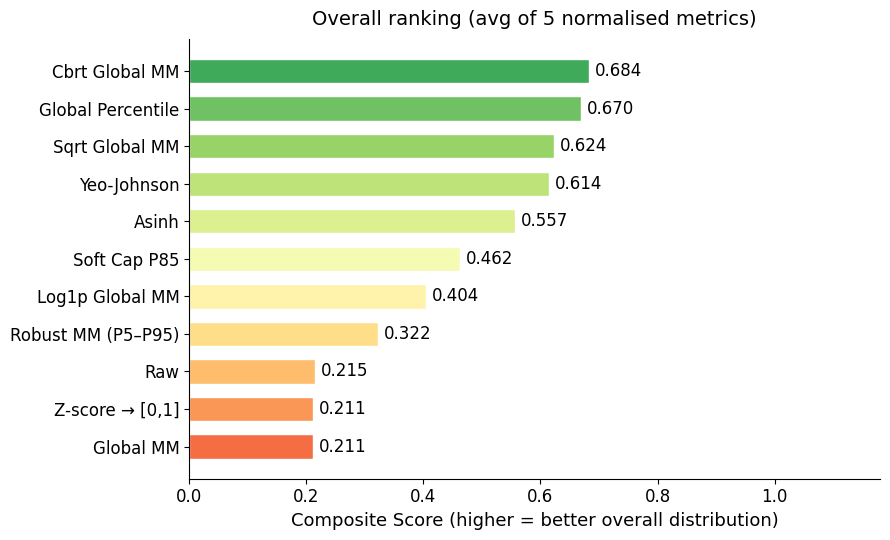


Best method by composite score: Cbrt Global MM


In [5]:

# ── UCP Normalisation Quality Metrics ─────────────────────────────────────────
# Compares all candidates from distribution cell (11 methods × 5 policies).
# Evaluates each transform across 5 policies (averaged) on 5 criteria:
#   Skewness       : |skew| → 0 means symmetric distribution
#   Excess Kurtosis: |kurt| → 0 means normal-like tails
#   Gini           : concentration index → 0 means perfectly equal spread
#   IQR Coverage   : (P90 − P10) / value_range → higher means colour range well used
#   Norm. Entropy  : discretised Shannon entropy, normalised → 1 means uniform

import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import skew, kurtosis

def _gini(v):
    v = np.sort(v)
    n = len(v)
    if n == 0 or v.sum() == 0:
        return np.nan
    idx = np.arange(1, n + 1)
    return (2 * (idx * v).sum()) / (n * v.sum()) - (n + 1) / n

def _norm_entropy(v, bins=50):
    counts, _ = np.histogram(v, bins=bins, range=(v.min(), v.max()))
    p = counts / counts.sum()
    p = p[p > 0]
    h = -np.sum(p * np.log(p))
    return h / np.log(bins)   # normalise to [0,1]

def _iqr_coverage(v):
    lo, hi = np.percentile(v, 10), np.percentile(v, 90)
    vrange = v.max() - v.min()
    return (hi - lo) / vrange if vrange > 0 else 0.0

records = []
for method, tfn in transforms.items():
    sk_vals, ku_vals, gi_vals, iq_vals, en_vals = [], [], [], [], []
    for policy in policy_names:
        if policy not in ucp_gdf.columns:
            continue
        if f"{policy}_raw" in ucp_gdf.columns:
            raw = ucp_gdf[f"{policy}_raw"].to_numpy(dtype=float)
        else:
            raw = ucp_gdf[policy].to_numpy(dtype=float)
        nz = raw[raw > 0]
        if len(nz) < 10:
            continue
        v = tfn(nz)
        sk_vals.append(abs(float(skew(v))))
        ku_vals.append(abs(float(kurtosis(v))))
        gi_vals.append(_gini(v))
        iq_vals.append(_iqr_coverage(v))
        en_vals.append(_norm_entropy(v))

    records.append({
        "Method":         method,
        "|Skewness|↓":    np.mean(sk_vals),
        "|Kurtosis|↓":    np.mean(ku_vals),
        "Gini↓":          np.mean(gi_vals),
        "IQR Cov.↑":      np.mean(iq_vals),
        "Norm. Entropy↑": np.mean(en_vals),
    })

df = pd.DataFrame(records).set_index("Method")

# ── Print metric table ─────────────────────────────────────────────────────────
print("Metric values (avg across 5 policies)")
print(df.round(3).to_string())

# ── Overall ranking bar chart (higher = better) ────────────────────────────────
df_norm = df.copy()
for col in df.columns:
    lo, hi = df[col].min(), df[col].max()
    if hi > lo:
        if "↓" in col:   # lower is better → invert
            df_norm[col] = 1 - (df[col] - lo) / (hi - lo)
        else:
            df_norm[col] = (df[col] - lo) / (hi - lo)
    else:
        df_norm[col] = 0.5

df_norm["Score"] = df_norm.mean(axis=1)
df_norm_sorted = df_norm.sort_values("Score", ascending=True)

fig, ax_b = plt.subplots(figsize=(9, 5.5))
colors_bar = plt.cm.RdYlGn(np.linspace(0.2, 0.85, len(df_norm_sorted)))
bars = ax_b.barh(df_norm_sorted.index, df_norm_sorted["Score"],
                 color=colors_bar, edgecolor="white", height=0.65)
for bar, val in zip(bars, df_norm_sorted["Score"]):
    ax_b.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2,
              f"{val:.3f}", va="center", fontsize=12)
ax_b.set_xlim(0, 1.18)
ax_b.set_xlabel("Composite Score (higher = better overall distribution)", fontsize=13)
ax_b.set_title("Overall ranking (avg of 5 normalised metrics)", fontsize=14, pad=10)
ax_b.tick_params(axis="both", labelsize=12)
for sp in ["top", "right"]:
    ax_b.spines[sp].set_visible(False)

plt.tight_layout()
os.makedirs("figure", exist_ok=True)
fig.savefig("figure/code_8_ucp_normalisation_ranking.png", dpi=300, bbox_inches="tight")
print("Saved figure → figure/code_8_ucp_normalisation_ranking.png")
plt.show()

print("\nBest method by composite score:",
      df_norm.sort_values("Score", ascending=False).index[0])


<a id="sec-4-4-norm-select"></a>

### 4.4 Normalisation selection

Choose display transform for downstream ΔUCP maps.


Applying normalisation: cbrt_global_mm
  UCP_1: mean=0.5378, max=1.0000
  UCP_2: mean=0.5818, max=0.9963
  UCP_3: mean=0.5052, max=0.9993
  UCP_4: mean=0.5601, max=0.9993
  UCP_5: mean=0.5513, max=0.9978
Figure Title: UCP (cbrt_global_mm) per policy
Saved figure → figure/code_8_ucp_normalised_cbrt_global_mm_multirun.png


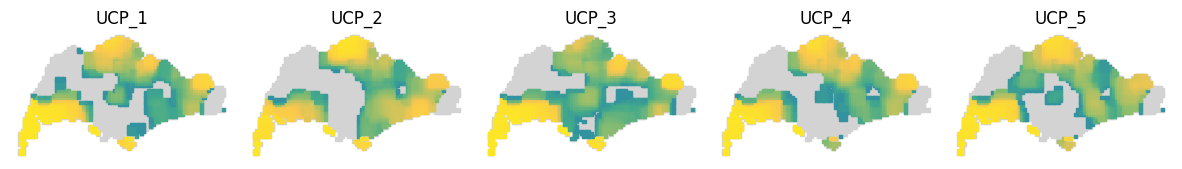

In [6]:
# ── UCP Normalisation Selection ────────────────────────────────────────────────
# Run the distribution cell first (defines UCP_NORM_FNS and UCP_NORM_METHOD).
# Methods (see distribution cell): raw | global_mm | robust_mm | sqrt_global_mm |
#   cbrt_global_mm (selected) | log1p_global_mm | asinh | soft_cap |
#   global_percentile | yeojohnson | zscore_01
# Transform UCP_X from UCP_X_raw (never double-apply if UCP_X already normalised).
# ──────────────────────────────────────────────────────────────────────────────

import numpy as np
import matplotlib.pyplot as plt
import os
from matplotlib.colors import LinearSegmentedColormap

if "UCP_NORM_FNS" not in globals():
    raise RuntimeError("Run the UCP distribution cell first to define UCP_NORM_FNS.")

UCP_NORM_METHOD = "cbrt_global_mm"
assert UCP_NORM_METHOD in UCP_NORM_FNS, f"Unknown method: {UCP_NORM_METHOD}"
_tfn = UCP_NORM_FNS[UCP_NORM_METHOD]

print(f"Applying normalisation: {UCP_NORM_METHOD}")

# Apply normalisation: read raw, write to UCP_X (UCP_X_raw unchanged)
for policy in policy_names:
    if policy not in ucp_gdf.columns:
        continue
    raw_col = f"{policy}_raw"
    if raw_col not in ucp_gdf.columns:
        ucp_gdf[raw_col] = ucp_gdf[policy].to_numpy(dtype=float)
    raw = ucp_gdf[raw_col].to_numpy(dtype=float)
    ucp_gdf[policy] = np.where(raw > 0, _tfn(raw), 0.0)
    nz = ucp_gdf[policy].to_numpy()[ucp_gdf[policy].to_numpy() > 0]
    print(f"  {policy}: mean={nz.mean():.4f}, max={nz.max():.4f}" if len(nz) else f"  {policy}: no non-zero values")

_ucp_cmap = LinearSegmentedColormap.from_list(
    "ucp_custom", ["#2279B5", "#43AA8B", "#90BE6D", "#F9C74F", "#FDE725"]
)
_ms_n = 5
_mr_tag_ucp = _mr_tag if "_mr_tag" in globals() else ""
_ucp_norm_scale = plt.Normalize(vmin=0.0, vmax=1.0)

print(f"Figure Title: UCP ({UCP_NORM_METHOD}) per policy")
fig, axes = plt.subplots(1, len(policy_names), figsize=(3 * len(policy_names), 3))
if not hasattr(axes, "__len__"):
    axes = [axes]

for i, policy in enumerate(policy_names):
    ax = axes[i]
    ax.scatter(ucp_gdf.geometry.x, ucp_gdf.geometry.y,
               color="lightgrey", s=_ms_n, marker="s")
    if policy in ucp_gdf.columns:
        sel = ucp_gdf[ucp_gdf[policy] > 0]
        if not sel.empty:
            ax.scatter(
                sel.geometry.x, sel.geometry.y,
                c=sel[policy].to_numpy(dtype=float), cmap=_ucp_cmap, norm=_ucp_norm_scale,
                s=_ms_n, marker="s",
            )
    ax.set_title(policy, fontsize=12)
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_aspect("equal")

plt.subplots_adjust(hspace=0.1, wspace=0.05)
os.makedirs("figure", exist_ok=True)
_fig_path = os.path.join("figure", f"code_8_ucp_normalised_{UCP_NORM_METHOD}{_mr_tag_ucp}.png")
fig.savefig(_fig_path, dpi=300, bbox_inches="tight")
print(f"Saved figure → {_fig_path}")
plt.show()


<a id="sec-4-5-delta"></a>

### 4.5 ΔUCP maps

Specialised UCP differences relative to UCP$_1$ (balanced development baseline).


Calculating Delta UCP (normalised UCP_X − UCP_1)...
Found UCP columns: ['UCP_1', 'UCP_2', 'UCP_3', 'UCP_4', 'UCP_5']
Created Delta-UCP_2 (normalised difference)
Created Delta-UCP_3 (normalised difference)
Created Delta-UCP_4 (normalised difference)
Created Delta-UCP_5 (normalised difference)
Map colour scale: [-0.3, 0.3] (levels at ±0.1, ±0.2, ±0.3)
Figure: Delta UCP — normalised difference vs. UCP_1
Panels (left → right): Delta-UCP_2, Delta-UCP_3, Delta-UCP_4, Delta-UCP_5
Colour scale: Delta UCP (normalised UCP_X − UCP_1), ticks [-0.3, -0.2, -0.1, 0.0, 0.1, 0.2, 0.3], cmap=viridis
  Panel 1: Delta-UCP_2
    n=1470, range [-0.6082, 0.5556], mean=0.0475
  Panel 2: Delta-UCP_3
    n=1551, range [-0.2814, 0.4713], mean=0.0448
  Panel 3: Delta-UCP_4
    n=1407, range [-0.4076, 0.4575], mean=0.0174
  Panel 4: Delta-UCP_5
    n=1455, range [-0.5330, 0.5483], mean=0.0283
Saved figure → figure/code_8_delta_ucp.png


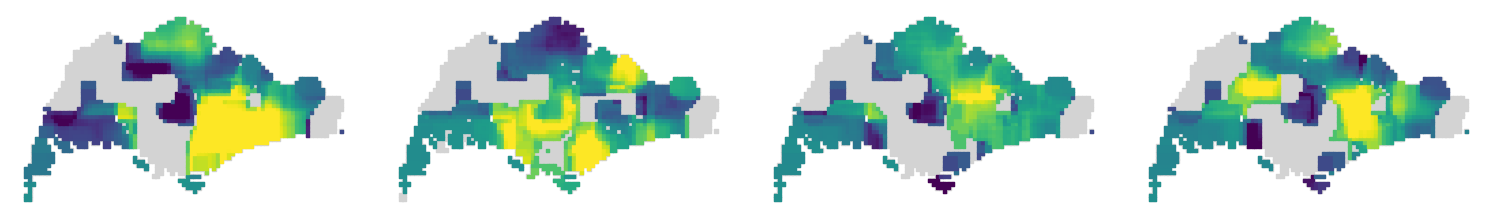


Delta UCP summary (normalised scale):
------------------------------------------------------------
UCP_2: mean=0.0475, std=0.2368, min=-0.6082, max=0.5556, +=730, -=740
UCP_3: mean=0.0448, std=0.1657, min=-0.2814, max=0.4713, +=857, -=694
UCP_4: mean=0.0174, std=0.1286, min=-0.4076, max=0.4575, +=789, -=618
UCP_5: mean=0.0283, std=0.1674, min=-0.5330, max=0.5483, +=721, -=734

Delta UCP analysis completed!


In [7]:
# Delta UCP: policy 2–5 minus policy 1 (balanced development baseline)
# Uses normalised UCP (UCP_X after transform in norm cell).
# Shared display scale: ±0.3 with 0.1-step ticks (matches admin area levels 1–5).

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

DELTA_CLIP = 0.3
DELTA_BIN_EDGES = [-0.3, -0.2, -0.1, 0.1, 0.2, 0.3]
DELTA_CBAR_TICKS = [-0.3, -0.2, -0.1, 0.0, 0.1, 0.2, 0.3]

print("Calculating Delta UCP (normalised UCP_X − UCP_1)...")

if "ucp_gdf" not in globals():
    raise RuntimeError("ucp_gdf not found — run the UCP calculation cell first.")

overlay_columns = [f"UCP_{i}" for i in range(1, 6) if f"UCP_{i}" in ucp_gdf.columns]
print(f"Found UCP columns: {overlay_columns}")

if len(overlay_columns) < 2 or "UCP_1" not in overlay_columns:
    raise RuntimeError("Need UCP_1 … UCP_5 columns. Run UCP calculation and norm cell first.")

baseline = ucp_gdf["UCP_1"].to_numpy(dtype=float)
optimisation_benefit_diff_columns = []

for i in range(2, 6):
    col = f"UCP_{i}"
    if col not in ucp_gdf.columns:
        continue
    diff_col = f"Delta-UCP_{i}"
    ucp_gdf[diff_col] = ucp_gdf[col].to_numpy(dtype=float) - baseline
    optimisation_benefit_diff_columns.append(diff_col)
    print(f"Created {diff_col} (normalised difference)")

if not optimisation_benefit_diff_columns:
    raise RuntimeError("No Delta-UCP columns created.")

# Fixed symmetric colour scale (aligned with admin area level bins)
_delta_vmin, _delta_vmax = -DELTA_CLIP, DELTA_CLIP
print(f"Map colour scale: [{_delta_vmin:.1f}, {_delta_vmax:.1f}] "
      f"(levels at ±0.1, ±0.2, ±0.3)")

_cmap_delta = "viridis"
_delta_norm = TwoSlopeNorm(vmin=_delta_vmin, vcenter=0.0, vmax=_delta_vmax)

print("Figure: Delta UCP — normalised difference vs. UCP_1")
print(f"Panels (left → right): {', '.join(optimisation_benefit_diff_columns)}")
print(f"Colour scale: Delta UCP (normalised UCP_X − UCP_1), "
      f"ticks {DELTA_CBAR_TICKS}, cmap={_cmap_delta}")

fig, axes = plt.subplots(1, len(optimisation_benefit_diff_columns),
                         figsize=(4 * len(optimisation_benefit_diff_columns), 4))
if not hasattr(axes, "__len__"):
    axes = [axes]
plt.subplots_adjust(wspace=0.08, top=0.98, bottom=0.02, left=0.04, right=0.96)

for i, diff_col in enumerate(optimisation_benefit_diff_columns):
    ax = axes[i]
    print(f"  Panel {i + 1}: {diff_col}")
    ax.scatter(ucp_gdf.geometry.x, ucp_gdf.geometry.y,
               color="lightgrey", s=5, marker="s")

    plot_data = ucp_gdf[ucp_gdf[diff_col] != 0]
    if len(plot_data) > 0:
        ax.scatter(
            plot_data.geometry.x, plot_data.geometry.y,
            c=plot_data[diff_col], cmap=_cmap_delta, norm=_delta_norm,
            s=5, marker="s",
        )
        d = plot_data[diff_col]
        print(f"    n={len(plot_data)}, range [{d.min():.4f}, {d.max():.4f}], mean={d.mean():.4f}")

    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_aspect("equal")

import os
os.makedirs('figure', exist_ok=True)
_delta_fig_path = 'figure/code_8_delta_ucp.png'
fig.savefig(_delta_fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure → {_delta_fig_path}")

plt.show()

print("\nDelta UCP summary (normalised scale):")
print("-" * 60)
for diff_col in optimisation_benefit_diff_columns:
    nz = ucp_gdf.loc[ucp_gdf[diff_col] != 0, diff_col]
    if len(nz) == 0:
        continue
    tag = f"UCP_{diff_col.split('_')[1]}"
    print(f"{tag}: mean={nz.mean():.4f}, std={nz.std():.4f}, "
          f"min={nz.min():.4f}, max={nz.max():.4f}, "
          f"+={(nz > 0).sum()}, -={(nz < 0).sum()}")

print("\nDelta UCP analysis completed!")


<a id="sec-5-admin"></a>

## 5. Analytics with administrative districts

District aggregation, PCA, K-means typing, and paper figures.


<a id="sec-5-1-district"></a>

### 5.1 District-level UCP

Load admin boundaries; join grid UCP to districts.


Total number of administrative districts loaded: 55
Number of administrative districts with overlapping points: 53


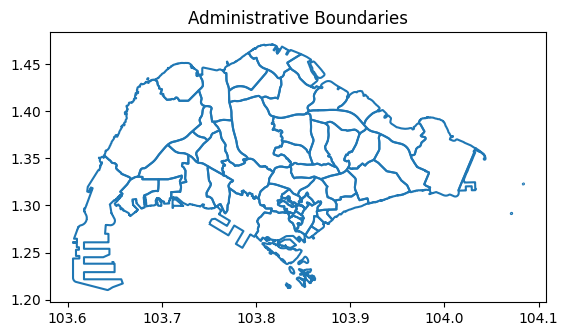

CRS of the administrative boundaries GeoDataFrame: EPSG:4326
Column names in the administrative boundaries GeoDataFrame:
Index(['Name', 'Description', 'geometry', 'PLN_AREA_N', 'PLN_AREA_C'], dtype='str')


In [8]:
# Import the administrative district GeoJSON file
admin_gdf = gpd.read_file("./data/data_administrative_districts.geojson")

# Output the total number of districts before filtering
print(f"Total number of administrative districts loaded: {len(admin_gdf)}")

# # Convert the CRS to EPSG:3414
# admin_gdf = admin_gdf.to_crs(epsg=3414)

# Parse 'PLN_AREA_N' from the 'Description' column, allowing for spaces in the area name
admin_gdf['PLN_AREA_N'] = admin_gdf['Description'].str.extract(r'<th>PLN_AREA_N</th>\s*<td>([\w\s]+)</td>')

# If 'PLN_AREA_N' contains three words, keep only the first two
# Handle potential NaN values by checking if x is a string
admin_gdf['PLN_AREA_N'] = admin_gdf['PLN_AREA_N'].apply(lambda x: ' '.join(x.split()[:2]) if isinstance(x, str) and len(x.split()) == 3 else x)

# Parse 'PLN_AREA_C' from the 'Description' column
admin_gdf['PLN_AREA_C'] = admin_gdf['Description'].str.extract(r'<th>PLN_AREA_C</th>\s*<td>([\w\s]+)</td>')

# Filter out areas with no overlapping points in ucp_gdf
# Fix the error by properly accessing the geometry column of ucp_gdf
admin_gdf = admin_gdf[admin_gdf.geometry.apply(lambda geom: ucp_gdf.geometry.within(geom).any())]

# Output the number of districts after filtering
print(f"Number of administrative districts with overlapping points: {len(admin_gdf)}")

# Visualise the administrative boundaries without fill and show boundary only
admin_gdf.boundary.plot()
plt.title('Administrative Boundaries')
plt.show()

# Output the Coordinate Reference System (CRS) of the GeoDataFrame
print("CRS of the administrative boundaries GeoDataFrame:", admin_gdf.crs)

# Output all column names from the GeoDataFrame
print("Column names in the administrative boundaries GeoDataFrame:")
print(admin_gdf.columns)

# # Output all samples from the GeoDataFrame without truncation
# print("All samples from the administrative boundaries GeoDataFrame without truncation:")
# print(admin_gdf.to_string())


<a id="sec-5-2-benefit"></a>

### 5.2 Optimisation benefit by district

District-level ΔUCP summaries and maps.


Calculating optimisation benefit differences by administrative areas...
Found optimisation benefit difference columns: ['Delta-UCP_2', 'Delta-UCP_3', 'Delta-UCP_4', 'Delta-UCP_5']
Figure: Optimisation benefit differences by administrative areas
Panels (left → right): Delta-UCP_2, Delta-UCP_3, Delta-UCP_4, Delta-UCP_5
Levels (6 equal bins, width 0.1): L1 [-0.3,-0.2), L2 [-0.2,-0.1), L3 [-0.1,0.0), L4 [0.0,0.1), L5 [0.1,0.2), L6 [0.2,0.3]
Level colours: L1–L3 grey (negative); L4–L6 policy tint → full colour (positive)
  Panel 1: Delta-UCP_2

DELTA-UCP_2 Administrative Area Statistics:
  Number of areas: 53
  Mean optimisation benefit difference: 0.112
  Std optimisation benefit difference: 0.191
  Min optimisation benefit difference: -0.207
  Max optimisation benefit difference: 0.492
  Display range used: [-0.3, 0.3] (6 equal levels, width 0.1; split at 0)
  Values below -0.3: 0
  Values above 0.3: 12
  Panel 2: Delta-UCP_3

DELTA-UCP_3 Administrative Area Statistics:
  Number of areas:

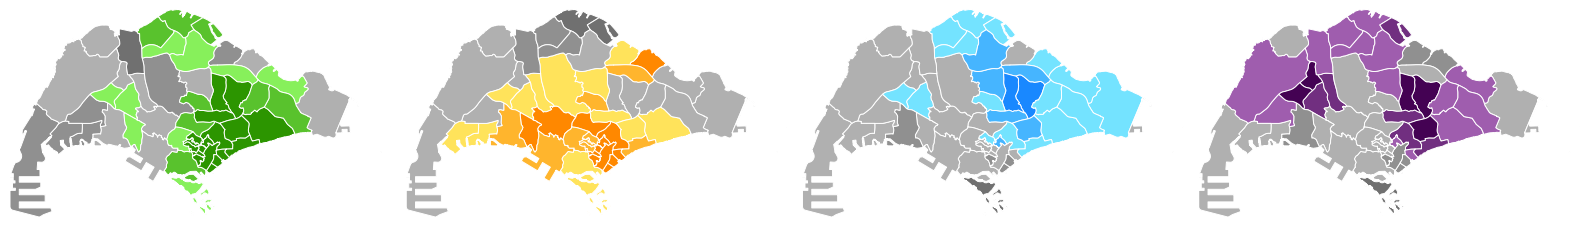


Administrative Area Optimisation Benefit Difference Summary:

DELTA-UCP_2:
----------------------------------------
  ROCHOR                   :    0.492 (n=6)
  KALLANG                  :    0.485 (n=26)
  TOA PAYOH                :    0.444 (n=27)
  BEDOK                    :    0.416 (n=72)
  MUSEUM                   :    0.410 (n=3)
  GEYLANG                  :    0.373 (n=31)
  NEWTON                   :    0.372 (n=8)
  MARINA EAST              :    0.353 (n=8)
  MARINE PARADE            :    0.353 (n=19)
  RIVER VALLEY             :    0.324 (n=5)
  SINGAPORE RIVER          :    0.320 (n=3)
  DOWNTOWN CORE            :    0.310 (n=17)
  ORCHARD                  :    0.280 (n=3)
  HOUGANG                  :    0.263 (n=44)
  OUTRAM                   :    0.247 (n=4)
  STRAITS VIEW             :    0.246 (n=2)
  MARINA SOUTH             :    0.245 (n=5)
  SERANGOON                :    0.236 (n=35)
  TAMPINES                 :    0.185 (n=64)
  SEMBAWANG                :    0.145 

In [9]:
# Calculate and visualise optimisation benefit differences by administrative areas
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch

print("Calculating optimisation benefit differences by administrative areas...")

# Match Delta UCP map scale (±0.3); 6 equal-width levels (0.1 each, split at 0)
DELTA_CLIP = 0.3
DELTA_BIN_EDGES = [-0.3, -0.2, -0.1, 0.0, 0.1, 0.2, 0.3]
DELTA_LEVEL_LABELS = [1, 2, 3, 4, 5, 6]
fixed_bins = DELTA_BIN_EDGES

LEVEL_GREY_COLOURS = ['#707070', '#909090', '#B0B0B0']


def _lighten_hex(hex_colour, amount=0.3):
    rgb = to_rgb(hex_colour)
    return '#{:02x}{:02x}{:02x}'.format(
        *(int(min(1.0, c + amount) * 255) for c in rgb)
    )


def _policy_level_colours(base_colour):
    """Levels 1–3 grey (negative); 4–6 policy tint → full colour (positive)."""
    return LEVEL_GREY_COLOURS + [
        _lighten_hex(base_colour, 0.36),  # Level 4: 0.0 to 0.1 (was 0.45 — too pale vs white edges)
        _lighten_hex(base_colour, 0.18),  # Level 5: 0.1 to 0.2
        base_colour,                       # Level 6: 0.2 to 0.3
    ]

# Check if we have the required data
if 'ucp_gdf' in locals() or 'ucp_gdf' in globals():
    # Get optimisation benefit difference columns
    optimisation_benefit_diff_columns = [col for col in ucp_gdf.columns if col.startswith('Delta-UCP')]
    
    if optimisation_benefit_diff_columns and 'admin_gdf' in locals():
        print(f"Found optimisation benefit difference columns: {optimisation_benefit_diff_columns}")
        
        # Calculate mean optimisation benefit differences for each administrative area
        admin_results = {}
        
        for diff_col in optimisation_benefit_diff_columns:
            policy_name = diff_col.replace('_optimisation_benefit_diff', '')
            admin_results[policy_name] = []
            
            for idx, admin_area in admin_gdf.iterrows():
                # Find UCP points within this administrative area
                within_mask = ucp_gdf.geometry.within(admin_area.geometry)
                points_in_area = ucp_gdf[within_mask]
                
                if len(points_in_area) > 0:
                    # Calculate mean optimisation benefit difference for this area
                    mean_diff = points_in_area[diff_col].mean()
                    admin_results[policy_name].append({
                        'PLN_AREA_N': admin_area['PLN_AREA_N'],
                        'geometry': admin_area.geometry,
                        'mean_optimisation_benefit_diff': mean_diff,
                        'point_count': len(points_in_area)
                    })
        
        # Create visualisation with administrative areas
        if admin_results:
            # Create subplots - one for each policy
            n_policies = len(admin_results)
            fig, axes = plt.subplots(1, n_policies, figsize=(4*n_policies, 6))
            
            # If only one policy, make axes iterable
            if n_policies == 1:
                axes = [axes]
            
            print("Figure: Optimisation benefit differences by administrative areas")
            print(f"Panels (left → right): {', '.join(admin_results.keys())}")
            print("Levels (6 equal bins, width 0.1): "
                  "L1 [-0.3,-0.2), L2 [-0.2,-0.1), L3 [-0.1,0.0), "
                  "L4 [0.0,0.1), L5 [0.1,0.2), L6 [0.2,0.3]")
            print("Level colours: L1–L3 grey (negative); L4–L6 policy tint → full colour (positive)")

            plt.subplots_adjust(wspace=0.0001, top=0.98, bottom=0.02)
            
            # Define custom colours for each policy
            policy_colours = ['#2C9500', '#FF8800', '#1988FF', '#440253']
            
            for i, (policy_name, policy_data) in enumerate(admin_results.items()):
                ax = axes[i]
                print(f"  Panel {i + 1}: {policy_name}")
                
                if policy_data:
                    # Create GeoDataFrame for this policy's administrative results
                    policy_admin_gdf = gpd.GeoDataFrame(policy_data)
                    
                    # Clip to display range, then classify into 6 equal-width levels
                    diff_values = policy_admin_gdf['mean_optimisation_benefit_diff']
                    clipped_values = np.clip(diff_values, -DELTA_CLIP, DELTA_CLIP)
                    
                    policy_admin_gdf['diff_level'] = pd.cut(
                        clipped_values, bins=fixed_bins, labels=DELTA_LEVEL_LABELS,
                        include_lowest=True,
                    )
                    
                    base_colour = policy_colours[i % len(policy_colours)]
                    discrete_colours = _policy_level_colours(base_colour)
                    
                    # Create discrete colourmap
                    cmap = mcolors.ListedColormap(discrete_colours)
                    
                    # Plot administrative boundaries with discrete levels
                    policy_admin_gdf.plot(
                        column='diff_level',
                        cmap=cmap,
                        ax=ax,
                        legend=False,
                        edgecolor='white',
                        linewidth=0.7,
                        categorical=True
                    )
                    
                    # Print statistics for this policy
                    mean_values = [area['mean_optimisation_benefit_diff'] for area in policy_data]
                    print(f"\n{policy_name.upper()} Administrative Area Statistics:")
                    print(f"  Number of areas: {len(policy_data)}")
                    print(f"  Mean optimisation benefit difference: {np.mean(mean_values):.3f}")
                    print(f"  Std optimisation benefit difference: {np.std(mean_values):.3f}")
                    print(f"  Min optimisation benefit difference: {min(mean_values):.3f}")
                    print(f"  Max optimisation benefit difference: {max(mean_values):.3f}")
                    print(f"  Display range used: [-{DELTA_CLIP:.1f}, {DELTA_CLIP:.1f}] "
                          f"(6 equal levels, width 0.1; split at 0)")
                    print(f"  Values below -{DELTA_CLIP:.1f}: "
                          f"{sum(1 for v in mean_values if v < -DELTA_CLIP)}")
                    print(f"  Values above {DELTA_CLIP:.1f}: "
                          f"{sum(1 for v in mean_values if v > DELTA_CLIP)}")
                
                # Remove axis ticks and labels
                ax.set_xticks([])
                ax.set_yticks([])
                ax.set_xlabel('')
                ax.set_ylabel('')
                
                # Remove subplot borders
                ax.spines['top'].set_visible(False)
                ax.spines['right'].set_visible(False)
                ax.spines['bottom'].set_visible(False)
                ax.spines['left'].set_visible(False)
                
                # Set aspect ratio and make plots more compact by adjusting margins
                ax.set_aspect('equal')
                ax.margins(0)
            
            plt.tight_layout()
            import os
            os.makedirs('figure', exist_ok=True)
            _district_fig_path = 'figure/code_8_delta_ucp_district.png'
            fig.savefig(_district_fig_path, dpi=300, bbox_inches='tight')
            print(f"\nSaved figure → {_district_fig_path}")

            plt.show()
            
            # Create a summary table
            print("\nAdministrative Area Optimisation Benefit Difference Summary:")
            print("=" * 80)
            for policy_name, policy_data in admin_results.items():
                if policy_data:
                    print(f"\n{policy_name.upper()}:")
                    print("-" * 40)
                    for area in sorted(policy_data, key=lambda x: x['mean_optimisation_benefit_diff'], reverse=True):
                        print(f"  {area['PLN_AREA_N']:<25}: {area['mean_optimisation_benefit_diff']:>8.3f} "
                              f"(n={area['point_count']})")
        else:
            print("No administrative area results to visualise.")
    else:
        print("Error: Required data not found.")
        if not optimisation_benefit_diff_columns:
            print("  - No optimisation benefit difference columns found")
        if 'admin_gdf' not in locals():
            print("  - Administrative boundaries data (admin_gdf) not found")
else:
    print("Error: ucp_gdf not found in the current environment.")

print("\nAdministrative area optimisation benefit difference analysis completed!")


<a id="sec-5-3-levels"></a>

### 5.3 Level distribution

Administrative area level distributions per policy.


Creating level distribution visualisation for administrative areas...

Delta-UCP_2 - Level distribution (6 equal bins, width 0.1):
  Level 1: 1 areas (1.9%)
  Level 2: 6 areas (11.3%)
  Level 3: 11 areas (20.8%)
  Level 4: 9 areas (17.0%)
  Level 5: 8 areas (15.1%)
  Level 6: 18 areas (34.0%)
  Combined L4+L5+L6 [0.0, 0.3]: 35 areas (66.0%)

Delta-UCP_3 - Level distribution (6 equal bins, width 0.1):
  Level 1: 2 areas (3.8%)
  Level 2: 3 areas (5.7%)
  Level 3: 13 areas (24.5%)
  Level 4: 13 areas (24.5%)
  Level 5: 9 areas (17.0%)
  Level 6: 13 areas (24.5%)
  Combined L4+L5+L6 [0.0, 0.3]: 35 areas (66.0%)

Delta-UCP_4 - Level distribution (6 equal bins, width 0.1):
  Level 1: 1 areas (1.9%)
  Level 2: 4 areas (7.5%)
  Level 3: 24 areas (45.3%)
  Level 4: 16 areas (30.2%)
  Level 5: 6 areas (11.3%)
  Level 6: 2 areas (3.8%)
  Combined L4+L5+L6 [0.0, 0.3]: 24 areas (45.3%)

Delta-UCP_5 - Level distribution (6 equal bins, width 0.1):
  Level 1: 1 areas (1.9%)
  Level 2: 7 areas (13.2%)

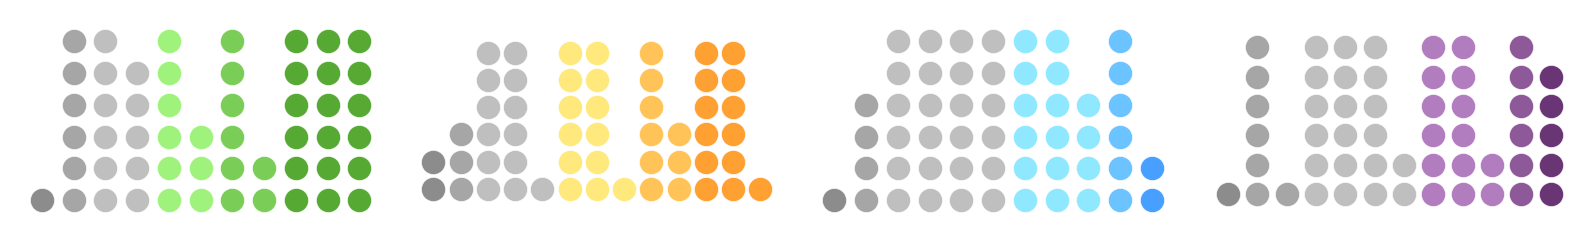

In [10]:
# Create level distribution visualisation for each policy
print("Creating level distribution visualisation for administrative areas...")

if 'admin_results' in locals() and admin_results:
    # Match district map cell: 6 equal-width levels on ±0.3
    DELTA_CLIP = 0.3
    fixed_bins = [-0.3, -0.2, -0.1, 0.0, 0.1, 0.2, 0.3]
    level_labels = [1, 2, 3, 4, 5, 6]
    policy_colours = ['#2C9500', '#FF8800', '#1988FF', '#440253']

    if '_policy_level_colours' not in globals():
        LEVEL_GREY_COLOURS = ['#707070', '#909090', '#B0B0B0']

        def _lighten_hex(hex_colour, amount=0.3):
            from matplotlib.colors import to_rgb
            rgb = to_rgb(hex_colour)
            return '#{:02x}{:02x}{:02x}'.format(
                *(int(min(1.0, c + amount) * 255) for c in rgb)
            )

        def _policy_level_colours(base_colour):
            return LEVEL_GREY_COLOURS + [
                _lighten_hex(base_colour, 0.36),
                _lighten_hex(base_colour, 0.18),
                base_colour,
            ]

    n_policies = len(admin_results)
    fig, axes = plt.subplots(1, n_policies, figsize=(4 * n_policies, 6))
    if n_policies == 1:
        axes = [axes]

    plt.subplots_adjust(wspace=0.1)

    for i, (policy_name, policy_data) in enumerate(admin_results.items()):
        ax = axes[i]

        if policy_data:
            diff_values = [area['mean_optimisation_benefit_diff'] for area in policy_data]
            clipped_values = np.clip(diff_values, -DELTA_CLIP, DELTA_CLIP)

            levels = pd.cut(
                clipped_values, bins=fixed_bins, labels=level_labels, include_lowest=True
            )
            level_counts = levels.value_counts().sort_index()
            total_areas = len(diff_values)

            print(f"\n{policy_name} - Level distribution (6 equal bins, width 0.1):")
            for lv in level_labels:
                cnt = int(level_counts.get(lv, 0))
                pct = (cnt / total_areas) * 100 if total_areas > 0 else 0
                print(f"  Level {lv}: {cnt} areas ({pct:.1f}%)")
            l4 = int(level_counts.get(4, 0))
            l5 = int(level_counts.get(5, 0))
            l6 = int(level_counts.get(6, 0))
            positive_count = l4 + l5 + l6
            if total_areas:
                print(f"  Combined L4+L5+L6 [0.0, 0.3]: {positive_count} areas "
                      f"({positive_count / total_areas * 100:.1f}%)")

            base_colour = policy_colours[i % len(policy_colours)]
            level_colours = _policy_level_colours(base_colour)

            dot_size = 300
            grid_spacing = 0.1
            dots_per_column = 6
            current_col = 0

            for level in level_labels:
                count = int(level_counts.get(level, 0))
                colour = level_colours[level - 1]

                if count > 0:
                    x_positions = []
                    y_positions = []
                    cols_needed = (count - 1) // dots_per_column + 1

                    for dot_idx in range(count):
                        col_within_level = dot_idx // dots_per_column
                        row_within_level = dot_idx % dots_per_column
                        x_positions.append((current_col + col_within_level) * grid_spacing)
                        y_positions.append(row_within_level * grid_spacing)

                    ax.scatter(
                        x_positions, y_positions, s=dot_size, c=colour, alpha=0.8,
                        edgecolors='white', linewidth=0.5,
                    )
                    current_col += cols_needed

            ax.set_xlim(-0.1, max(current_col * grid_spacing, 0.1))
            ax.set_ylim(-0.1, dots_per_column * grid_spacing)
            ax.set_aspect('equal')
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)

    plt.tight_layout()
    import os
    os.makedirs('figure', exist_ok=True)
    _prop_fig_path = 'figure/code_8_delta_district_proportion.png'
    fig.savefig(_prop_fig_path, dpi=300, bbox_inches='tight')
    print(f"\nSaved figure → {_prop_fig_path}")
    plt.show()

else:
    print("No administrative area results available for level distribution visualisation.")


<a id="sec-5-4-pca"></a>

### 5.4 PCA of ΔUCP

Latent structure of policy-specific UCP differences.


Creating policy optimisation difference gradient latent analysis...


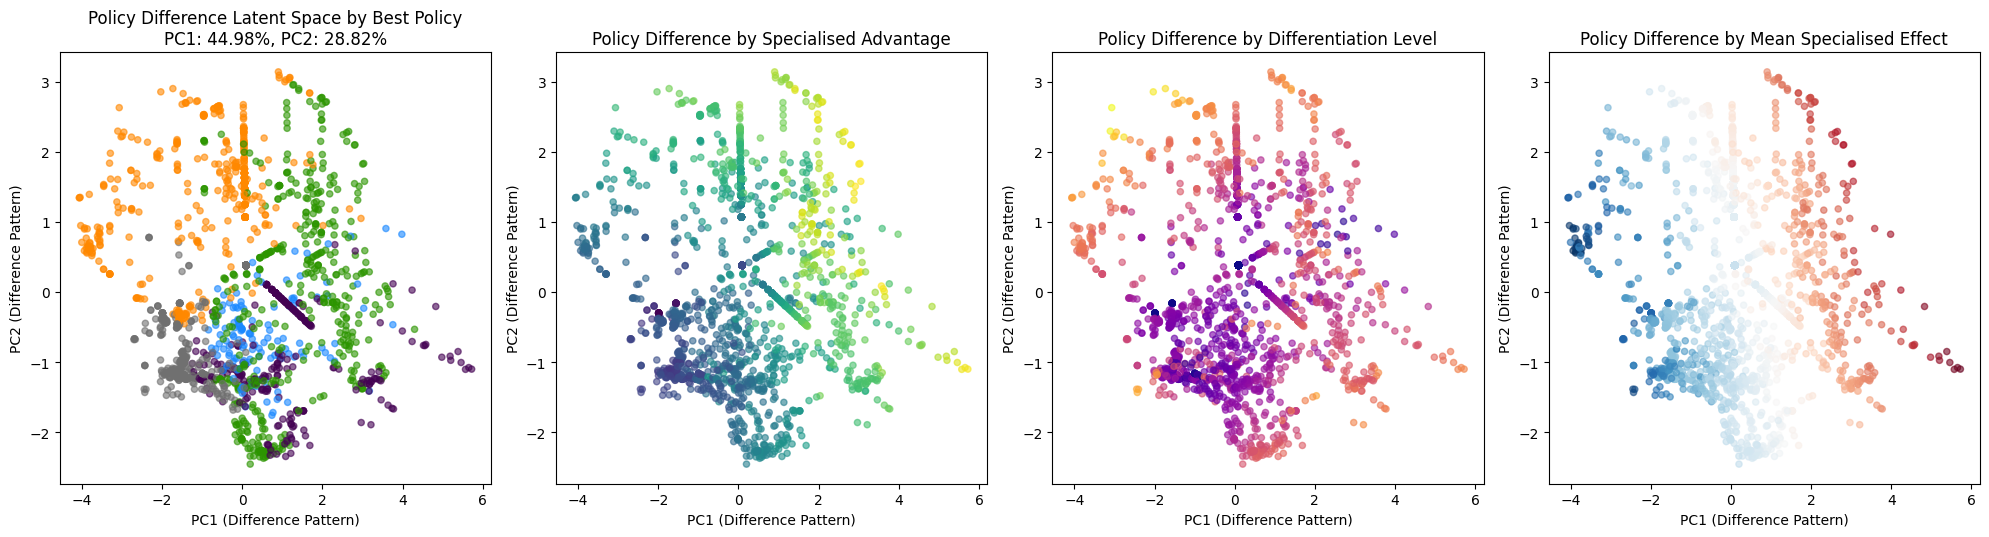


Policy Difference Latent Space Analysis Summary:
Policy Difference PCA - PC1: 44.98% variance
Policy Difference PCA - PC2: 28.82% variance
Total explained variance: 73.81%

Policy Recommendation Distribution:
  Baseline Policy Focus: 260 areas (12.4%)
  Maintain Status Quo: 401 areas (19.1%)
  Policy Flexible: 104 areas (5.0%)
  Strong Specialised Policy: 1137 areas (54.2%)
  Moderate Specialised Policy: 194 areas (9.3%)


In [11]:
# Policy optimisation difference gradient latent analysis
print("Creating policy optimisation difference gradient latent analysis...")

# Import required modules
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from collections import Counter

# Extract policy difference data (relative to baseline policy differences)
policy_diffs = ['Delta-UCP_2', 'Delta-UCP_3', 
                'Delta-UCP_4', 'Delta-UCP_5']

# Calculate policy difference gradients
policy_diff_data = ucp_gdf[policy_diffs].fillna(0)

# Add baseline policy priority as reference
policy_diff_with_base = policy_diff_data.copy()
policy_diff_with_base['UCP_1_baseline'] = ucp_gdf['UCP_1']

# Standardise
scaler = StandardScaler()
diff_data_scaled = scaler.fit_transform(policy_diff_with_base)

# PCA dimensionality reduction
pca_diff = PCA(n_components=2)
diff_latent = pca_diff.fit_transform(diff_data_scaled)

# Create visualisation - using one row with four subplots
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

# Define custom colours for each policy (matching the administrative area visualisation)
policy_colours = ['#2C9500', '#FF8800', '#1988FF', '#440253']

# Subplot 1: Coloured by optimal specialised policy
ax = axes[0]
best_specialised_policies = []
best_diff_values = []
for idx, row in ucp_gdf.iterrows():
    diffs = [row['Delta-UCP_2'], row['Delta-UCP_3'], 
             row['Delta-UCP_4'], row['Delta-UCP_5']]
    max_diff = max(diffs)
    if max_diff > 0.05:  # Significant specialised policy advantage
        best_policy = np.argmax(diffs) + 2
    else:
        best_policy = 1  # Baseline policy optimal
    best_specialised_policies.append(best_policy)
    best_diff_values.append(max_diff)

# Create custom colourmap for policies
from matplotlib.colors import ListedColormap
policy_cmap_colours = ['#707070'] + policy_colours  # Grey for baseline, then policy colours
policy_cmap = ListedColormap(policy_cmap_colours)

scatter1 = ax.scatter(diff_latent[:, 0], diff_latent[:, 1], 
                     c=best_specialised_policies, cmap=policy_cmap, alpha=0.6, s=20)
ax.set_title(f'Policy Difference Latent Space by Best Policy\nPC1: {pca_diff.explained_variance_ratio_[0]:.2%}, PC2: {pca_diff.explained_variance_ratio_[1]:.2%}')
ax.set_xlabel('PC1 (Difference Pattern)')
ax.set_ylabel('PC2 (Difference Pattern)')
ax.set_box_aspect(1)  # Force square aspect ratio

# Subplot 2: Coloured by specialised policy advantage intensity
ax = axes[1]
scatter2 = ax.scatter(diff_latent[:, 0], diff_latent[:, 1], 
                     c=best_diff_values, cmap='viridis', alpha=0.6, s=20)
ax.set_title('Policy Difference by Specialised Advantage')
ax.set_xlabel('PC1 (Difference Pattern)')
ax.set_ylabel('PC2 (Difference Pattern)')
ax.set_box_aspect(1)  # Force square aspect ratio

# Subplot 3: Coloured by policy differentiation level
ax = axes[2]
policy_differentiation = ucp_gdf[policy_diffs].std(axis=1)
scatter3 = ax.scatter(diff_latent[:, 0], diff_latent[:, 1], 
                     c=policy_differentiation, cmap='plasma', alpha=0.6, s=20)
ax.set_title('Policy Difference by Differentiation Level')
ax.set_xlabel('PC1 (Difference Pattern)')
ax.set_ylabel('PC2 (Difference Pattern)')
ax.set_box_aspect(1)  # Force square aspect ratio

# Subplot 4: Coloured by average specialised policy effect
ax = axes[3]
mean_specialised_effect = ucp_gdf[policy_diffs].mean(axis=1)
scatter4 = ax.scatter(diff_latent[:, 0], diff_latent[:, 1], 
                     c=mean_specialised_effect, cmap='RdBu_r', alpha=0.6, s=20)
ax.set_title('Policy Difference by Mean Specialised Effect')
ax.set_xlabel('PC1 (Difference Pattern)')
ax.set_ylabel('PC2 (Difference Pattern)')
ax.set_box_aspect(1)  # Force square aspect ratio

plt.tight_layout()
plt.show()

# Print latent space interpretation
print("\nPolicy Difference Latent Space Analysis Summary:")
print("=" * 60)
print(f"Policy Difference PCA - PC1: {pca_diff.explained_variance_ratio_[0]:.2%} variance")
print(f"Policy Difference PCA - PC2: {pca_diff.explained_variance_ratio_[1]:.2%} variance")
print(f"Total explained variance: {sum(pca_diff.explained_variance_ratio_):.2%}")

# Analyse policy recommendation types
policy_recommendations = []
for i, row in ucp_gdf.iterrows():
    max_diff = max([row['Delta-UCP_2'], row['Delta-UCP_3'], 
                    row['Delta-UCP_4'], row['Delta-UCP_5']])
    baseline_priority = row['UCP_1']
    
    if max_diff > 0.1:  # Strong specialised policy advantage
        rec = "Strong Specialised Policy"
    elif max_diff > 0.05:  # Moderate specialised policy advantage
        rec = "Moderate Specialised Policy"
    elif baseline_priority > 0.7:  # High baseline policy priority
        rec = "Baseline Policy Focus"
    elif baseline_priority < 0.3:  # Low priority areas
        rec = "Maintain Status Quo"
    else:
        rec = "Policy Flexible"
    policy_recommendations.append(rec)

recommendation_counts = Counter(policy_recommendations)
print("\nPolicy Recommendation Distribution:")
for rec, count in recommendation_counts.items():
    percentage = (count / len(policy_recommendations)) * 100
    print(f"  {rec}: {count} areas ({percentage:.1f}%)")

<a id="sec-5-5-latent"></a>

### 5.5 Policy latent panels

1×4 panels: scatter, KDE, decision boundary, ellipse.


/Users/sijieyang/anaconda3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/sijieyang/anaconda3/lib/python3.11/site-packages/seaborn/distributions.py:1176: UserWarning: The following kwargs were not used by contour: 'linewidth'
  cset = contour_func(
/Users/sijieyang/anaconda3/lib/python3.11/site-packages/seaborn/distributions.py:1176: UserWarning: The following kwargs were not used by contour: 'linewidth'
  cset = contour_func(
/Users/sijieyang/anaconda3/lib/python3.11/site-packages/seaborn/distributions.py:1176: UserWarning: The following kwargs were not used by contour: 'linewidth'
  cset = contour_func(
/Users/sijieyang/anaconda3/lib/python3.11/site-packages/seaborn/distributions.py:1176: UserWarning: The following kwargs were not used by contour: 'linew

Saved figure → figure/code_8_delta_ucp_pca.png


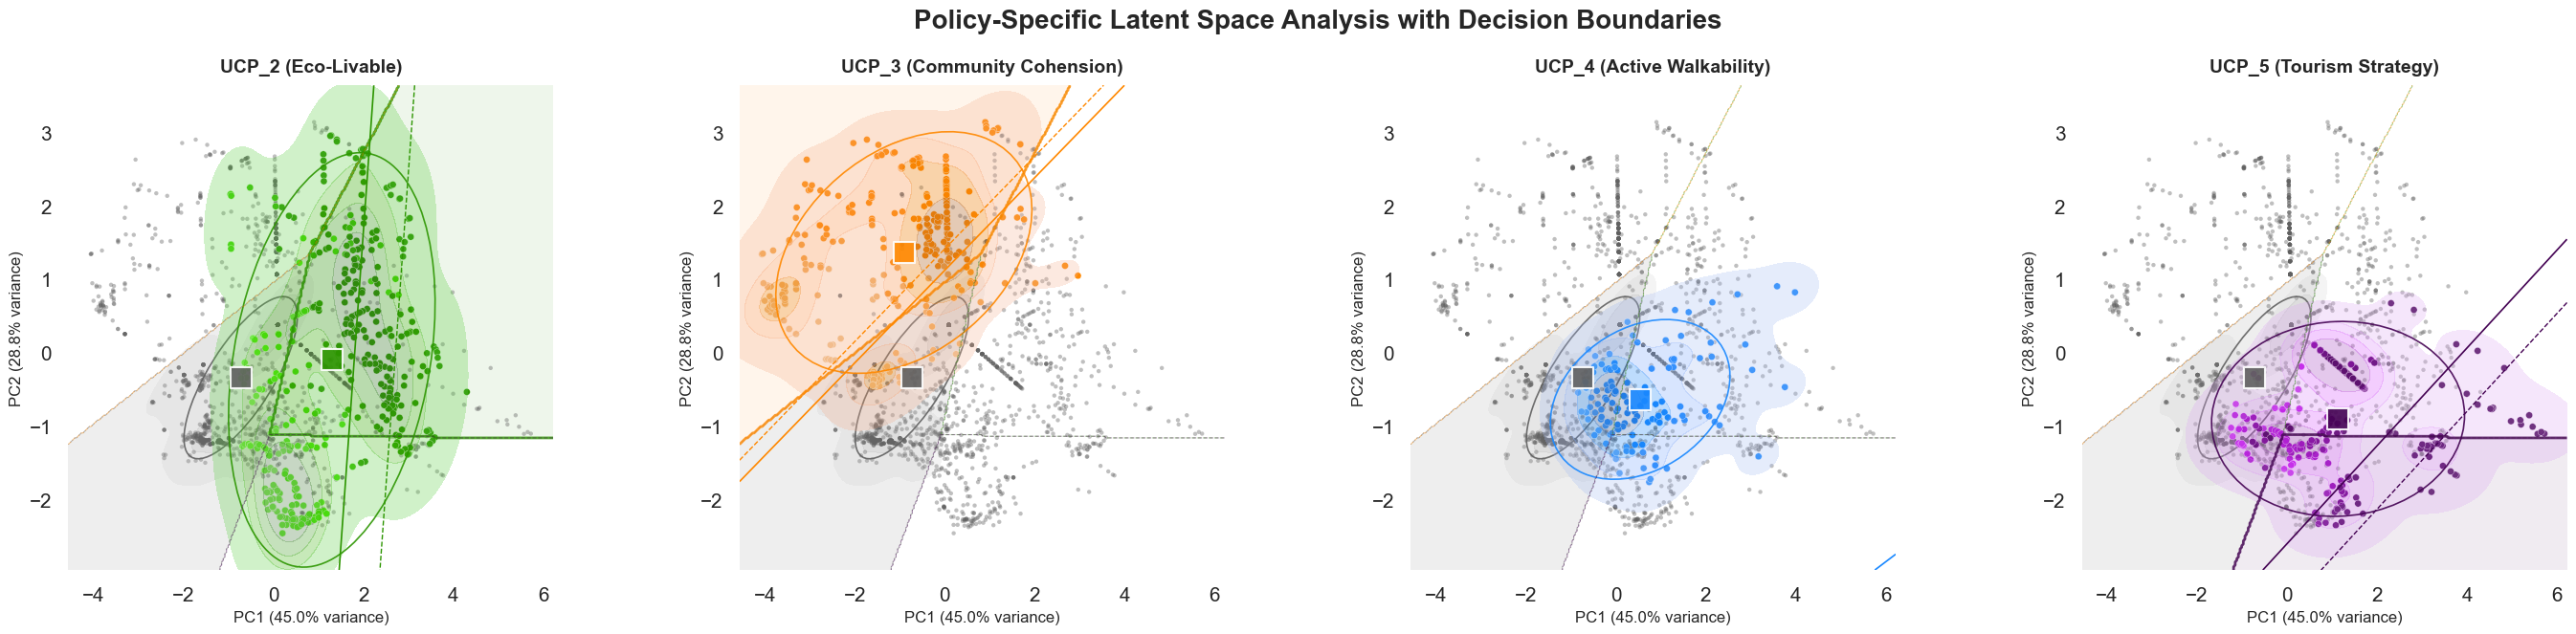

In [12]:
# Policy-specific latent panels (1x4): scatter + KDE + decision boundary + ellipse
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import to_rgb
from matplotlib.patches import Ellipse
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from colorsys import rgb_to_hls, hls_to_rgb

sns.set_context("talk", font_scale=0.9)
sns.set_style("white")

# --- data prep ---
policy_diffs = ['Delta-UCP_2', 'Delta-UCP_3', 
                'Delta-UCP_4', 'Delta-UCP_5']
diff_df = ucp_gdf[policy_diffs].fillna(0).copy()
diff_df['UCP_1_baseline'] = ucp_gdf['UCP_1']

scaler = StandardScaler()
X = scaler.fit_transform(diff_df)

pca = PCA(n_components=2, random_state=0)
Z = pca.fit_transform(X)  # latent 2D

diffs = ucp_gdf[policy_diffs].values  # shape (n,4) for P2..P5
max_idx = np.argmax(diffs, axis=1)               # 0..3 => policy2..5
max_val = np.take_along_axis(diffs, max_idx[:,None], axis=1).ravel()
best_policy = np.where(max_val > 0.05, max_idx + 2, 1)  # 1=baseline if weak advantage

BASELINE = '#606060'  # darker gray for better visibility in papers
PALETTE = {1:'#606060', 2:'#2C9500', 3:'#FF8800', 4:'#1988FF', 5:'#440253'}

def hex2rgb(h):
    r,g,b = to_rgb(h); return np.array([r,g,b])

def shade_by_strength(base_hex, val):
    # perceptual HLS shading: val∈[0,1] (stronger -> darker & slightly more saturated)
    r,g,b = to_rgb(base_hex)
    h,l,s = rgb_to_hls(r,g,b)
    l_new = 1.0 - (1.0 - l) * val
    s_new = s * (0.6 + 0.4*val)
    rr,gg,bb = hls_to_rgb(h, l_new, s_new)
    return (rr,gg,bb)

def add_confidence_ellipse(ax, x, y, color, q=2.0):
    # q≈2: about 95% if Gaussian
    if len(x) < 5: 
        return
    X = np.column_stack([x, y])
    mu = X.mean(axis=0)
    cov = np.cov(X, rowvar=False)
    eigvals, eigvecs = np.linalg.eigh(cov)
    order = eigvals.argsort()[::-1]
    eigvals, eigvecs = eigvals[order], eigvecs[:,order]
    angle = np.degrees(np.arctan2(*eigvecs[:,0][::-1]))
    width, height = 2*q*np.sqrt(eigvals)
    e = Ellipse(xy=mu, width=width, height=height, angle=angle,
                edgecolor=color, facecolor='none', lw=1.2, alpha=0.9)
    ax.add_patch(e)

# Train multi-class classifier for decision boundaries
clf_multi = LogisticRegression(multi_class='multinomial', max_iter=2000, random_state=42)
clf_multi.fit(Z, best_policy)

fig, axes = plt.subplots(1, 4, figsize=(28, 6), constrained_layout=True)

# Add main title
fig.suptitle('Policy-Specific Latent Space Analysis with Decision Boundaries', 
             fontsize=20, fontweight='bold', y=1.08)

# common bounds
x_min, x_max = Z[:,0].min()-0.5, Z[:,0].max()+0.5
y_min, y_max = Z[:,1].min()-0.5, Z[:,1].max()+0.5

# Create decision boundary grid
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))
grid_points = np.c_[xx.ravel(), yy.ravel()]
decision_proba = clf_multi.predict_proba(grid_points)
decision_pred = clf_multi.predict(grid_points).reshape(xx.shape)

policies = [2,3,4,5]
names = {2:'UCP_2 (Eco-Livable)', 3:'UCP_3 (Community Cohension)', 4:'UCP_4 (Active Walkability)', 5:'UCP_5 (Tourism Strategy)'}

# Get baseline mask for all subplots
mask_baseline = (best_policy == 1)

for idx, p in enumerate(policies):
    ax = axes[idx]
    ax.set_box_aspect(1)
    sns.despine(ax=ax, left=True, bottom=True)
    
    # Add axis labels and subtitle
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)', fontsize=12)
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)', fontsize=12)
    ax.set_title(names[p], fontsize=14, fontweight='bold', pad=10)
    
    color = PALETTE[p]
    j = p - 2  # column in diffs
    adv = diffs[:, j]

    # Add background decision regions with deeper coloring
    # Create a mask for current policy's decision region
    policy_region_mask = (decision_pred == p)
    baseline_region_mask = (decision_pred == 1)
    
    # Color the background regions with deeper colors
    if policy_region_mask.any():
        # Current policy region in very light version of policy color
        policy_bg_color = hex2rgb(color) * 0.15 + 0.85  # very light tint
        ax.contourf(xx, yy, policy_region_mask.astype(float), levels=[0.5, 1.5], 
                   colors=[policy_bg_color], alpha=0.5)
    
    if baseline_region_mask.any():
        # Baseline region in very light gray
        baseline_bg_color = hex2rgb(BASELINE) * 0.2 + 0.8  # very light gray
        ax.contourf(xx, yy, baseline_region_mask.astype(float), levels=[0.5, 1.5], 
                   colors=[baseline_bg_color], alpha=0.5)

    # Add decision boundary contours for all policies
    for other_p in [1, 2, 3, 4, 5]:
        if other_p == p:
            # Current policy boundary - more prominent
            boundary_mask = (decision_pred == other_p)
            if boundary_mask.any():
                ax.contour(xx, yy, boundary_mask.astype(float), levels=[0.5], 
                          colors=[PALETTE[other_p]], linewidths=[2.0], alpha=0.8)
        else:
            # Other policy boundaries - more subtle
            boundary_mask = (decision_pred == other_p)
            if boundary_mask.any():
                ax.contour(xx, yy, boundary_mask.astype(float), levels=[0.5], 
                          colors=[PALETTE[other_p]], linewidths=[0.8], alpha=0.4, linestyles='--')

    # background points (all) in darker gray for better visibility
    ax.scatter(Z[:,0], Z[:,1], s=10, c=BASELINE, ec='none', alpha=0.4)

    # Add baseline region visualization on each subplot
    if mask_baseline.sum() >= 30:
        # KDE for baseline region
        sns.kdeplot(x=Z[mask_baseline,0], y=Z[mask_baseline,1], ax=ax, levels=3, thresh=0.05,
                    fill=True, alpha=0.15, color=BASELINE, linewidth=0.8, linestyles='--')
    
    # Add baseline confidence ellipse
    add_confidence_ellipse(ax, Z[mask_baseline,0], Z[mask_baseline,1], color=BASELINE, q=1.5)

    # shading strength (robust 10–90%)
    q1, q9 = np.quantile(adv, [0.10, 0.90])
    strength = np.clip((adv - q1) / (q9 - q1 + 1e-9), 0.0, 1.0)
    colors = [shade_by_strength(color, t) for t in strength]

    # highlight points where this policy is best
    mask_best = (best_policy == p)
    ax.scatter(Z[mask_best,0], Z[mask_best,1], s=26, c=np.array(colors)[mask_best],
               ec='white', lw=0.25, alpha=0.98)

    # KDE density (policy-best subset)
    if mask_best.sum() >= 30:
        sns.kdeplot(x=Z[mask_best,0], y=Z[mask_best,1], ax=ax, levels=5, thresh=0.02,
                    fill=True, alpha=0.28, color=color, linewidth=0.6)

    # Decision boundary via logistic regression (this policy vs others)
    y_bin = (best_policy == p).astype(int)
    if y_bin.sum() > 5 and (len(y_bin) - y_bin.sum()) > 5:
        clf = LogisticRegression(max_iter=200, solver='lbfgs')
        clf.fit(Z, y_bin)
        proba = clf.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:,1].reshape(xx.shape)
        cs = ax.contour(xx, yy, proba, levels=[0.5, 0.7], colors=[color, color],
                        linestyles=['-', '--'], linewidths=[1.2, 1.0])

    # Confidence ellipse (≈95%) for policy-best subset
    add_confidence_ellipse(ax, Z[mask_best,0], Z[mask_best,1], color=color, q=2.0)

    # Add centroid markers for baseline and current policy
    if mask_baseline.sum() > 0:
        baseline_centroid = Z[mask_baseline].mean(axis=0)
        # Add baseline marker (doubled size)
        ax.scatter(baseline_centroid[0], baseline_centroid[1], s=240, c=BASELINE, 
                  marker='s', ec='white', lw=1.5, alpha=0.9, zorder=10)
    
    if mask_best.sum() > 0:
        policy_centroid = Z[mask_best].mean(axis=0)
        # Add policy marker (doubled size)
        ax.scatter(policy_centroid[0], policy_centroid[1], s=240, c=color, 
                  marker='s', ec='white', lw=1.5, alpha=0.9, zorder=10)

    ax.set_xlim(x_min, x_max); ax.set_ylim(y_min, y_max)

import os
os.makedirs('figure', exist_ok=True)
_pca_fig_path = 'figure/code_8_delta_ucp_pca.png'
fig.savefig(_pca_fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure → {_pca_fig_path}")

plt.show()

<a id="sec-5-6-pc"></a>

### 5.6 PC distribution plots

Policy-specific distributions in PC space.


Saved figure → figure/code_8_delta_ucp_pc_1.png


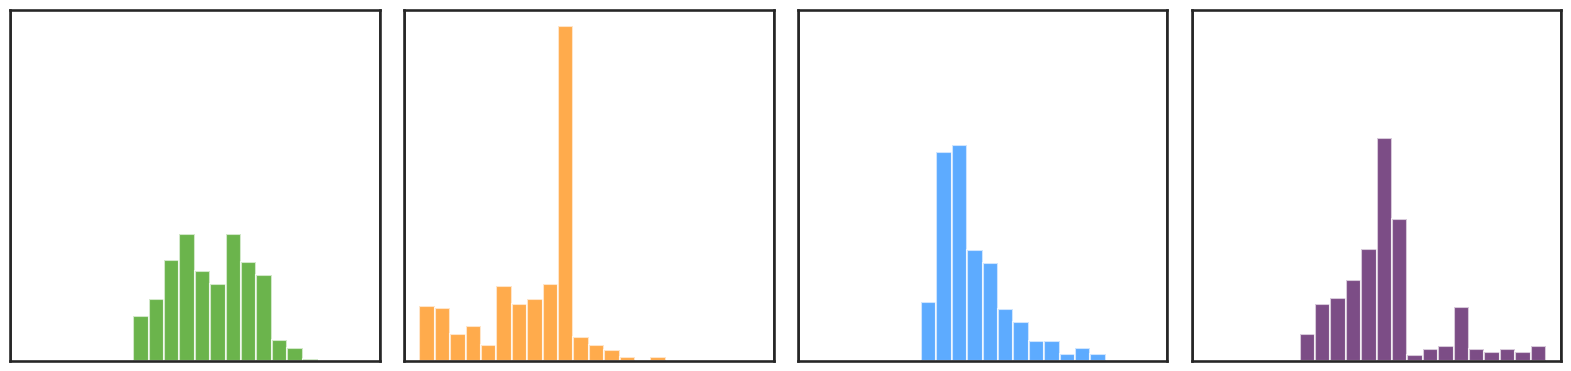

Saved figure → figure/code_8_delta_ucp_pc_2.png


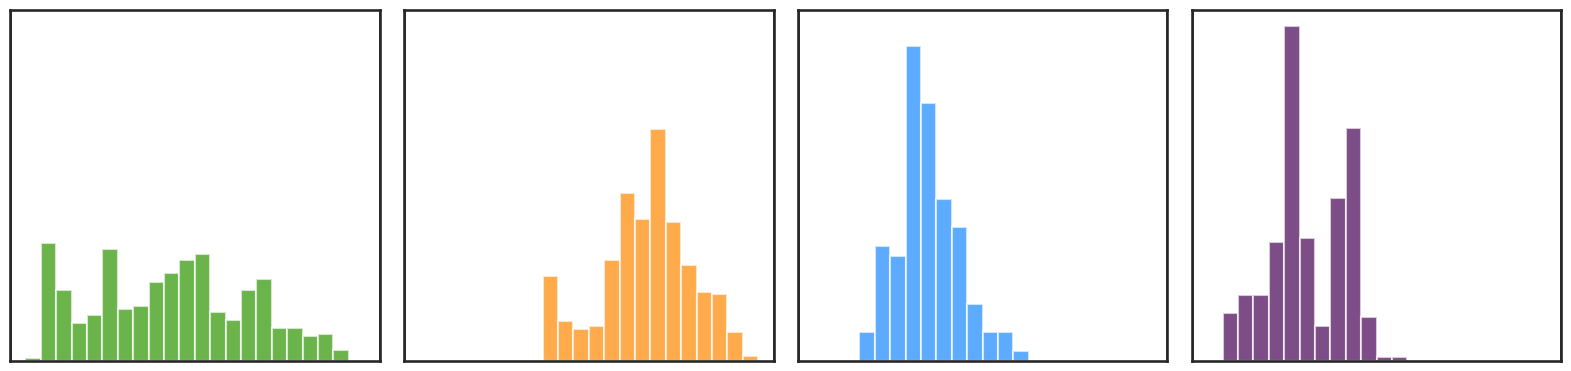

In [13]:
# Distribution plots for each policy in PC space (without baseline)
# Match PCA latent panel axis bounds (±0.5 padding on raw Z range)
x_min, x_max = Z[:, 0].min() - 0.5, Z[:, 0].max() + 0.5
y_min, y_max = Z[:, 1].min() - 0.5, Z[:, 1].max() + 0.5

# Bins span the same display range as scatter plots
pc1_bins = np.linspace(x_min, x_max, 25)
pc2_bins = np.linspace(y_min, y_max, 25)

# Determine consistent y-axis limits for density plots
policies = [2, 3, 4, 5]
policy_colours = ['#2C9500', '#FF8800', '#1988FF', '#440253']

# Calculate max density for PC1 across all policies
max_density_pc1 = 0
for p in policies:
    mask_policy = (best_policy == p)
    if mask_policy.sum() > 0:
        hist_vals, _ = np.histogram(Z[mask_policy, 0], bins=pc1_bins, density=True)
        max_density_pc1 = max(max_density_pc1, hist_vals.max())

# Calculate max density for PC2 across all policies
max_density_pc2 = 0
for p in policies:
    mask_policy = (best_policy == p)
    if mask_policy.sum() > 0:
        hist_vals, _ = np.histogram(Z[mask_policy, 1], bins=pc2_bins, density=True)
        max_density_pc2 = max(max_density_pc2, hist_vals.max())

# PC1 distributions with consistent bins and axis limits
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for idx, p in enumerate(policies):
    ax = axes[idx]
    
    # Get data for current policy only
    mask_policy = (best_policy == p)
    
    # PC1 distribution with consistent bins
    ax.hist(Z[mask_policy, 0], bins=pc1_bins, alpha=0.7, color=policy_colours[idx], 
           density=True, label=f'Policy {p}')
    
    # Set consistent axis limits
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(0, max_density_pc1 * 1.05)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel('')
    ax.set_ylabel('')
    
    # Add grid for better readability
    ax.grid(True, alpha=0.3)
    
    # Add left and right edge markers for each subplot
    ax.axvline(x=ax.get_xlim()[0], color='black', linewidth=2, alpha=0.8)
    ax.axvline(x=ax.get_xlim()[1], color='black', linewidth=2, alpha=0.8)

plt.tight_layout()
import os
os.makedirs('figure', exist_ok=True)
_pc1_fig_path = 'figure/code_8_delta_ucp_pc_1.png'
fig.savefig(_pc1_fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure → {_pc1_fig_path}")
plt.show()

# PC2 distributions with consistent bins and axis limits
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for idx, p in enumerate(policies):
    ax = axes[idx]
    
    # Get data for current policy only
    mask_policy = (best_policy == p)
    
    # PC2 distribution with consistent bins
    ax.hist(Z[mask_policy, 1], bins=pc2_bins, alpha=0.7, color=policy_colours[idx], 
           density=True, label=f'Policy {p}')
    
    # Set consistent axis limits
    ax.set_xlim(y_min, y_max)
    ax.set_ylim(0, max_density_pc2 * 1.05)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel('')
    ax.set_ylabel('')
    
    # Add grid for better readability
    ax.grid(True, alpha=0.3)
    
    # Add left and right edge markers for each subplot
    ax.axvline(x=ax.get_xlim()[0], color='black', linewidth=2, alpha=0.8)
    ax.axvline(x=ax.get_xlim()[1], color='black', linewidth=2, alpha=0.8)

plt.tight_layout()
_pc2_fig_path = 'figure/code_8_delta_ucp_pc_2.png'
fig.savefig(_pc2_fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure → {_pc2_fig_path}")
plt.show()

<a id="sec-5-7-kmeans"></a>

### 5.7 District classification (K-means)

Six district types from UCP contribution profiles.


Calculating administrative area potential ranking using K-means clustering (total + all contributions + shares)...
K selection composite ranking (n=53 areas):
Rank   k  Silhouette  Neighbor ARI  Size CV  Composite
   1   8       0.388         0.595    0.627      0.762
   2   9       0.360         0.589    0.419      0.754
   3  10       0.325         0.537    0.267      0.721
   4   7       0.353         0.536    0.488      0.719
   5   5       0.343         0.515    0.366      0.717
   6  14       0.360         0.513    0.511      0.716
   7   6       0.341         0.538    0.450      0.712
   8  11       0.348         0.565    0.618      0.712
   9   4       0.369         0.455    0.499      0.707
  10   3       0.342         0.406    0.187      0.706
  11  12       0.344         0.536    0.602      0.698
  12  15       0.348         0.512    0.636      0.691
  13  13       0.327         0.514    0.495      0.684
  14   2       0.279         0.227    0.208      0.574
Elbow k (max cho

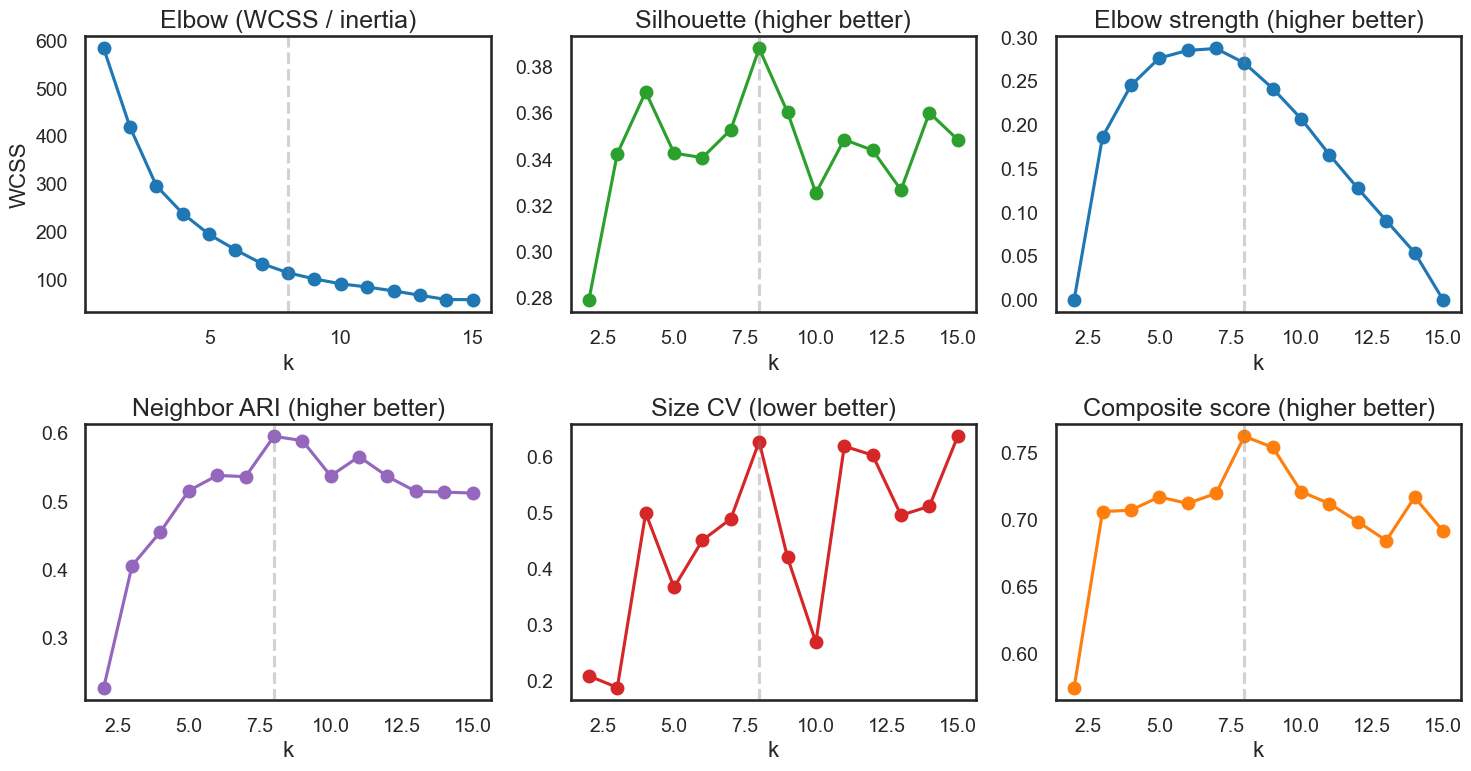

Using k=8 (rank 1 composite score)
Applying K-means clustering with 8 clusters...

K-means Clustering Results (k=8):
Features: ['total_contribution', 'base_contribution', 'UCP_2_contribution', 'UCP_3_contribution', 'UCP_4_contribution', 'UCP_5_contribution', 'base_share', 'UCP_2_share', 'UCP_3_share', 'UCP_4_share', 'UCP_5_share']
Cluster 1: High Potential, Low Base + High Policy      :   2 areas (  3.8%)
  Average total contribution: 0.9886
  Average mean_potential: 0.9886 (range 0.9359–1.0412)
  Average base share: 0.1660
  Average policy share (U2–U5): 0.8340

Cluster 2: High Potential, Low Base + High Policy      :   5 areas (  9.4%)
  Average total contribution: 0.9713
  Average mean_potential: 0.9713 (range 0.8782–1.0936)
  Average base share: 0.1888
  Average policy share (U2–U5): 0.8112

Cluster 3: High Potential, High Base + Low Policy      :  15 areas ( 28.3%)
  Average total contribution: 0.8575
  Average mean_potential: 0.8575 (range 0.5469–1.0649)
  Average base share: 0.8

In [19]:
# Calculate potential ranking for administrative areas using K-means clustering
if 'ucp_gdf' in locals() and 'admin_gdf' in locals():
    print("Calculating administrative area potential ranking using K-means clustering (total + all contributions + shares)...")
    
    # Check if required columns exist
    required_columns = ['UCP_1', 'Delta-UCP_2', 
                       'Delta-UCP_3', 'Delta-UCP_4', 
                       'Delta-UCP_5']
    
    missing_columns = [col for col in required_columns if col not in ucp_gdf.columns]
    if missing_columns:
        print(f"Missing columns: {missing_columns}")
    else:
        # Calculate potential value for each point
        ucp_gdf['potential_value'] = ucp_gdf['UCP_1'].copy()
        
        # Add positive values from optimization benefit differences
        for col in ['Delta-UCP_2', 'Delta-UCP_3', 
                   'Delta-UCP_4', 'Delta-UCP_5']:
            positive_values = ucp_gdf[col].where(ucp_gdf[col] > 0, 0)
            ucp_gdf['potential_value'] += positive_values
        
        # Aggregate potential values by administrative area
        admin_potential = []
        
        for idx, admin_row in admin_gdf.iterrows():
            # Use PLN_AREA_N instead of 'name' to match the file_context_0 pattern
            admin_name = admin_row['PLN_AREA_N']
            admin_geom = admin_row['geometry']
            
            # Find points within this administrative area
            points_in_admin = ucp_gdf[ucp_gdf.geometry.within(admin_geom)]
            
            if len(points_in_admin) > 0:
                # Calculate statistics for this administrative area (using mean values)
                mean_potential = points_in_admin['potential_value'].mean()
                min_potential = points_in_admin['potential_value'].min()
                max_potential = points_in_admin['potential_value'].max()
                point_count = len(points_in_admin)
                
                # Calculate average contribution from each component
                base_contribution = points_in_admin['UCP_1'].mean()
                UCP_2_contribution = points_in_admin['Delta-UCP_2'].where(
                    points_in_admin['Delta-UCP_2'] > 0, 0).mean()
                UCP_3_contribution = points_in_admin['Delta-UCP_3'].where(
                    points_in_admin['Delta-UCP_3'] > 0, 0).mean()
                UCP_4_contribution = points_in_admin['Delta-UCP_4'].where(
                    points_in_admin['Delta-UCP_4'] > 0, 0).mean()
                UCP_5_contribution = points_in_admin['Delta-UCP_5'].where(
                    points_in_admin['Delta-UCP_5'] > 0, 0).mean()
                
                admin_potential.append({
                    'admin_name': admin_name,
                    'mean_potential': mean_potential,
                    'min_potential': min_potential,
                    'max_potential': max_potential,
                    'point_count': point_count,
                    'base_contribution': base_contribution,
                    'UCP_2_contribution': UCP_2_contribution,
                    'UCP_3_contribution': UCP_3_contribution,
                    'UCP_4_contribution': UCP_4_contribution,
                    'UCP_5_contribution': UCP_5_contribution,
                    'geometry': admin_geom
                })
        
        # Convert to DataFrame and sort by mean potential first
        admin_potential_df = pd.DataFrame(admin_potential)
        admin_potential_df = admin_potential_df.sort_values('mean_potential', ascending=False)
        
        # Cluster features: total + all contributions + base/U2–U5 shares
        contribution_columns = ['base_contribution', 'UCP_2_contribution', 'UCP_3_contribution',
                                'UCP_4_contribution', 'UCP_5_contribution']
        share_columns = ['base_share', 'UCP_2_share', 'UCP_3_share', 'UCP_4_share', 'UCP_5_share']

        admin_potential_df['total_contribution'] = admin_potential_df[contribution_columns].sum(axis=1)
        _contrib_total = admin_potential_df['total_contribution']
        for _c_col, _s_col in zip(contribution_columns, share_columns):
            admin_potential_df[_s_col] = np.where(
                _contrib_total > 0,
                admin_potential_df[_c_col] / _contrib_total,
                0.0,
            )

        cluster_feature_columns = ['total_contribution'] + contribution_columns + share_columns

        from sklearn.preprocessing import StandardScaler
        from sklearn.cluster import KMeans
        from sklearn.metrics import silhouette_score

        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(
            admin_potential_df[cluster_feature_columns].values
        )
        
        # Elbow WCSS + composite k selection
        max_k = min(15, len(admin_potential_df))
        k_range = range(1, max_k + 1)
        inertias = []
        
        for k in k_range:
            kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
            kmeans.fit(X_scaled)
            inertias.append(kmeans.inertia_)
        
        silhouette_k = [k for k in k_range if k >= 2]
        silhouette_scores = []
        for k in silhouette_k:
            km = KMeans(n_clusters=k, random_state=42, n_init=10)
            labels = km.fit_predict(X_scaled)
            silhouette_scores.append(silhouette_score(X_scaled, labels))

        # Composite k selection (40% silhouette + 35% neighbour ARI + 25% size balance)
        from sklearn.metrics import adjusted_rand_score

        SENSITIVITY_K = [k for k in range(2, max(k_range) + 1)]
        _labels_by_k = {}
        _sens_rows = []
        for k in SENSITIVITY_K:
            _km = KMeans(n_clusters=k, random_state=42, n_init=10)
            _lab = _km.fit_predict(X_scaled)
            _labels_by_k[k] = _lab
            _sizes = np.bincount(_lab)
            _sens_rows.append({
                'k': k,
                'silhouette': silhouette_score(X_scaled, _lab),
                'size_cv': float(_sizes.std() / _sizes.mean()) if _sizes.mean() > 0 else np.nan,
            })

        def _neighbor_stability(k):
            others = [kk for kk in SENSITIVITY_K if kk != k]
            if not others:
                return np.nan
            return float(np.mean([
                adjusted_rand_score(_labels_by_k[k], _labels_by_k[kk]) for kk in others
            ]))

        for row in _sens_rows:
            row['neighbor_ari'] = _neighbor_stability(row['k'])

        _max_sil = max(r['silhouette'] for r in _sens_rows)
        for row in _sens_rows:
            _sil_n = row['silhouette'] / _max_sil if _max_sil > 0 else 0.0
            _bal_n = 1.0 / (1.0 + row['size_cv'])
            row['composite'] = 0.40 * _sil_n + 0.35 * row['neighbor_ari'] + 0.25 * _bal_n

        _sens_ranked = sorted(_sens_rows, key=lambda r: (-r['composite'], r['k']))
        for _i, row in enumerate(_sens_ranked, start=1):
            row['rank'] = _i
        SELECTED_K = _sens_ranked[0]['k']

        print(f"K selection composite ranking (n={len(admin_potential_df)} areas):")
        print(f"{'Rank':>4} {'k':>3} {'Silhouette':>11} {'Neighbor ARI':>13} {'Size CV':>8} {'Composite':>10}")
        for row in _sens_ranked:
            print(f"{row['rank']:>4} {row['k']:>3} {row['silhouette']:>11.3f} "
                  f"{row['neighbor_ari']:>13.3f} {row['size_cv']:>8.3f} {row['composite']:>10.3f}")

        # Elbow strength (code_0 style): perpendicular distance from inertia curve
        # to the chord joining endpoints. Diagnostic only — not in composite.
        _inertia_by_k = {k: inertias[i] for i, k in enumerate(k_range)}
        _ek = np.asarray(SENSITIVITY_K, dtype=float)
        _esse = np.asarray([_inertia_by_k[int(k)] for k in _ek], dtype=float)
        _kn = (_ek - _ek.min()) / (_ek.max() - _ek.min() + 1e-12)
        _sn = (_esse - _esse.min()) / (_esse.max() - _esse.min() + 1e-12)
        _p1, _p2 = np.array([_kn[0], _sn[0]]), np.array([_kn[-1], _sn[-1]])
        _line = (_p2 - _p1) / (np.linalg.norm(_p2 - _p1) + 1e-12)
        _elbow_strength = {}
        for _k_i, _x, _y in zip(SENSITIVITY_K, _kn, _sn):
            _v = np.array([_x, _y]) - _p1
            _elbow_strength[_k_i] = float(np.linalg.norm(_v - _v.dot(_line) * _line))
        for row in _sens_rows:
            row['elbow_strength'] = _elbow_strength[row['k']]
        elbow_k = max(_elbow_strength, key=_elbow_strength.get)
        print(f"Elbow k (max chord distance): {elbow_k}")

        # Plot metrics curves (code_0 style); composite formula unchanged
        _sens_by_k = sorted(_sens_rows, key=lambda r: r['k'])
        _ks = [r['k'] for r in _sens_by_k]
        big_font = {'fontsize': 18}
        label_font = {'fontsize': 16}
        tick_fontsize = 14

        fig_k, axes_k = plt.subplots(2, 3, figsize=(15, 8))

        axes_k[0, 0].plot(k_range, inertias, marker='o')
        axes_k[0, 0].set_title('Elbow (WCSS / inertia)', **big_font)
        axes_k[0, 0].set_xlabel('k', **label_font)
        axes_k[0, 0].set_ylabel('WCSS', **label_font)
        axes_k[0, 0].tick_params(labelsize=tick_fontsize)

        axes_k[0, 1].plot(_ks, [r['silhouette'] for r in _sens_by_k], marker='o', color='tab:green')
        axes_k[0, 1].set_title('Silhouette (higher better)', **big_font)
        axes_k[0, 1].set_xlabel('k', **label_font)
        axes_k[0, 1].tick_params(labelsize=tick_fontsize)

        axes_k[0, 2].plot(_ks, [r['elbow_strength'] for r in _sens_by_k], marker='o', color='tab:blue')
        axes_k[0, 2].set_title('Elbow strength (higher better)', **big_font)
        axes_k[0, 2].set_xlabel('k', **label_font)
        axes_k[0, 2].tick_params(labelsize=tick_fontsize)

        axes_k[1, 0].plot(_ks, [r['neighbor_ari'] for r in _sens_by_k], marker='o', color='tab:purple')
        axes_k[1, 0].set_title('Neighbor ARI (higher better)', **big_font)
        axes_k[1, 0].set_xlabel('k', **label_font)
        axes_k[1, 0].tick_params(labelsize=tick_fontsize)

        axes_k[1, 1].plot(_ks, [r['size_cv'] for r in _sens_by_k], marker='o', color='tab:red')
        axes_k[1, 1].set_title('Size CV (lower better)', **big_font)
        axes_k[1, 1].set_xlabel('k', **label_font)
        axes_k[1, 1].tick_params(labelsize=tick_fontsize)

        axes_k[1, 2].plot(_ks, [r['composite'] for r in _sens_by_k], marker='o', color='tab:orange')
        axes_k[1, 2].set_title('Composite score (higher better)', **big_font)
        axes_k[1, 2].set_xlabel('k', **label_font)
        axes_k[1, 2].tick_params(labelsize=tick_fontsize)

        for ax in axes_k.ravel():
            ax.axvline(SELECTED_K, linestyle='--', alpha=0.35, color='gray')

        plt.tight_layout()
        plt.savefig('kmeans_elbow_analysis.png', dpi=300, bbox_inches='tight')
        from pathlib import Path as _Path
        _Path('figure').mkdir(exist_ok=True)
        fig_k.savefig('figure/code_8_k_selection.png', dpi=300, bbox_inches='tight')
        plt.show()

        MANUAL_K = SELECTED_K
        print(f"Using k={MANUAL_K} (rank 1 composite score)")
        
        # Use the determined optimal number of clusters
        optimal_k = min(MANUAL_K, len(admin_potential_df))  # Ensure k doesn't exceed number of areas
        
        print(f"Applying K-means clustering with {optimal_k} clusters...")
        
        # Apply K-means clustering with optimal k
        kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
        cluster_labels = kmeans.fit_predict(X_scaled)
        
        # Add cluster labels to dataframe
        admin_potential_df['cluster'] = cluster_labels

        cluster_centers = scaler.inverse_transform(kmeans.cluster_centers_)

        cluster_info = {}
        for i in range(optimal_k):
            cluster_data = admin_potential_df[admin_potential_df['cluster'] == i]
            cluster_center = cluster_centers[i]
            avg_base_share = cluster_data['base_share'].mean()
            _policy_share_cols = ['UCP_2_share', 'UCP_3_share', 'UCP_4_share', 'UCP_5_share']
            avg_policy_share = cluster_data[_policy_share_cols].sum(axis=1).mean()
            avg_potential = cluster_data['mean_potential'].mean()
            _mean_pot_min = cluster_data['mean_potential'].min()
            _mean_pot_max = cluster_data['mean_potential'].max()
            _point_pot_min = cluster_data['min_potential'].min()
            _point_pot_max = cluster_data['max_potential'].max()
            pot_level = 'High' if avg_potential > admin_potential_df['mean_potential'].mean() else 'Low'
            base_level = 'High' if avg_base_share > admin_potential_df['base_share'].mean() else 'Low'
            _global_policy_share = admin_potential_df[_policy_share_cols].sum(axis=1).mean()
            policy_level = 'High' if avg_policy_share > _global_policy_share else 'Low'
            cluster_name = f"{pot_level} Potential, {base_level} Base + {policy_level} Policy"
            cluster_info[i] = {
                'name': cluster_name,
                'count': len(cluster_data),
                'avg_potential': avg_potential,
                'avg_total_contribution': cluster_data['total_contribution'].mean(),
                'pot_range_mean': (_mean_pot_min, _mean_pot_max),
                'pot_range_point': (_point_pot_min, _point_pot_max),
                'avg_base': avg_base_share,
                'avg_policy_sum': avg_policy_share,
                'center': cluster_center,
            }

        sorted_clusters = sorted(
            cluster_info.items(), key=lambda x: x[1]['avg_potential'], reverse=True
        )
        cluster_name_mapping = {}
        cluster_colors = {}
        color_palette = [
            '#8B0000', '#DC143C', '#FF6347', '#FF8C00', '#FFD700',
            '#32CD32', '#90EE90', '#E0E0E0', '#D3D3D3',
        ]
        for rank, (cluster_id, info) in enumerate(sorted_clusters):
            cluster_name_mapping[cluster_id] = f"Cluster {rank + 1}: {info['name']}"
            cluster_colors[cluster_id] = color_palette[rank % len(color_palette)]

        admin_potential_df['classification'] = admin_potential_df['cluster'].map(
            cluster_name_mapping
        )
        
        # Create separate ranking within each cluster (by mean potential value)
        cluster_rankings = {}
        for cluster_id in range(optimal_k):
            cluster_data = admin_potential_df[admin_potential_df['cluster'] == cluster_id].copy()
            cluster_data = cluster_data.sort_values('mean_potential', ascending=False)
            cluster_data['class_rank'] = range(1, len(cluster_data) + 1)
            cluster_rankings[cluster_id] = cluster_data
        
        # Combine all clusters back into one dataframe with class rankings
        admin_potential_ranked = pd.concat(cluster_rankings.values(), ignore_index=True)
        admin_potential_ranked = admin_potential_ranked.sort_values('mean_potential', ascending=False)
        admin_potential_ranked['overall_rank'] = range(1, len(admin_potential_ranked) + 1)
        
        # Create GeoDataFrame for visualization
        admin_potential_gdf = gpd.GeoDataFrame(admin_potential_ranked, geometry='geometry')
        
        print(f"\nK-means Clustering Results (k={optimal_k}):")
        print(f"Features: {cluster_feature_columns}")
        print("=" * 80)
        for rank, (cluster_id, info) in enumerate(sorted_clusters):
            cluster_name = cluster_name_mapping[cluster_id]
            percentage = (info['count'] / len(admin_potential_ranked)) * 100
            print(f"{cluster_name:<55}: {info['count']:>3} areas ({percentage:>5.1f}%)")
            print(f"  Average total contribution: {info['avg_total_contribution']:.4f}")
            print(f"  Average mean_potential: {info['avg_potential']:.4f} "
                  f"(range {info['pot_range_mean'][0]:.4f}–{info['pot_range_mean'][1]:.4f})")
            print(f"  Average base share: {info['avg_base']:.4f}")
            print(f"  Average policy share (U2–U5): {info['avg_policy_sum']:.4f}")
            print()
        
        print(f"\nUnified Administrative Area Ranking Table (K-means Clusters, k={optimal_k}, Ranked by Mean Potential within Cluster):")
        print("="*160)
        print(f"{'Overall':<8} {'Class':<6} {'Cluster Classification':<45} {'Admin Area':<25} {'Total Contrib':<15} {'Base Contrib':<15} {'Mean Pot':<10} {'Min Pot':<10} {'Max Pot':<10} {'Points':<8} {'U2':<8} {'U3':<8} {'U4':<8} {'U5':<8}")
        print(f"{'Rank':<8} {'Rank':<6} {'':<45} {'':<25} {'':<15} {'':<15} {'':<10} {'':<10} {'':<10} {'':<8} {'':<8} {'':<8} {'':<8} {'':<8}")
        print("="*160)
        
        # Sort by cluster priority (based on average mean potential) and then by class rank within each cluster
        cluster_priority = {cluster_id: rank for rank, (cluster_id, info) in enumerate(sorted_clusters)}
        admin_potential_ranked['cluster_priority'] = admin_potential_ranked['cluster'].map(cluster_priority)
        admin_potential_display = admin_potential_ranked.sort_values(['cluster_priority', 'class_rank'])
        
        current_cluster = None
        for idx, row in admin_potential_display.iterrows():
            # Add separator line when cluster changes
            if current_cluster != row['cluster']:
                if current_cluster is not None:
                    print("-" * 160)
                current_cluster = row['cluster']
            
            print(f"{row['overall_rank']:<8} {row['class_rank']:<6} {row['classification']:<45} {row['admin_name']:<25} "
                  f"{row['total_contribution']:<15.4f} {row['base_contribution']:<15.4f} {row['mean_potential']:<10.4f} {row['min_potential']:<10.4f} {row['max_potential']:<10.4f} {row['point_count']:<8} "
                  f"{row['UCP_2_contribution']:<8.4f} {row['UCP_3_contribution']:<8.4f} "
                  f"{row['UCP_4_contribution']:<8.4f} {row['UCP_5_contribution']:<8.4f}")

<a id="sec-5-8-viz"></a>

### 5.8 Classification maps and charts

District typing maps, stacked bars, and export to `figure/`.


Creating K-means cluster spatial distribution mapping...
Cluster colour mapping:
  Type 1: #1988FF (Average potential: 0.9886)
  Type 2: #2C9500 (Average potential: 0.9713)
  Type 3: #707070 (Average potential: 0.8575)
  Type 4: #FF8800 (Average potential: 0.6851)
  Type 5: #2EC4B6 (Average potential: 0.5946)
  Type 6: #C66BFF (Average potential: 0.3202)
  Type 7: #FFCC69 (Average potential: 0.2965)
  Type 8: #A6A6A6 (Average potential: 0.1632)
Creating mean potential 5-level classification mapping...
Mean potential level classification (quintiles of mean_potential):
  Level 1: (0.0073, 0.3468]
  Level 2: (0.3468, 0.5813]
  Level 3: (0.5813, 0.7831]
  Level 4: (0.7831, 0.9371]
  Level 5: (0.9371, 1.0936]


/var/folders/f4/33sk92_n60j6tssngt9ntw3m0000gn/T/ipykernel_47585/1735520842.py:88: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  viridis = cm.get_cmap('viridis')


Saved figure → figure/code_8_admin_classification_maps.png
Saved figure → figure/code_8_admin_classification_maps.svg


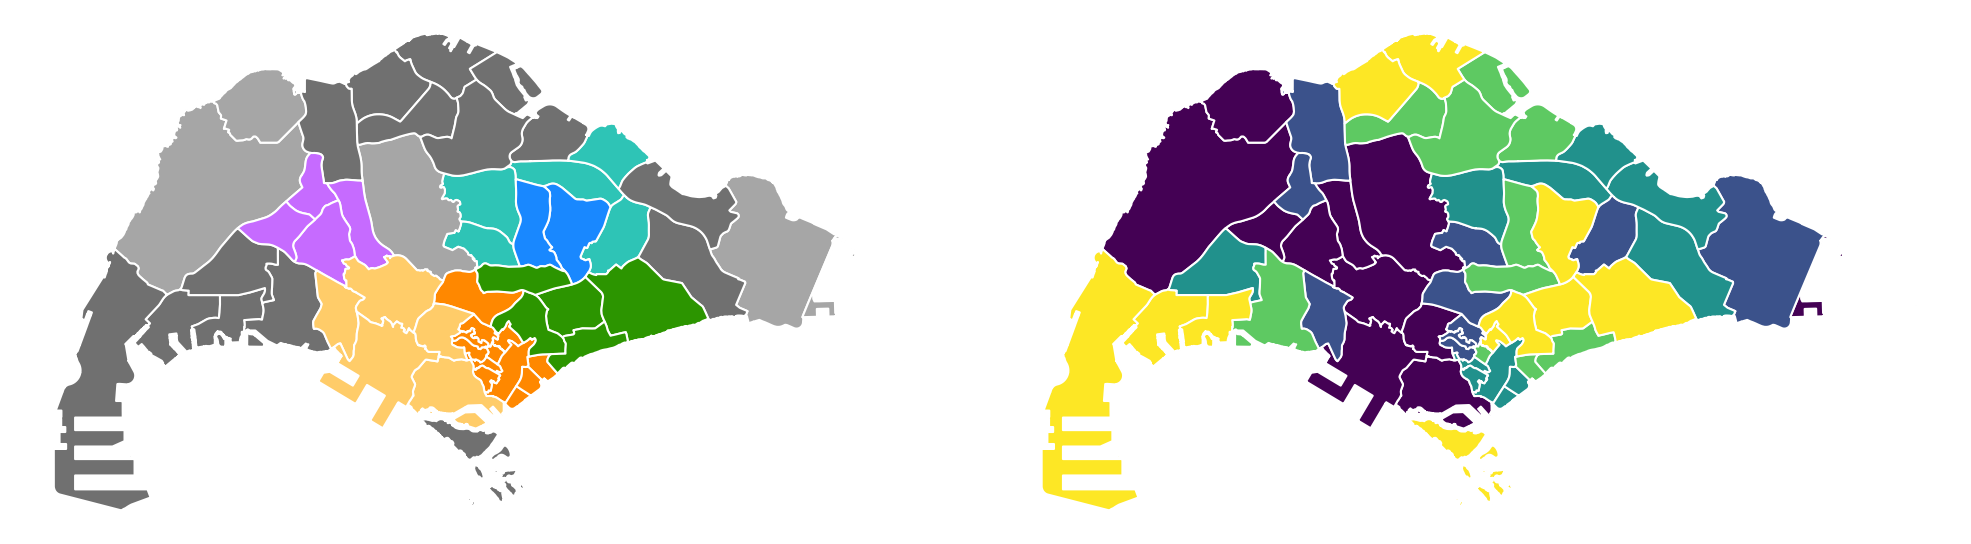

Creating cluster_and_level_distribution_pie_charts.png
Cluster distribution proportions:
  Type 1: 2 areas (3.8%)
  Type 2: 5 areas (9.4%)
  Type 3: 15 areas (28.3%)
  Type 4: 12 areas (22.6%)
  Type 5: 5 areas (9.4%)
  Type 6: 4 areas (7.5%)
  Type 7: 5 areas (9.4%)
  Type 8: 5 areas (9.4%)

Potential level distribution proportions:
  Level 1: 11 areas (20.8%)
  Level 2: 10 areas (18.9%)
  Level 3: 11 areas (20.8%)
  Level 4: 10 areas (18.9%)
  Level 5: 11 areas (20.8%)
Saved figure → figure/code_8_cluster_level_distribution_pies.png
Saved figure → figure/code_8_cluster_level_distribution_pies.svg


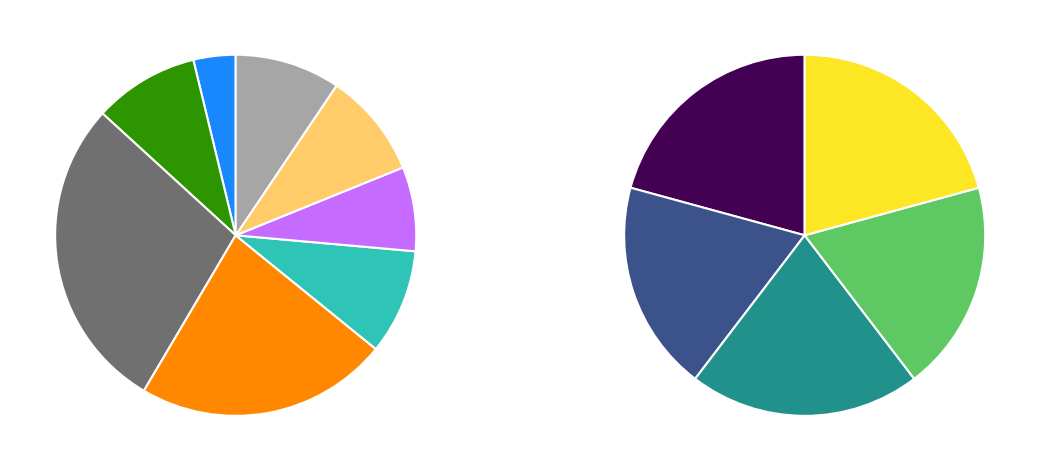

Creating stacked bar chart mapping for policy contributions...
Policy contribution colour mapping:
  Base contribution: Grey (baseline values)
  UCP_2 contribution: #29BB00 (Green - UCP_2 benefits)
  UCP_3 contribution: #FFBC37 (Orange - UCP_3 benefits)
  UCP_4 contribution: #35A7FF (Blue - UCP_4 benefits)
  UCP_5 contribution: #B339FF (Purple - UCP_5 benefits)
Y-axis range: 0-2 (total potential value)
Saved figure → figure/code_8_policy_contribution_stacked_bar.png
Saved figure → figure/code_8_policy_contribution_stacked_bar.svg


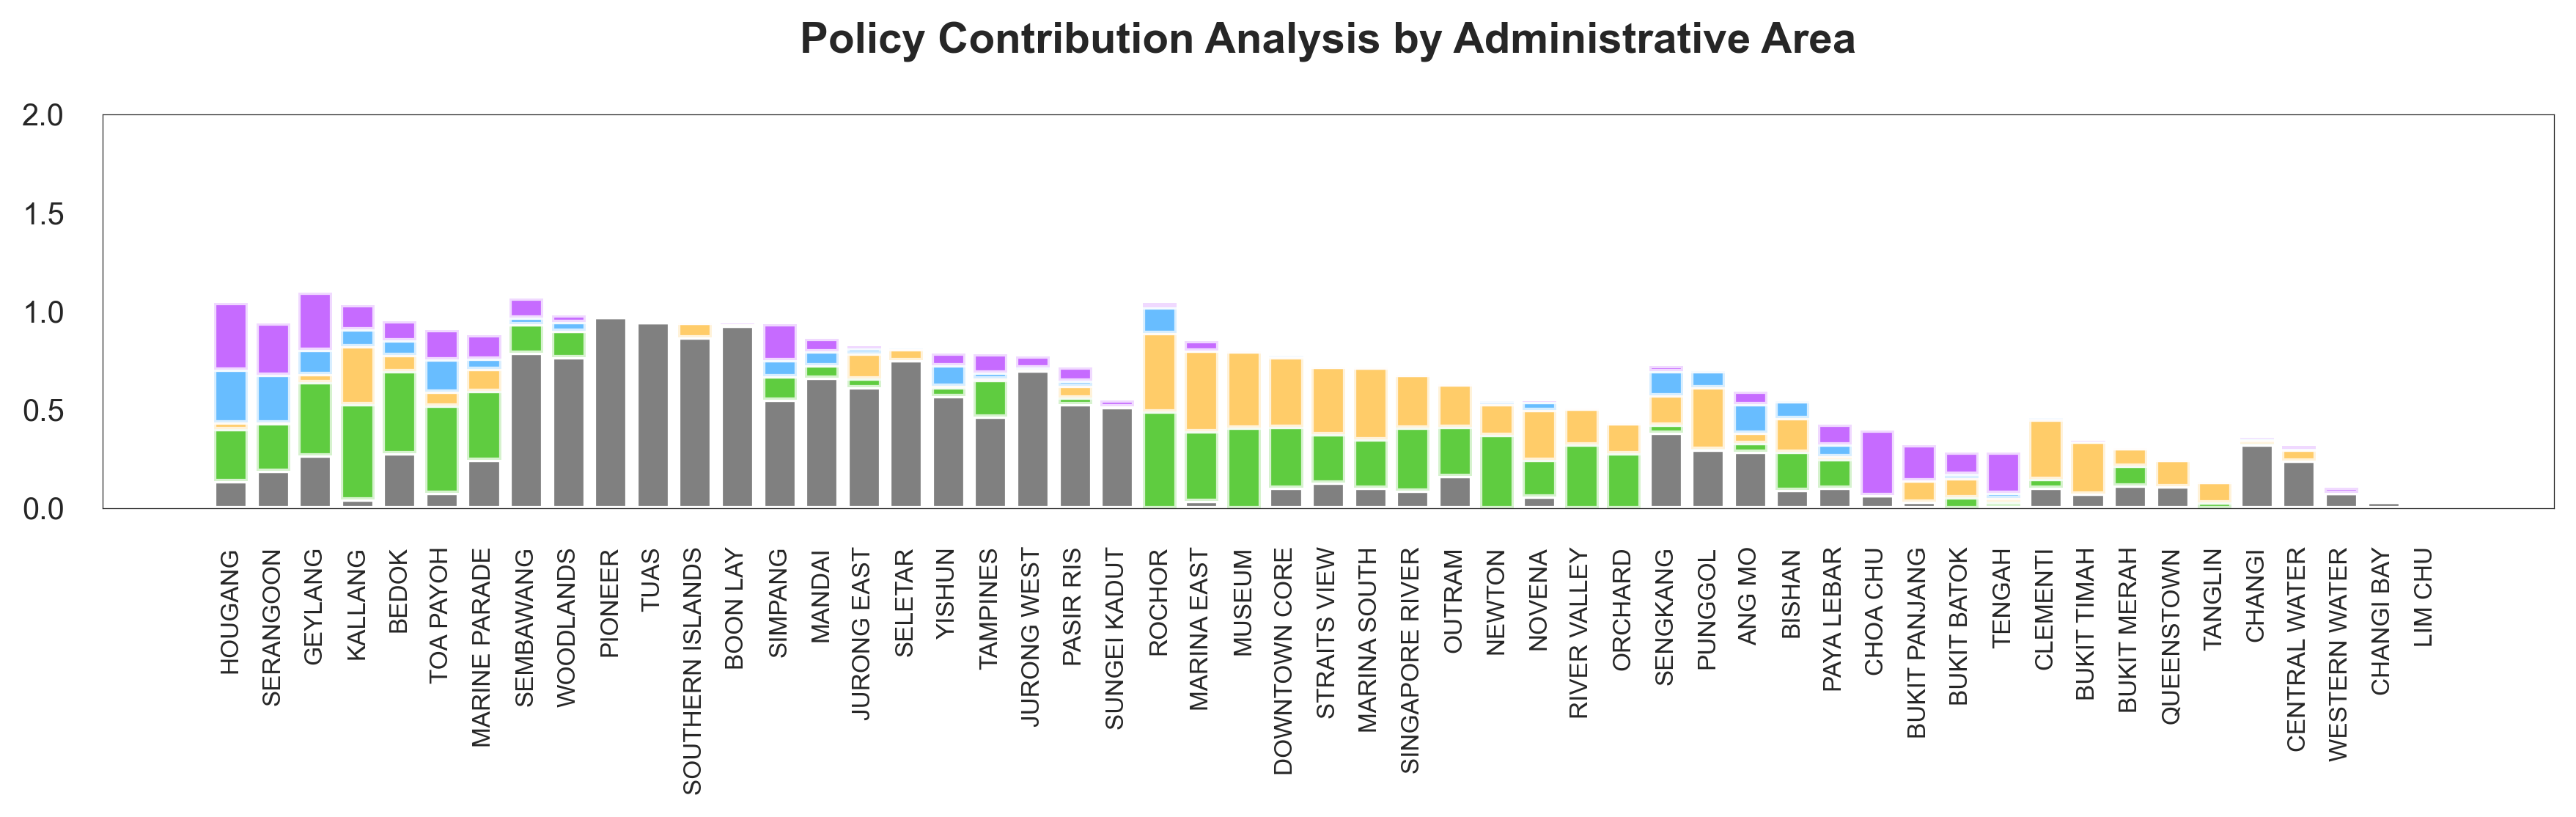

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Creating policy_composition_by_cluster_type_pie_charts.png
Type 1 policy composition proportions:
  Base contribution: 16.4%
  UCP_2 contribution: 25.7%
  UCP_3 contribution: 1.7%
  UCP_4 contribution: 25.9%
  UCP_5 contribution: 30.2%

Type 2 policy composition proportions:
  Base contribution: 18.8%
  UCP_2 contribution: 42.6%
  UCP_3 contribution: 12.3%
  UCP_4 contribution: 10.4%
  UCP_5 contribution: 16.0%

Type 3 policy composition proportions:
  Base contribution: 82.5%
  UCP_2 contribution: 6.0%
  UCP_3 contribution: 2.7%
  UCP_4 contribution: 3.4%
  UCP_5 contribution: 5.5%

Type 4 policy composition proportions:
  Base contribution: 8.3%
  UCP_2 contribution: 46.0%
  UCP_3 contribution: 42.4%
  UCP_4 contribution: 2.4%
  UCP_5 contribution: 0.9%

Type 5 policy composition proportions:
  Base contribution: 39.1%
  UCP_2 contribution: 14.3%
  UCP_3 contribution: 23.5%
  UCP_4 contribution: 16.8%
  UCP_5 contribution: 6.3%

Type 6 policy composition proportions:
  Base contribut

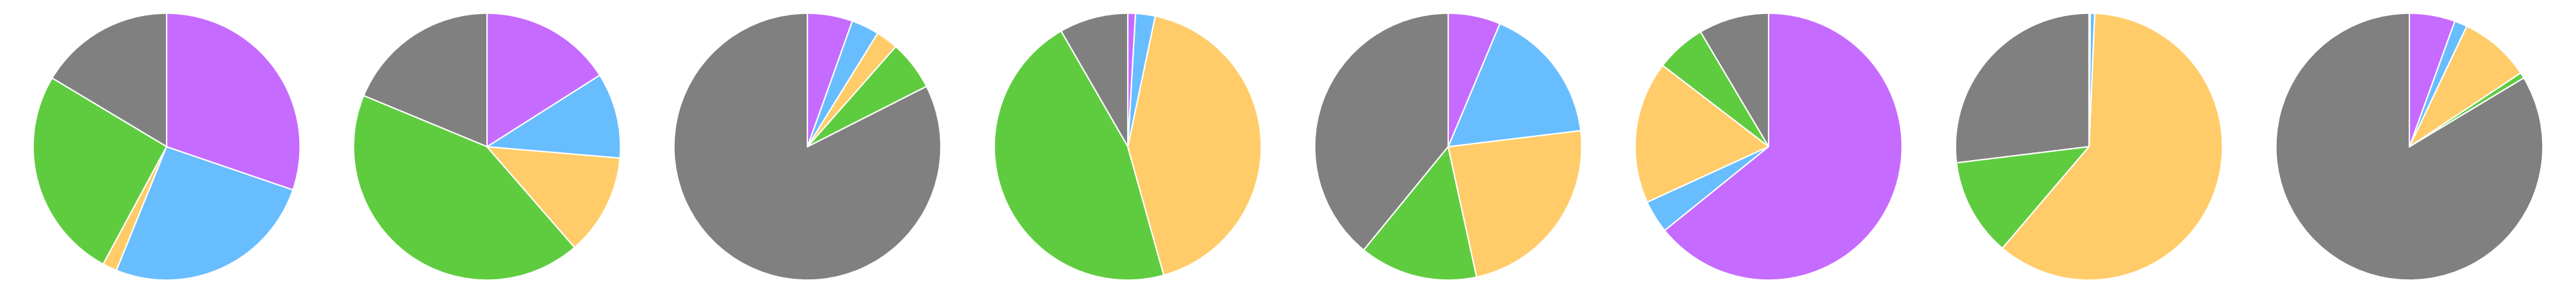

In [14]:
# Create visualisations
FIG_DIR = 'figure'


def _save_fig(fig, stem, dpi=300):
    import os
    os.makedirs(FIG_DIR, exist_ok=True)
    for ext in ('png', 'svg'):
        out = f"{FIG_DIR}/code_8_{stem}.{ext}"
        fig.savefig(out, dpi=dpi, bbox_inches='tight')
        print(f"Saved figure → {out}")

CLUSTER_TYPE_PALETTE = [
    '#1988FF',  # 0: Multi-policy responsive — coral, mixed type
    '#2C9500',  # 1: UCP_2-led — original green
    '#707070',  # 2: Established base-led — original dark grey
    '#FF8800',  # 3: UCP_3-led improvement — original gold 
    '#2EC4B6',  # 4: Balanced mixed-response — teal, mixed type
    '#C66BFF',  # 5: UCP_5-led — original purple
    '#FFCC69',  # 6: UCP_3-responsive — darker gold, same UCP_3 family
    '#A6A6A6',  # 7: Low-potential base-led — lighter grey
]
cluster_colour_mapping = {}
cluster_type_mapping = {}
cluster_type_colours = {}
for rank, (cluster_id, info) in enumerate(sorted_clusters):
    cluster_type_mapping[cluster_id] = rank + 1
    _colour = CLUSTER_TYPE_PALETTE[rank % len(CLUSTER_TYPE_PALETTE)]
    cluster_colour_mapping[cluster_id] = _colour
    cluster_type_colours[rank + 1] = _colour

admin_potential_gdf['cluster_type'] = admin_potential_gdf['cluster'].map(cluster_type_mapping)

print("Creating K-means cluster spatial distribution mapping...")
print("Cluster colour mapping:")
for rank, (cluster_id, info) in enumerate(sorted_clusters):
    cluster_name = f"Type {cluster_type_mapping[cluster_id]}"
    colour = cluster_colour_mapping.get(cluster_id, '#CCCCCC')
    print(f"  Type {cluster_type_mapping[cluster_id]}: {colour} (Average potential: {info['avg_potential']:.4f})")

# Figure 1: K-means clustering mapping
fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

# Plot cluster map with mapped colours
for cluster_id in range(optimal_k):
    cluster_data = admin_potential_gdf[admin_potential_gdf['cluster'] == cluster_id]
    if len(cluster_data) > 0:
        cluster_name = f"Type {cluster_type_mapping[cluster_id]}"
        cluster_data.plot(color=cluster_colour_mapping.get(cluster_id, '#CCCCCC'),
                            ax=ax1,
                            edgecolor='white',
                            linewidth=1.5
                            )

# Add legend for cluster map
# ax1.legend(loc='upper left', bbox_to_anchor=(0, 1), fontsize=10)

# Remove grid, spines, axes, and title for ax1
ax1.set_xticks([])
ax1.set_yticks([])
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['bottom'].set_visible(False)
ax1.spines['left'].set_visible(False)
# ax1.set_title('1. K-means Cluster Classification', fontsize=18, fontweight='bold')

print("Creating mean potential 5-level classification mapping...")
# Quintile bins on observed mean_potential (composite potential index scale)
_pot_vals = admin_potential_gdf['mean_potential'].to_numpy(dtype=float)
_quintile_cuts = np.quantile(_pot_vals, [0.0, 0.2, 0.4, 0.6, 0.8, 1.0])

def classify_potential(value):
    for lv in range(1, 5):
        if value <= _quintile_cuts[lv]:
            return lv
    return 5

admin_potential_gdf['potential_level'] = admin_potential_gdf['mean_potential'].apply(classify_potential)

print("Mean potential level classification (quintiles of mean_potential):")
for lv in range(1, 6):
    lo, hi = _quintile_cuts[lv - 1], _quintile_cuts[lv]
    print(f"  Level {lv}: ({lo:.4f}, {hi:.4f}]")

# Create discrete colourmap for 5 levels using viridis colours
from matplotlib.colors import ListedColormap
import matplotlib.cm as cm
viridis = cm.get_cmap('viridis')
level_colours = [viridis(i/4) for i in range(5)]  # Get 5 evenly spaced colours from viridis (0, 0.25, 0.5, 0.75, 1.0)
level_cmap = ListedColormap(level_colours)

# Plot each level separately to create legend
for level in range(1, 6):
    level_data = admin_potential_gdf[admin_potential_gdf['potential_level'] == level]
    if len(level_data) > 0:
        lo, hi = _quintile_cuts[level - 1], _quintile_cuts[level]
        level_data.plot(color=level_colours[level-1], 
                       ax=ax2,
                       edgecolor='white',
                       linewidth=1.5
                       )

# Add legend for potential level map
# ax2.legend(loc='upper left', bbox_to_anchor=(0, 1), fontsize=10)

# Remove grid, spines, axes, and title for ax2
ax2.set_xticks([])
ax2.set_yticks([])
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.spines['bottom'].set_visible(False)
ax2.spines['left'].set_visible(False)
# ax2.set_title('2. Mean Potential Level Classification', fontsize=18, fontweight='bold')

# Add main title for the entire figure
# fig1.suptitle('Administrative Area Classification Analysis', fontsize=20, fontweight='bold', y=0.95)

plt.tight_layout()
_save_fig(fig1, 'admin_classification_maps')
plt.show()

# Print image name and proportions
print("Creating cluster_and_level_distribution_pie_charts.png")
print("Cluster distribution proportions:")
# Print cluster proportions in Type 1-6 order (based on ranking)
for rank, (cluster_id, info) in enumerate(sorted_clusters):
    cluster_name = f"Type {cluster_type_mapping[cluster_id]}"
    count = info['count']
    percentage = (count / len(admin_potential_gdf)) * 100
    print(f"  {cluster_name}: {count} areas ({percentage:.1f}%)")

print("\nPotential level distribution proportions:")
level_counts = admin_potential_gdf['potential_level'].value_counts().sort_index()
for level_id, count in level_counts.items():
    percentage = (count / len(admin_potential_gdf)) * 100
    print(f"  Level {level_id}: {count} areas ({percentage:.1f}%)")

# Create two pie charts showing cluster and level distributions
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Pie chart 1: Cluster distribution
# Create ordered data based on cluster ranking (sorted_clusters order)
cluster_pie_data = []
cluster_pie_colours = []
cluster_pie_labels = []

for rank, (cluster_id, info) in enumerate(sorted_clusters):
    count = info['count']
    cluster_pie_data.append(count)
    cluster_pie_colours.append(cluster_colour_mapping.get(cluster_id, '#CCCCCC'))
    cluster_pie_labels.append(f"Type {cluster_type_mapping[cluster_id]}")

ax1.pie(cluster_pie_data, colors=cluster_pie_colours, startangle=90)
# ax1.pie(cluster_pie_data, colors=cluster_pie_colours, labels=cluster_pie_labels, startangle=90, autopct='%1.1f%%')
# ax1.set_title('1. Cluster Type Distribution', fontsize=12, fontweight='bold')

# Pie chart 2: Potential level distribution
level_pie_colours = [level_cmap(i-1) for i in level_counts.index]  # Use level colourmap (adjust for 0-based indexing)
level_pie_labels = [f'Level {i}' for i in level_counts.index]

ax2.pie(level_counts.values, colors=level_pie_colours, startangle=90)
# ax2.pie(level_counts.values, colors=level_pie_colours, labels=level_pie_labels, startangle=90, autopct='%1.1f%%')
# ax2.set_title('2. Potential Level Distribution', fontsize=12, fontweight='bold')

# Add main title for the pie charts
# fig.suptitle('Distribution Analysis of Administrative Areas', fontsize=14, fontweight='bold', y=0.95)

plt.tight_layout()
_save_fig(fig, 'cluster_level_distribution_pies')
plt.show()


print("Creating stacked bar chart mapping for policy contributions...")
print("Policy contribution colour mapping:")
print("  Base contribution: Grey (baseline values)")
print("  UCP_2 contribution: #29BB00 (Green - UCP_2 benefits)")
print("  UCP_3 contribution: #FFBC37 (Orange - UCP_3 benefits)")
print("  UCP_4 contribution: #35A7FF (Blue - UCP_4 benefits)")
print("  UCP_5 contribution: #B339FF (Purple - UCP_5 benefits)")
print("Y-axis range: 0-2 (total potential value)")

# Figure 2: Create stacked bar chart visualisation
plt.figure(figsize=(12, 4), dpi=300)

# Sort admin_potential_display by cluster and mean potential within each cluster
# First get cluster data sorted by mean potential (descending for high potential clusters)
cluster_data_sorted = []
for rank, (cluster_id, info) in enumerate(sorted_clusters):
    cluster_areas = admin_potential_ranked[admin_potential_ranked['cluster'] == cluster_id]
    cluster_areas_sorted = cluster_areas.sort_values('mean_potential', ascending=False)
    cluster_data_sorted.append(cluster_areas_sorted)

# Concatenate all sorted cluster dataframes
sorted_admin_potential = pd.concat(cluster_data_sorted)

policy_colours = ['grey', '#29BB00', '#FFBC37', '#35A7FF', '#B339FF']  # Base, UCP_2, UCP_3, UCP_4, UCP_5

# Plot the base_contribution at the bottom
bars = plt.bar(sorted_admin_potential['admin_name'], 
               sorted_admin_potential['base_contribution'],
               color=policy_colours[0], label='Base Contribution')

# Initialise bottom for stacking
bottom = sorted_admin_potential['base_contribution'].values.copy()

# Plot each policy contribution as a stacked bar with transparency
policy_columns = ['UCP_2_contribution', 'UCP_3_contribution', 'UCP_4_contribution', 'UCP_5_contribution']
policy_labels = ['UCP_2 Contribution', 'UCP_3 Contribution', 'UCP_4 Contribution', 'UCP_5 Contribution']

for i, col in enumerate(policy_columns):
    plt.bar(sorted_admin_potential['admin_name'], 
            sorted_admin_potential[col],
            bottom=bottom, color=policy_colours[i+1], 
            label=policy_labels[i], alpha=0.75)
    bottom += sorted_admin_potential[col]

# Add vertical lines to separate clusters
# current_pos = 0
# for rank, (cluster_id, info) in enumerate(sorted_clusters):
#     if rank > 0:  # Don't add line before first cluster
#         plt.axvline(x=current_pos - 0.5, color='black', linestyle='--', linewidth=0.5)
#     current_pos += info['count']

plt.xticks(rotation=90, fontsize=8)
plt.yticks(fontsize=10)
plt.ylim(0, 2)

plt.gca().spines['top'].set_linewidth(0.3)
plt.gca().spines['right'].set_linewidth(0.3)
plt.gca().spines['left'].set_linewidth(0.3)
plt.gca().spines['bottom'].set_linewidth(0.3)

# Add title for the stacked bar chart
plt.title('Policy Contribution Analysis by Administrative Area', fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
_save_fig(plt.gcf(), 'policy_contribution_stacked_bar')
plt.show()

# Create pie charts showing policy composition for each cluster type
print("Creating policy_composition_by_cluster_type_pie_charts.png")

# Calculate average policy contributions for each cluster type
cluster_policy_composition = {}
for rank, (cluster_id, info) in enumerate(sorted_clusters):
    cluster_name = f"Type {cluster_type_mapping[cluster_id]}"
    cluster_data = admin_potential_ranked[admin_potential_ranked['cluster'] == cluster_id]
    
    # Calculate average contributions for this cluster
    avg_base = cluster_data['base_contribution'].mean()
    avg_UCP_2 = cluster_data['UCP_2_contribution'].mean()
    avg_UCP_3 = cluster_data['UCP_3_contribution'].mean()
    avg_UCP_4 = cluster_data['UCP_4_contribution'].mean()
    avg_UCP_5 = cluster_data['UCP_5_contribution'].mean()
    
    total_avg = avg_base + avg_UCP_2 + avg_UCP_3 + avg_UCP_4 + avg_UCP_5
    
    # Calculate proportions
    cluster_policy_composition[cluster_name] = {
        'base': avg_base / total_avg * 100,
        'UCP_2': avg_UCP_2 / total_avg * 100,
        'UCP_3': avg_UCP_3 / total_avg * 100,
        'UCP_4': avg_UCP_4 / total_avg * 100,
        'UCP_5': avg_UCP_5 / total_avg * 100
    }
    
    print(f"{cluster_name} policy composition proportions:")
    print(f"  Base contribution: {avg_base / total_avg * 100:.1f}%")
    print(f"  UCP_2 contribution: {avg_UCP_2 / total_avg * 100:.1f}%")
    print(f"  UCP_3 contribution: {avg_UCP_3 / total_avg * 100:.1f}%")
    print(f"  UCP_4 contribution: {avg_UCP_4 / total_avg * 100:.1f}%")
    print(f"  UCP_5 contribution: {avg_UCP_5 / total_avg * 100:.1f}%")
    print()

# Policy composition pie charts — one panel per cluster type
_n_cluster_types = len(cluster_policy_composition)
fig, axes = plt.subplots(1, _n_cluster_types, figsize=(5 * _n_cluster_types, 5))
if _n_cluster_types == 1:
    axes = [axes]
else:
    axes = np.atleast_1d(axes)
plt.subplots_adjust(wspace=0, hspace=0)

# Convert colours to RGBA format with transparency for pie charts
import matplotlib.colors as mcolours


def hex_to_rgba(hex_colour, alpha=0.75):
    """Convert hex colour to RGBA with specified alpha"""
    rgb = mcolours.hex2color(hex_colour)
    return (*rgb, alpha)


# Create transparent policy colours for pie charts
policy_colours_transparent = [
    policy_colours[0],  # Keep grey solid for base contribution
    hex_to_rgba(policy_colours[1], 0.75),  # UCP_2 with transparency
    hex_to_rgba(policy_colours[2], 0.75),  # UCP_3 with transparency
    hex_to_rgba(policy_colours[3], 0.75),  # UCP_4 with transparency
    hex_to_rgba(policy_colours[4], 0.75)   # UCP_5 with transparency
]

# Create pie chart for each cluster type using consistent policy colours with transparency
for i, (cluster_name, composition) in enumerate(cluster_policy_composition.items()):
    values = [composition['base'], composition['UCP_2'], composition['UCP_3'], 
              composition['UCP_4'], composition['UCP_5']]
    # labels = ['Base', 'UCP_2', 'UCP_3', 'UCP_4', 'UCP_5']
    
    axes[i].pie(values, colors=policy_colours_transparent, startangle=90)
    # axes[i].pie(values, colors=policy_colours_transparent, labels=labels, startangle=90, autopct='%1.1f%%', textprops={'fontsize': 12})
    # axes[i].set_title(f'{i+1}. {cluster_name}', fontsize=16, fontweight='bold', pad=15)  # Add numbered subtitle
    axes[i].axis('equal')  # Ensure pie charts are circular
    
    # Remove axis margins to make pie charts touch
    axes[i].set_xlim(-1.2, 1.2)
    axes[i].set_ylim(-1.2, 1.2)

# Add main title for the policy composition pie charts
# fig.suptitle('Policy Composition Analysis by Cluster Type', fontsize=20, fontweight='bold', y=1.1)

# Remove padding around the entire figure
plt.subplots_adjust(left=0, right=1, top=0.88, bottom=0, wspace=0, hspace=0)
_save_fig(fig, 'policy_composition_by_cluster_type')
plt.show()


Found optimisation benefit difference columns: ['Delta-UCP_2', 'Delta-UCP_3', 'Delta-UCP_4', 'Delta-UCP_5']
Pairwise scatter ticks: ±0.40; display limits: ±0.46 (manual PAIRWISE_AXIS_LIMIT)

DELTA-UCP_2 vs DELTA-UCP_3 — n=53 | Pearson r=0.448 (p=0.000761), Spearman ρ=0.402 (p=0.00284)

DELTA-UCP_2 vs DELTA-UCP_4 — n=53 | Pearson r=0.273 (p=0.0482), Spearman ρ=0.353 (p=0.00956)

DELTA-UCP_2 vs DELTA-UCP_5 — n=53 | Pearson r=0.234 (p=0.0919), Spearman ρ=0.276 (p=0.0452)

DELTA-UCP_3 vs DELTA-UCP_4 — n=53 | Pearson r=-0.239 (p=0.0851), Spearman ρ=-0.268 (p=0.0528)

DELTA-UCP_3 vs DELTA-UCP_5 — n=53 | Pearson r=-0.417 (p=0.0019), Spearman ρ=-0.484 (p=0.000238)

DELTA-UCP_4 vs DELTA-UCP_5 — n=53 | Pearson r=0.660 (p=7.58e-08), Spearman ρ=0.622 (p=6.65e-07)
Saved figure → figure/code_8_delta_ucp_comparision.png


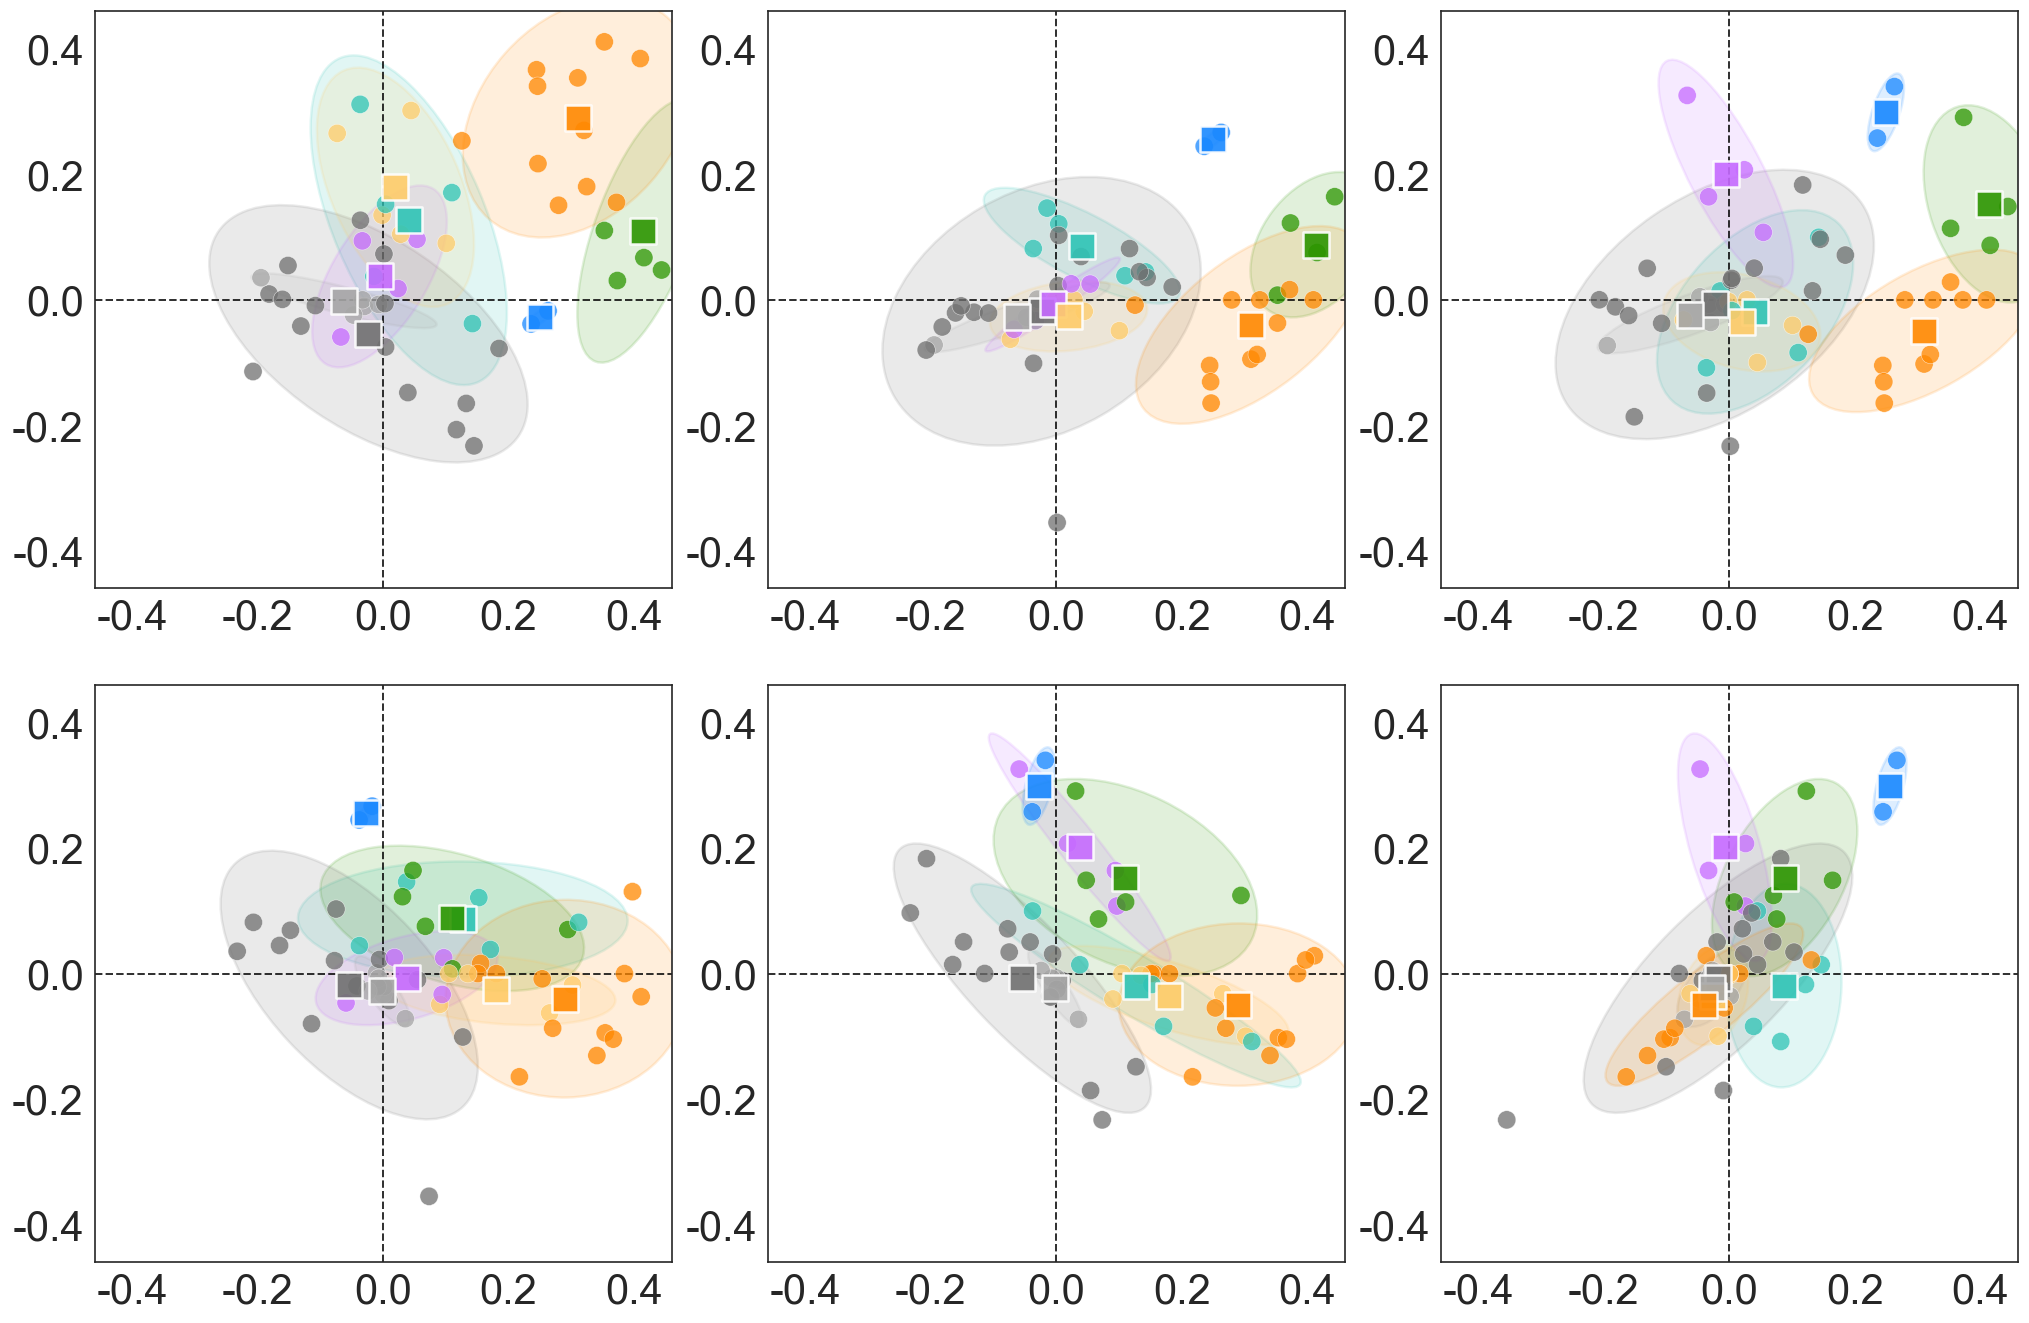

Creating polished correlation matrix across policies...


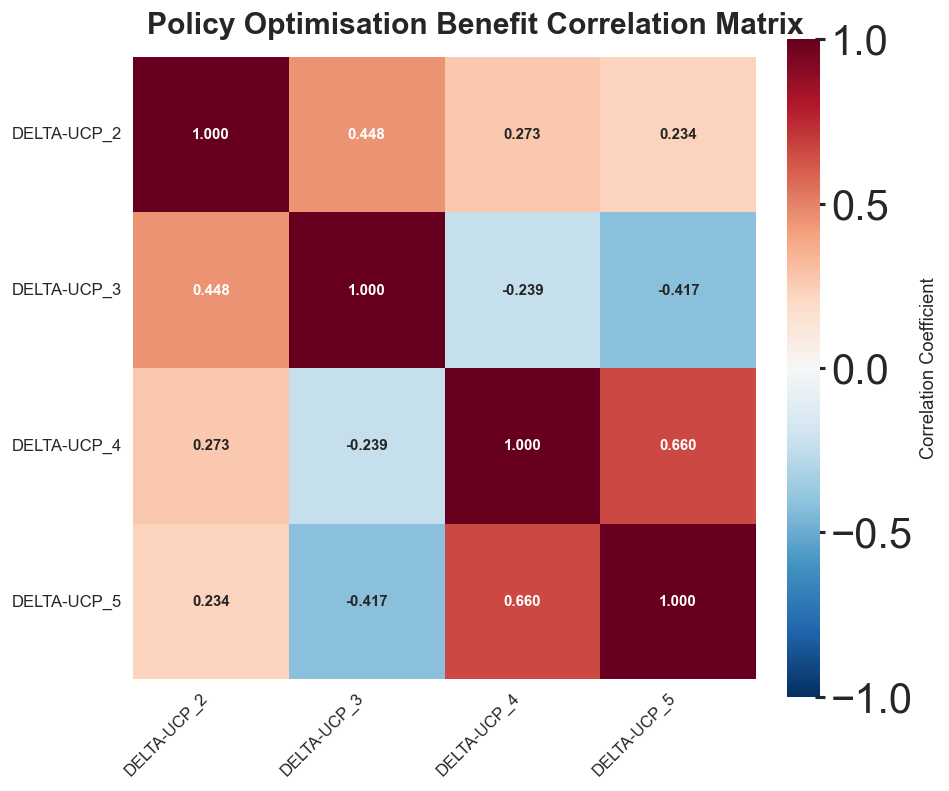

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from matplotlib.patches import Ellipse
from matplotlib.lines import Line2D

sns.set_theme(context="talk", style="white")
plt.rcParams.update({
    "figure.dpi": 120,                 # Canvas DPI (export DPI set in savefig)
    "savefig.dpi": 600,               # Export DPI for PNG
    "axes.spines.top": True,          # Show top spine
    "axes.spines.right": True,        # Show right spine
    "axes.spines.bottom": True,
    "axes.spines.left": True,
    "axes.linewidth": 1.0,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 25,
    "ytick.labelsize": 25,
    "xtick.major.size": 6,            # Show x-axis tick marks
    "xtick.minor.size": 3,            # Show minor x-axis tick marks
    "ytick.major.size": 6,            # Show y-axis tick marks
    "ytick.minor.size": 3,            # Show minor y-axis tick marks
    "xtick.direction": "inout",       # Tick direction
    "ytick.direction": "inout",       # Tick direction
    "legend.frameon": True,
    "legend.framealpha": 0.85,
    "legend.facecolor": "white",
    "pdf.fonttype": 42,               # Embed TrueType fonts in PDF
    "ps.fonttype": 42,
    "svg.fonttype": "none"            # Keep text as text in SVG
})

# Use widely available fonts, avoiding Liberation Sans
plt.rcParams["font.family"] = ["Arial", "DejaVu Sans", "Helvetica", "sans-serif"]

# Cluster type colours (from Cell 43 if run; else default 7-type palette)
if 'cluster_type_colours' not in globals():
    cluster_type_colours = {
        1: '#FFCC69', 2: '#68BDFF', 3: '#C66BFF', 4: '#5FCC40',
        5: '#FF6B6B', 6: '#2EC4B6', 7: '#707070',
    }

# -------------------------------------
# Safety checks for required data
# -------------------------------------
if 'ucp_gdf' in locals() or 'ucp_gdf' in globals():
    optimisation_benefit_diff_columns = [col for col in ucp_gdf.columns if col.startswith('Delta-UCP')]

    if optimisation_benefit_diff_columns and 'admin_gdf' in locals() and 'admin_potential_gdf' in locals():
        print(f"Found optimisation benefit difference columns: {optimisation_benefit_diff_columns}")

        # ----------------------------------------------------------------
        # Compute mean diffs by admin and collect area/cluster attributes
        # ----------------------------------------------------------------
        admin_diff_data = {}

        for diff_col in optimisation_benefit_diff_columns:
            policy_name = diff_col
            admin_diff_data[policy_name] = {}

            for idx, admin_area in admin_gdf.iterrows():
                within_mask = ucp_gdf.geometry.within(admin_area.geometry)
                points_in_area = ucp_gdf[within_mask]

                if len(points_in_area) > 0:
                    mean_diff = float(points_in_area[diff_col].mean())
                    admin_name = admin_area.get('PLN_AREA_N', f"Area_{idx}")

                    # Area (km²); geometry units are often m, so convert m² -> km²
                    area_size_raw = float(admin_area.geometry.area)
                    area_size_km2 = area_size_raw / 1_000_000.0

                    # Cluster type from potential table, if available
                    cluster_type = None
                    if 'admin_name' in admin_potential_gdf.columns and 'cluster_type' in admin_potential_gdf.columns:
                        match = admin_potential_gdf[admin_potential_gdf['admin_name'] == admin_name]
                        if len(match) > 0:
                            cluster_type = int(match['cluster_type'].iloc[0]) if pd.notnull(match['cluster_type'].iloc[0]) else None

                    admin_diff_data[policy_name][admin_name] = {
                        "mean_diff": mean_diff,
                        "area_km2": area_size_km2,
                        "point_count": int(len(points_in_area)),
                        "cluster_type": cluster_type
                    }

        # If no valid areas found
        if not any(len(v) for v in admin_diff_data.values()):
            print("No valid admin areas found with optimisation benefit differences.")
        else:
            # ------------------------------------------------------------
            # Helper: draw 95% confidence ellipse per cluster (>=2 pts) with Type marker at centre
            # ------------------------------------------------------------
            def draw_confidence_ellipse(x, y, ax, cluster_type, n_std=1.96, edgecolour="#222222", facecolour="#000000", alpha=0.12, lw=1.2, zorder=1):
                x = np.asarray(x, dtype=float)
                y = y[~np.isnan(y)]
                x = x[~np.isnan(x)]
                y = y[~np.isnan(y)]
                n = min(len(x), len(y))
                if n < 2:  # Changed from 3 to 2 to draw ellipse for 2 points
                    return
                x = x[:n]; y = y[:n]
                
                centre_x, centre_y = np.mean(x), np.mean(y)
                
                if n == 2:
                    # For exactly 2 points, create a simple ellipse along the line connecting them
                    dx, dy = x[1] - x[0], y[1] - y[0]
                    distance = np.sqrt(dx**2 + dy**2)
                    if distance == 0:
                        return
                    angle = np.degrees(np.arctan2(dy, dx))
                    width = distance * 1.5  # Make ellipse wider than the distance between points
                    height = distance * 0.5  # Make ellipse narrower in perpendicular direction
                    ellipse = Ellipse((centre_x, centre_y), width, height, angle=angle,
                                      edgecolor=edgecolour, facecolor=facecolour, alpha=alpha, lw=lw, zorder=zorder)
                    ax.add_patch(ellipse)
                else:
                    # For 3 or more points, use covariance-based ellipse
                    cov = np.cov(x, y)
                    if np.linalg.det(cov) <= 0:
                        return
                    vals, vecs = np.linalg.eigh(cov)
                    order = np.argsort(vals)[::-1]
                    vals, vecs = vals[order], vecs[:, order]
                    theta = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
                    width, height = 2 * n_std * np.sqrt(vals)
                    ellipse = Ellipse((centre_x, centre_y), width, height, angle=theta,
                                      edgecolor=edgecolour, facecolor=facecolour, alpha=alpha, lw=lw, zorder=zorder)
                    ax.add_patch(ellipse)
                
                # Add Type marker at ellipse centre (doubled size, no text)
                if cluster_type is not None:
                    ax.scatter(centre_x, centre_y, s=240, c=edgecolour, marker='s', 
                              edgecolors='white', linewidths=1.5, zorder=10, alpha=0.9)

            # ----------------------------------------
            # Pairwise scatter plots
            # ----------------------------------------
            policy_names = list(admin_diff_data.keys())
            n_policies = len(policy_names)
            n_comparisons = n_policies * (n_policies - 1) // 2

            if n_comparisons >= 1:
                # Layout
                if n_comparisons <= 3:
                    n_rows, n_cols = 1, n_comparisons
                elif n_comparisons <= 6:
                    n_rows, n_cols = 2, 3
                else:
                    n_cols = 3
                    n_rows = (n_comparisons + n_cols - 1) // n_cols

                fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.6*n_cols, 5.6*n_rows), constrained_layout=True)
                
                if n_comparisons == 1:
                    axes = [axes]
                else:
                    axes = np.array(axes).flatten()

                # --- Pairwise scatter axis limits (edit here) ---
                # Set PAIRWISE_AXIS_LIMIT to a number (e.g. 0.3) for fixed symmetric ±limit on every panel.
                # Set to None to auto: at least ±DELTA_CLIP, expanded if ellipse centres exceed it.
                PAIRWISE_AXIS_LIMIT = 0.4   # <-- change this
                DELTA_CLIP = 0.3            # minimum half-range when PAIRWISE_AXIS_LIMIT is None
                PAIRWISE_AXIS_PADDING = 1.03  # auto mode only: multiply extent before rounding
                PAIRWISE_AXIS_EDGE_PADDING = 0.06  # extra space on each side so tick labels don't overlap
                PAIRWISE_TICK_STEP = 0.2          # tick interval (e.g. 0.2 → -0.4, -0.2, 0, 0.2, 0.4)

                _all_xy = []
                for i in range(n_policies):
                    for j in range(i + 1, n_policies):
                        policy_x = policy_names[i]
                        policy_y = policy_names[j]
                        common_areas = set(admin_diff_data[policy_x].keys()) & set(admin_diff_data[policy_y].keys())
                        if not common_areas:
                            continue
                        x_vals, y_vals, cluster_types = [], [], []
                        for area_name in sorted(common_areas):
                            x_vals.append(admin_diff_data[policy_x][area_name]["mean_diff"])
                            y_vals.append(admin_diff_data[policy_y][area_name]["mean_diff"])
                            cluster_types.append(admin_diff_data[policy_x][area_name]["cluster_type"])
                        _all_xy.extend(x_vals)
                        _all_xy.extend(y_vals)
                        cluster_points = {}
                        for idx_ct, ct in enumerate(cluster_types):
                            if ct is None:
                                continue
                            cluster_points.setdefault(ct, {"x": [], "y": []})
                            cluster_points[ct]["x"].append(x_vals[idx_ct])
                            cluster_points[ct]["y"].append(y_vals[idx_ct])
                        for pts in cluster_points.values():
                            if len(pts["x"]) >= 2:
                                _all_xy.append(float(np.mean(pts["x"])))
                                _all_xy.append(float(np.mean(pts["y"])))

                if PAIRWISE_AXIS_LIMIT is not None:
                    _pairwise_plot_limit = float(PAIRWISE_AXIS_LIMIT)
                elif _all_xy:
                    data_extent = max(abs(np.min(_all_xy)), abs(np.max(_all_xy)))
                    _pairwise_plot_limit = max(DELTA_CLIP, data_extent) * PAIRWISE_AXIS_PADDING
                    _pairwise_plot_limit = float(np.ceil(_pairwise_plot_limit * 20) / 20)
                else:
                    _pairwise_plot_limit = DELTA_CLIP

                tick_positions = np.arange(
                    -_pairwise_plot_limit, _pairwise_plot_limit + PAIRWISE_TICK_STEP / 2, PAIRWISE_TICK_STEP
                )
                tick_positions = np.round(tick_positions, 1)
                _pairwise_display_limit = _pairwise_plot_limit + PAIRWISE_AXIS_EDGE_PADDING
                print(
                    f"Pairwise scatter ticks: ±{_pairwise_plot_limit:.2f}; "
                    f"display limits: ±{_pairwise_display_limit:.2f} "
                    f"({'manual PAIRWISE_AXIS_LIMIT' if PAIRWISE_AXIS_LIMIT is not None else 'auto from data + ellipse centres'})"
                )

                plot_idx = 0
                for i in range(n_policies):
                    for j in range(i + 1, n_policies):
                        policy_x = policy_names[i]
                        policy_y = policy_names[j]
                        ax = axes[plot_idx]

                        # Common admin areas
                        common_areas = set(admin_diff_data[policy_x].keys()) & set(admin_diff_data[policy_y].keys())
                        if not common_areas:
                            ax.set_visible(False)
                            plot_idx += 1
                            continue

                        x_values, y_values, area_names, cluster_types = [], [], [], []
                        for area_name in sorted(common_areas):
                            x_val = admin_diff_data[policy_x][area_name]["mean_diff"]
                            y_val = admin_diff_data[policy_y][area_name]["mean_diff"]
                            ctype = admin_diff_data[policy_x][area_name]["cluster_type"]

                            x_values.append(x_val)
                            y_values.append(y_val)
                            area_names.append(area_name)
                            cluster_types.append(ctype)

                        # Use uniform marker size for all points
                        uniform_size = 120

                        # Colours by cluster type using custom palette
                        colours = []
                        for ct in cluster_types:
                            if ct is not None and ct in cluster_type_colours:
                                colours.append(cluster_type_colours[ct])
                            else:
                                colours.append("#808080")  # Unknown -> grey

                        # Scatter
                        sc = ax.scatter(
                            x_values, y_values,
                            s=uniform_size, c=colours,
                            alpha=0.75, edgecolors="white", linewidths=0.3
                        )

                        # Draw 95% confidence ellipse per cluster (>=2 points) with Type marker
                        cluster_points = {}
                        for idx_ct, ct in enumerate(cluster_types):
                            if ct is None:
                                continue
                            cluster_points.setdefault(ct, {"x": [], "y": []})
                            cluster_points[ct]["x"].append(x_values[idx_ct])
                            cluster_points[ct]["y"].append(y_values[idx_ct])

                        for ct, pts in cluster_points.items():
                            col = cluster_type_colours.get(ct, "#808080")
                            draw_confidence_ellipse(
                                np.array(pts["x"]), np.array(pts["y"]), ax, ct,
                                n_std=1.96, edgecolour=col, facecolour=col, alpha=0.14, lw=1.5, zorder=0
                            )

                        # Same symmetric x/y limits for every subplot (display limit > tick range)
                        ax.set_xlim(-_pairwise_display_limit, _pairwise_display_limit)
                        ax.set_ylim(-_pairwise_display_limit, _pairwise_display_limit)
                        ax.set_aspect("equal", adjustable="box")

                        # Add cross lines at (0,0) in black dashed style
                        ax.axhline(y=0, color="black", linestyle="--", linewidth=1.2, alpha=0.8, zorder=0)
                        ax.axvline(x=0, color="black", linestyle="--", linewidth=1.2, alpha=0.8, zorder=0)

                        ax.set_xticks(tick_positions)
                        ax.set_yticks(tick_positions)
                        ax.set_xticklabels([f"{x:.1f}" for x in tick_positions])
                        ax.set_yticklabels([f"{y:.1f}" for y in tick_positions])

                        # Explicitly enable tick marks
                        ax.tick_params(axis='both', which='major', length=6, width=1, direction='inout')
                        ax.tick_params(axis='both', which='minor', length=3, width=0.5, direction='inout')
                        
                        # Ensure all spines are visible
                        for spine in ax.spines.values():
                            spine.set_visible(True)
                            spine.set_linewidth(1.0)

                        # Statistics: Pearson and Spearman with p-values
                        try:
                            r, rp = pearsonr(x_values, y_values)
                        except Exception:
                            r, rp = (np.nan, np.nan)
                        try:
                            rho, rhop = spearmanr(x_values, y_values)
                        except Exception:
                            rho, rhop = (np.nan, np.nan)

                        # Console summary
                        print(f"\n{policy_x.upper()} vs {policy_y.upper()} — n={len(common_areas)} | Pearson r={r:.3f} (p={rp:.3g}), Spearman ρ={rho:.3f} (p={rhop:.3g})")

                        plot_idx += 1

                # Hide any unused axes
                for k in range(plot_idx, len(axes)):
                    axes[k].set_visible(False)

                import os
                os.makedirs('figure', exist_ok=True)
                _comparison_fig_path = 'figure/code_8_delta_ucp_comparision.png'
                fig.savefig(_comparison_fig_path, dpi=300, bbox_inches='tight')
                print(f"Saved figure → {_comparison_fig_path}")

                plt.show()

            else:
                print("Need at least 2 policies for pairwise comparisons.")

            # ----------------------------------------
            # Correlation matrix (polished)
            # ----------------------------------------
            if len(policy_names) > 2:
                print("Creating polished correlation matrix across policies...")
                all_common_areas = set(admin_diff_data[policy_names[0]].keys())
                for policy in policy_names[1:]:
                    all_common_areas &= set(admin_diff_data[policy].keys())

                if all_common_areas:
                    corr_df = pd.DataFrame({
                        policy: [admin_diff_data[policy][area]["mean_diff"] for area in sorted(all_common_areas)]
                        for policy in policy_names
                    })
                    corr = corr_df.corr(method="pearson")

                    plt.figure(figsize=(7.8, 6.4), constrained_layout=True)
                    
                    # Add main title for correlation matrix - moved higher
                    plt.suptitle('Policy Optimisation Benefit Correlation Matrix', 
                               fontsize=18, fontweight='bold', y=1.01)
                    
                    ax = sns.heatmap(
                        corr, vmin=-1, vmax=1, cmap="RdBu_r",
                        annot=True, fmt=".3f", annot_kws={"size": 9, "weight": "bold"},
                        square=True, cbar_kws={"label": "Correlation Coefficient"}
                    )
                    ax.set_xticklabels([p.upper() for p in policy_names], rotation=45, ha="right", fontsize=10)
                    ax.set_yticklabels([p.upper() for p in policy_names], rotation=0, va="center", fontsize=10)
 
                    plt.show()
                else:
                    print("No common areas across all policies for correlation matrix.")
    else:
        print("Error: Required data not found.")
        if not optimisation_benefit_diff_columns:
            print("  - No optimisation benefit difference columns found")
        if 'admin_gdf' not in locals():
            print("  - Administrative boundaries data (admin_gdf) not found")
        if 'admin_potential_gdf' not in locals():
            print("  - Administrative potential data (admin_potential_gdf) not found")
else:
    print("Error: ucp_gdf not found in the current environment.")

<a id="sec-5-9-profile"></a>

### 5.9 Admin policy profile

Cluster × signed mean ΔUCP heatmap and admin-level PCA (supplement to pairwise scatter).


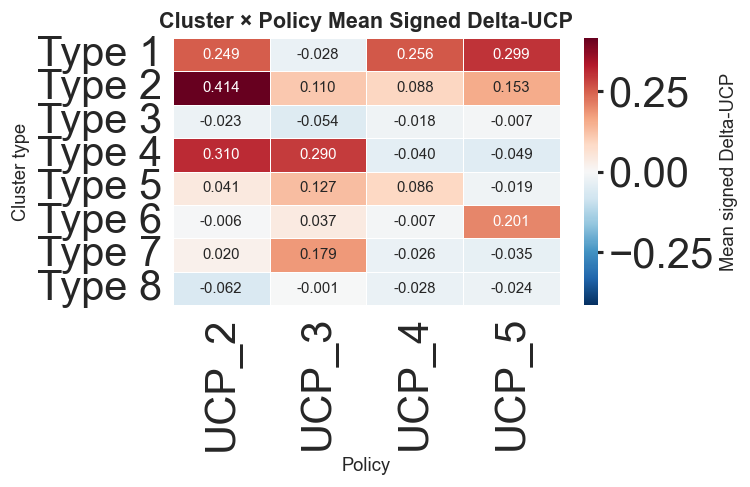

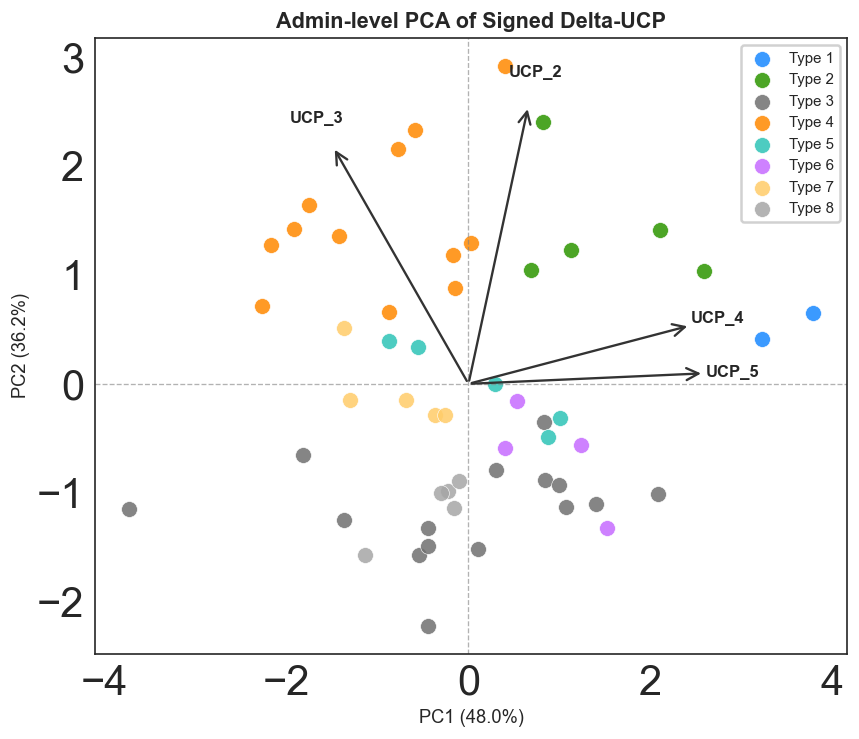

Admin areas plotted: 53
PCA variance explained: PC1=48.0%, PC2=36.2%


In [16]:
# Cluster × policy heatmap + admin-level PCA (compare with pairwise scatter block above)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

_delta_cols = [c for c in ucp_gdf.columns if c.startswith('Delta-UCP_')] if 'ucp_gdf' in globals() else []

if (
    _delta_cols
    and 'admin_gdf' in globals()
    and 'admin_potential_gdf' in globals()
    and 'cluster_type' in admin_potential_gdf.columns
):
    _policy_labels = [c.replace('Delta-UCP_', 'UCP_') for c in sorted(_delta_cols)]

    # Admin-level signed mean deltas
    _admin_delta_rows = []
    for _, _ar in admin_gdf.iterrows():
        _name = _ar.get('PLN_AREA_N', None)
        if _name is None:
            continue
        _pts = ucp_gdf[ucp_gdf.geometry.within(_ar.geometry)]
        if len(_pts) == 0:
            continue
        _row = {'admin_name': _name}
        for _dc in sorted(_delta_cols):
            _row[_dc] = float(_pts[_dc].mean())
        _admin_delta_rows.append(_row)

    _admin_delta_df = pd.DataFrame(_admin_delta_rows)
    _admin_delta_df = _admin_delta_df.merge(
        admin_potential_gdf[['admin_name', 'cluster_type']],
        on='admin_name',
        how='inner',
    )

    if len(_admin_delta_df) == 0:
        print('No admin areas with delta data and cluster labels.')
    else:
        _ctype_colours = cluster_type_colours if 'cluster_type_colours' in globals() else {
            1: '#FFCC69', 2: '#68BDFF', 3: '#C66BFF', 4: '#5FCC40',
            5: '#FF6B6B', 6: '#2EC4B6', 7: '#707070',
        }

        # ── Fig 1: cluster × policy signed mean Delta heatmap ─────────────────
        _hm = (
            _admin_delta_df.groupby('cluster_type')[sorted(_delta_cols)]
            .mean()
            .sort_index()
        )
        _hm.columns = [c.replace('Delta-UCP_', 'UCP_') for c in _hm.columns]
        _hm.index = [f'Type {int(i)}' for i in _hm.index]

        _vmax = max(abs(_hm.values.min()), abs(_hm.values.max()), 0.05)
        fig_hm, ax_hm = plt.subplots(figsize=(6.5, max(3.5, 0.55 * len(_hm))))
        sns.heatmap(
            _hm,
            ax=ax_hm,
            cmap='RdBu_r',
            center=0.0,
            vmin=-_vmax,
            vmax=_vmax,
            annot=True,
            fmt='.3f',
            annot_kws={'size': 9},
            linewidths=0.5,
            linecolor='white',
            cbar_kws={'label': 'Mean signed Delta-UCP'},
        )
        ax_hm.set_xlabel('Policy', fontsize=11)
        ax_hm.set_ylabel('Cluster type', fontsize=11)
        ax_hm.set_title('Cluster × Policy Mean Signed Delta-UCP', fontsize=13, fontweight='bold')
        plt.tight_layout()
        plt.show()

        # ── Fig 2: admin-level PCA of 4 signed deltas ─────────────────────────
        _X_raw = _admin_delta_df[sorted(_delta_cols)].to_numpy(dtype=float)
        _sc = StandardScaler()
        _X_z = _sc.fit_transform(_X_raw)
        _pca = PCA(n_components=2, random_state=42)
        _Z = _pca.fit_transform(_X_z)

        fig_pca, ax_pca = plt.subplots(figsize=(7.5, 6.5))
        for _ct in sorted(_admin_delta_df['cluster_type'].dropna().unique()):
            _mask = _admin_delta_df['cluster_type'] == _ct
            ax_pca.scatter(
                _Z[_mask, 0], _Z[_mask, 1],
                s=90, alpha=0.85,
                c=_ctype_colours.get(int(_ct), '#808080'),
                edgecolors='white', linewidths=0.4,
                label=f'Type {int(_ct)}',
            )

        _load = _pca.components_.T * np.sqrt(_pca.explained_variance_)
        _arrow_scale = 2.8
        for _i, _pl in enumerate(_policy_labels):
            ax_pca.annotate(
                '',
                xy=(_load[_i, 0] * _arrow_scale, _load[_i, 1] * _arrow_scale),
                xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color='#333333', lw=1.4),
            )
            ax_pca.text(
                _load[_i, 0] * _arrow_scale * 1.12,
                _load[_i, 1] * _arrow_scale * 1.12,
                _pl, fontsize=10, fontweight='bold', ha='center', va='center',
            )

        ax_pca.axhline(0, color='grey', ls='--', lw=0.8, alpha=0.6)
        ax_pca.axvline(0, color='grey', ls='--', lw=0.8, alpha=0.6)
        ax_pca.set_xlabel(f'PC1 ({_pca.explained_variance_ratio_[0]:.1%})', fontsize=11)
        ax_pca.set_ylabel(f'PC2 ({_pca.explained_variance_ratio_[1]:.1%})', fontsize=11)
        ax_pca.set_title('Admin-level PCA of Signed Delta-UCP', fontsize=13, fontweight='bold')
        ax_pca.legend(loc='best', fontsize=9, framealpha=0.9)
        plt.tight_layout()
        plt.show()

        print(f"Admin areas plotted: {len(_admin_delta_df)}")
        print(f"PCA variance explained: PC1={_pca.explained_variance_ratio_[0]:.1%}, "
              f"PC2={_pca.explained_variance_ratio_[1]:.1%}")
else:
    print('Skip comparison block: need ucp_gdf Delta columns, admin_gdf, admin_potential_gdf with cluster_type.')

<a id="sec-5-10-type"></a>

### 5.10 Representative type maps

Dominant-policy grid squares for top-contributing admin areas per cluster type.


Creating representative Type dominant-policy maps...
Panels: 16 (8 type(s) × 2 area(s); expected up to 16)
Dominant policy colours: {1: 'UCP_1', 2: 'UCP_2', 3: 'UCP_3', 4: 'UCP_4', 5: 'UCP_5'} (argmax UCP_1 vs Δ-UCP_2…5; shade ∝ winner within panel)
  Panel 1: Type 1 — HOUGANG (total_contrib=1.0412, n=44); dominant share: {'UCP_1': '4.5%', 'UCP_2': '13.6%', 'UCP_3': '2.3%', 'UCP_4': '6.8%', 'UCP_5': '72.7%'}
  Panel 2: Type 1 — SERANGOON (total_contrib=0.9359, n=35); dominant share: {'UCP_1': '37.1%', 'UCP_2': '37.1%', 'UCP_5': '25.7%'}
  Panel 3: Type 2 — GEYLANG (total_contrib=1.0936, n=31); dominant share: {'UCP_2': '100.0%'}
  Panel 4: Type 2 — KALLANG (total_contrib=1.0322, n=26); dominant share: {'UCP_2': '100.0%'}
  Panel 5: Type 3 — SEMBAWANG (total_contrib=1.0649, n=38); dominant share: {'UCP_1': '100.0%'}
  Panel 6: Type 3 — WOODLANDS (total_contrib=0.9796, n=46); dominant share: {'UCP_1': '100.0%'}
  Panel 7: Type 4 — ROCHOR (total_contrib=1.0415, n=6); dominant share: {'UCP

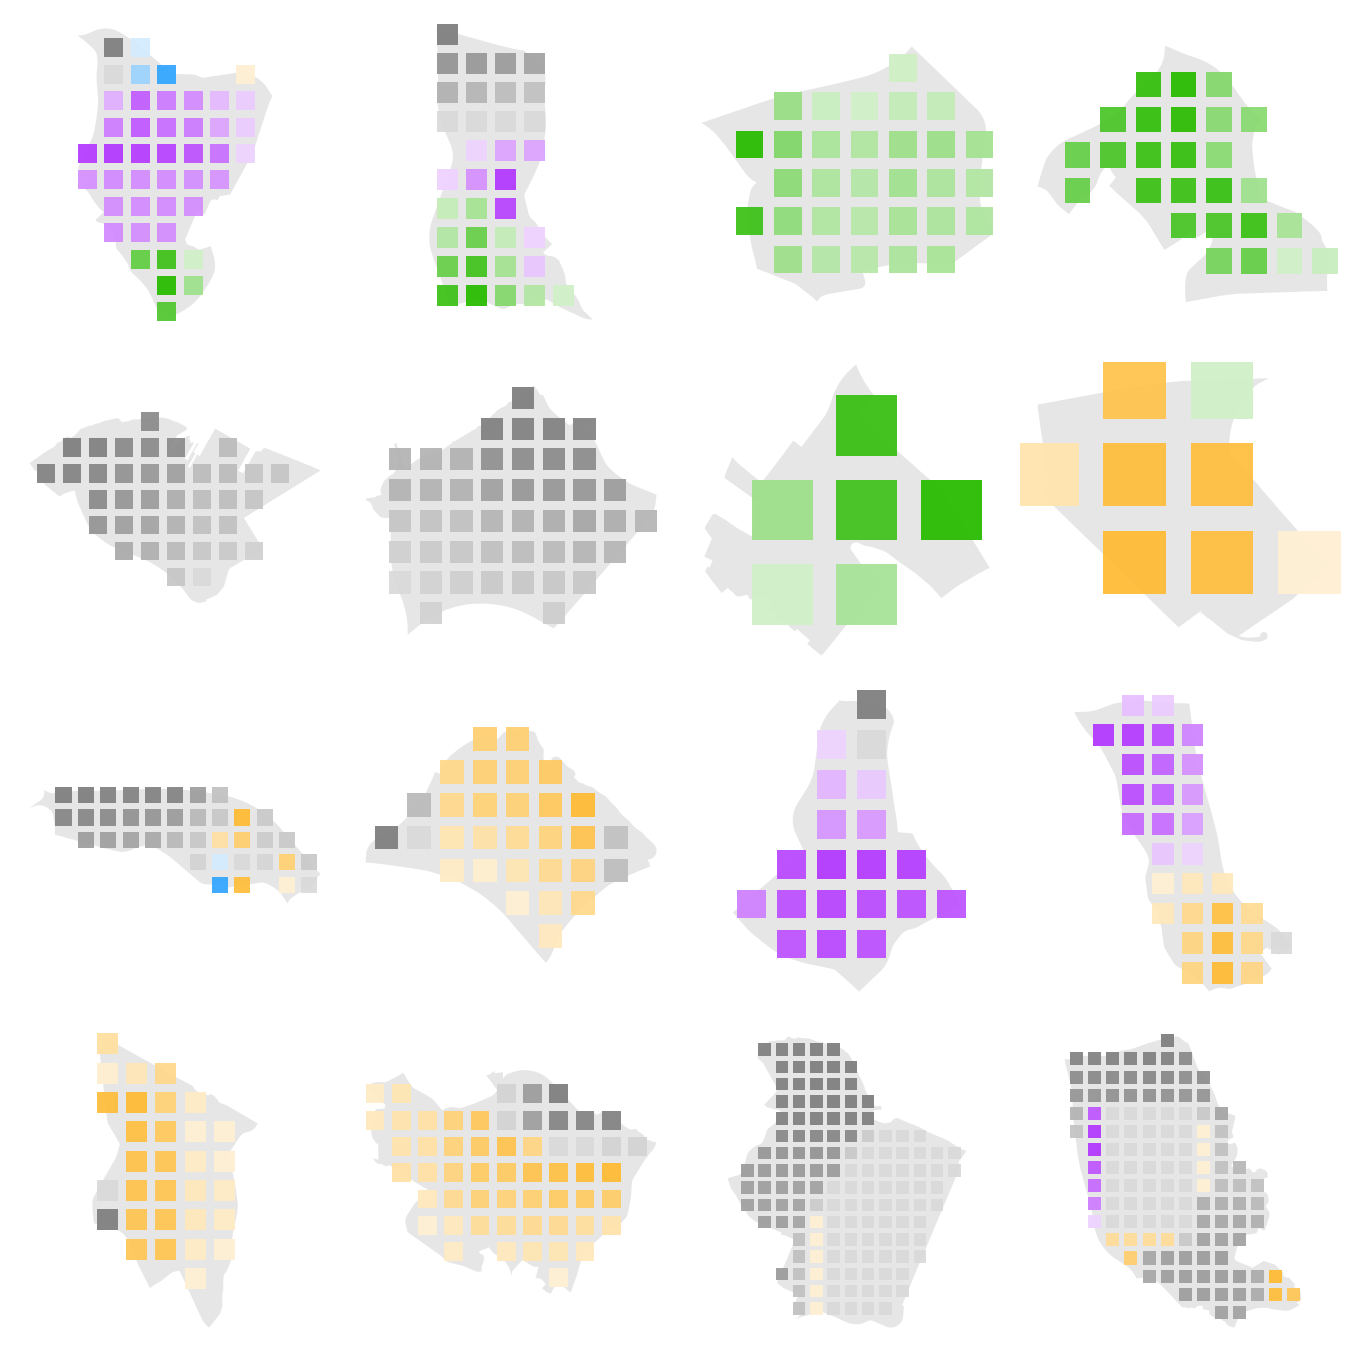

In [17]:
# Representative Type maps: dominant-policy grid squares (value-shaded)
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.collections import PatchCollection
from matplotlib.patches import Rectangle
from matplotlib.colors import to_rgb

print("Creating representative Type dominant-policy maps...")

# --- edit here ---
REPRESENTATIVE_TYPES = None       # None = all cluster types; or e.g. [1, 4] to subset
N_AREAS_PER_TYPE = 2              # top-N admin areas by total_contribution per type
N_COLS = 4                        # subplot columns (8 types × 2 → 16 panels = 4×4)
SQUARE_SCALE = 0.72               # square size vs grid spacing (<1 avoids gaps)
MIN_COLOUR_WEIGHT = 0.22          # lightest policy tint (UCP_2–5) still visible on white
BOUNDARY_FACE = "#E6E6E6"         # district fill (no outline)
# UCP_1 greys: subtle ramp just below district fill → medium grey
UCP1_GREY_LIGHT = "#DADADA"
UCP1_GREY_DARK = "#808080"

DOMINANT_POLICY_COLOURS = {
    1: "#B8B8B8",   # baseline
    2: "#29BB00",   # UCP_2
    3: "#FFBC37",   # UCP_3
    4: "#35A7FF",   # UCP_4
    5: "#B339FF",   # UCP_5
}
POLICY_LABELS = {1: "UCP_1", 2: "UCP_2", 3: "UCP_3", 4: "UCP_4", 5: "UCP_5"}


def _grid_square_side(pts_gdf):
    """Infer grid spacing; round coords first to avoid float duplicates zeroing dy."""
    tol = 1e-9
    spacings = []
    for arr in (pts_gdf.geometry.x.to_numpy(), pts_gdf.geometry.y.to_numpy()):
        vals = np.sort(np.unique(np.round(arr, 6)))
        if len(vals) > 1:
            diffs = np.diff(vals)
            pos = diffs[diffs > tol]
            if len(pos):
                spacings.append(float(np.median(pos)))
    if not spacings:
        return 1.0 * SQUARE_SCALE
    return min(spacings) * SQUARE_SCALE


def _shade_policy_colour(policy_id, hex_colour, value, vmin, vmax):
    """Value-scaled colour; UCP_1 uses grey ramp (visible on #E6E6E6 fill)."""
    t = np.clip((value - vmin) / max(vmax - vmin, 1e-12), 0.0, 1.0)
    if int(policy_id) == 1:
        light = np.array(to_rgb(UCP1_GREY_LIGHT))
        dark = np.array(to_rgb(UCP1_GREY_DARK))
        return tuple(light * (1.0 - t) + dark * t)
    t = MIN_COLOUR_WEIGHT + (1.0 - MIN_COLOUR_WEIGHT) * t
    base = np.array(to_rgb(hex_colour))
    white = np.ones(3)
    return tuple(white * (1.0 - t) + base * t)


def _pick_representative_areas(type_gdf, n_areas):
    """Top admin areas in this type by total_contribution."""
    if type_gdf.empty:
        return []
    if "total_contribution" not in type_gdf.columns:
        print("Warning: total_contribution missing; falling back to mean_potential.")
        sort_col = "mean_potential"
    else:
        sort_col = "total_contribution"
    ranked = type_gdf.sort_values(sort_col, ascending=False).head(n_areas)
    return [row for _, row in ranked.iterrows()]


def _plot_dominant_policy_panel(admin_row, pts_gdf, ax):
    geom = admin_row.geometry
    pts = pts_gdf[pts_gdf.geometry.within(geom)].copy()
    ax.set_facecolor("white")

    gpd.GeoSeries([geom], crs=pts_gdf.crs).plot(
        ax=ax,
        facecolor=BOUNDARY_FACE,
        edgecolor="none",
        linewidth=0,
        zorder=0,
    )

    if len(pts) == 0:
        minx, miny, maxx, maxy = geom.bounds
        pad_x = (maxx - minx) * 0.08 or 0.001
        pad_y = (maxy - miny) * 0.08 or 0.001
        ax.set_xlim(minx - pad_x, maxx + pad_x)
        ax.set_ylim(miny - pad_y, maxy + pad_y)
        ax.set_aspect("equal", adjustable="box")
        ax.axis("off")
        return pts

    side = _grid_square_side(pts)
    half = side / 2.0

    # Per-policy value range within panel → better contrast (esp. UCP_1 greys)
    shade_ranges = {}
    for pid in pts["dominant_policy"].unique():
        pvals = pts.loc[pts["dominant_policy"] == pid, "dominant_value"].to_numpy(dtype=float)
        shade_ranges[int(pid)] = (float(pvals.min()), float(pvals.max()))

    patches, colours = [], []
    for _, pt in pts.iterrows():
        x, y = pt.geometry.x, pt.geometry.y
        patches.append(Rectangle((x - half, y - half), side, side))
        pid = int(pt["dominant_policy"])
        base_hex = DOMINANT_POLICY_COLOURS.get(pid, "#808080")
        vmin, vmax = shade_ranges[pid]
        colours.append(
            _shade_policy_colour(pid, base_hex, float(pt["dominant_value"]), vmin, vmax)
        )

    ax.add_collection(
        PatchCollection(patches, facecolor=colours, edgecolor="none", alpha=0.95, zorder=2)
    )

    minx, miny, maxx, maxy = geom.bounds
    pad_x = (maxx - minx) * 0.06 or side
    pad_y = (maxy - miny) * 0.06 or side
    ax.set_xlim(minx - pad_x, maxx + pad_x)
    ax.set_ylim(miny - pad_y, maxy + pad_y)
    ax.set_aspect("equal", adjustable="box")
    ax.axis("off")
    return pts


if (
    "ucp_gdf" in globals()
    and "admin_potential_gdf" in globals()
    and "cluster_type" in admin_potential_gdf.columns
):
    _delta_cols = sorted(c for c in ucp_gdf.columns if c.startswith("Delta-UCP"))
    if not _delta_cols:
        print("Error: no Delta-UCP columns on ucp_gdf.")
    else:
        _ucp1 = ucp_gdf["UCP_1"].to_numpy(dtype=float)
        _diffs = ucp_gdf[_delta_cols].fillna(0.0).to_numpy()
        # Dominant = largest among UCP_1 and Δ-UCP_2…5 (same parts as rank/base share)
        _contest = np.column_stack([_ucp1, _diffs])
        _win_idx = np.argmax(_contest, axis=1)
        _win_val = _contest[np.arange(len(_contest)), _win_idx]
        ucp_dom = ucp_gdf.copy()
        ucp_dom["dominant_policy"] = _win_idx + 1   # 1=UCP_1, 2–5=UCP_2…UCP_5
        ucp_dom["dominant_value"] = _win_val

        available_types = sorted(admin_potential_gdf["cluster_type"].dropna().unique().astype(int))
        if REPRESENTATIVE_TYPES is None:
            rep_types = available_types
        else:
            rep_types = [int(t) for t in REPRESENTATIVE_TYPES if int(t) in available_types]
        if not rep_types:
            rep_types = available_types

        panels = []
        for t in rep_types:
            type_gdf = admin_potential_gdf[admin_potential_gdf["cluster_type"] == t]
            areas = _pick_representative_areas(type_gdf, N_AREAS_PER_TYPE)
            for row in areas:
                panels.append((int(t), row))

        if not panels:
            print("No admin areas found for the selected types.")
        else:
            n_panels = len(panels)
            n_cols = min(N_COLS, n_panels)
            n_rows = int(np.ceil(n_panels / n_cols))
            panel_inches = 2.8
            fig, axes = plt.subplots(
                n_rows, n_cols,
                figsize=(panel_inches * n_cols, panel_inches * n_rows),
                constrained_layout=True,
            )
            fig.patch.set_facecolor("white")
            axes = np.atleast_1d(axes).flatten()

            expected = len(rep_types) * N_AREAS_PER_TYPE
            print(
                f"Panels: {n_panels} ({len(rep_types)} type(s) × {N_AREAS_PER_TYPE} area(s); "
                f"expected up to {expected})"
            )
            print(f"Dominant policy colours: {POLICY_LABELS} (argmax UCP_1 vs Δ-UCP_2…5; shade ∝ winner within panel)")

            for i, (type_id, admin_row) in enumerate(panels):
                ax = axes[i]
                pts = _plot_dominant_policy_panel(admin_row, ucp_dom, ax)
                counts = pts["dominant_policy"].value_counts().sort_index() if len(pts) else {}
                shares = {POLICY_LABELS.get(k, k): f"{v / len(pts) * 100:.1f}%" for k, v in counts.items()} if len(pts) else {}
                tc = admin_row.get("total_contribution", float("nan"))
                print(
                    f"  Panel {i + 1}: Type {type_id} — {admin_row['admin_name']} "
                    f"(total_contrib={tc:.4f}, n={len(pts)}); dominant share: {shares}"
                )

            for j in range(n_panels, len(axes)):
                axes[j].axis("off")
                axes[j].set_visible(False)

            if "_save_fig" in globals():
                _save_fig(fig, "type_dominant_policy_examples")
            else:
                import os
                os.makedirs("figure", exist_ok=True)
                out = "figure/code_8_type_dominant_policy_examples.png"
                fig.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
                print(f"Saved figure → {out}")

            plt.show()
else:
    print("Skip: need ucp_gdf and admin_potential_gdf with cluster_type (run classification cell first).")


<a id="sec-5-11-perf"></a>

### 5.11 Optimisation performance

pUCI vs UCP scatter analogue (legacy SSAC/OBI figure mapping in caption).


Creating optimisation performance figures (pUCI × UCP)...
Saved figure → figure/code_8_uci_optimisation_scatter.png
Saved figure → figure/code_8_uci_optimisation_scatter.svg


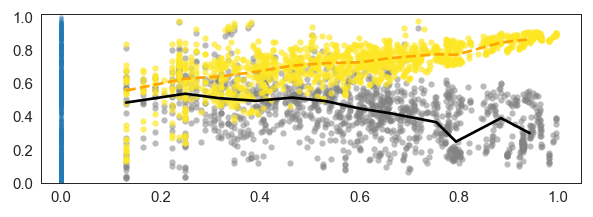

Saved figure → figure/code_8_uci_optimisation_trends.png
Saved figure → figure/code_8_uci_optimisation_trends.svg


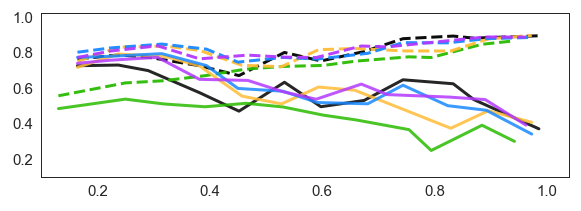

Saved figure → figure/code_8_uci_optimisation_delta.png
Saved figure → figure/code_8_uci_optimisation_delta.svg


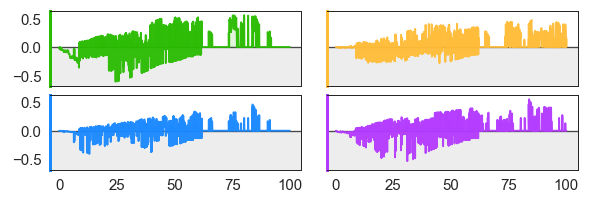

Saved figure → figure/code_8_uci_optimisation_puci_uplift_sum.png
Saved figure → figure/code_8_uci_optimisation_puci_uplift_sum.svg
Fig-4: Σ(new pUCI − original pUCI) per policy — P1=283.22, P2=385.99, P3=298.46, P4=290.81, P5=281.79


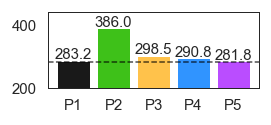

Terminology: pUCI ≈ SSAC (comfort index); UCP ≈ OBI (optimisation overlap)
  Policy 1: active points=1297/2096 (61.9%); mean pUCI=0.528; mean UCP=0.333; Σ UCP=697.5
  Policy 2: active points=1319/2096 (62.9%); mean pUCI=0.421; mean UCP=0.366; Σ UCP=767.4
  Policy 3: active points=1518/2096 (72.4%); mean pUCI=0.522; mean UCP=0.366; Σ UCP=767.0
  Policy 4: active points=1289/2096 (61.5%); mean pUCI=0.532; mean UCP=0.344; Σ UCP=721.9
  Policy 5: active points=1340/2096 (63.9%); mean pUCI=0.553; mean UCP=0.352; Σ UCP=738.7


In [49]:
# Optimisation performance figures (pUCI vs UCP; legacy SSAC/OBI analogue)
import os
import numpy as np
import matplotlib.pyplot as plt

print("Creating optimisation performance figures (pUCI × UCP)...")

# --- edit here ---
UCP_ACTIVE_THRESHOLD = 0.01       # treat as "optimised" when UCP_k exceeds this
UPLIFT_ALPHA = 0.85               # new-pUCI proxy strength (see markdown above)
N_BINS_TREND = 12                 # bins for trend lines
HIGHLIGHT_POLICY = 2              # Policy shown in row-1 scatter (1–5)
FIG_W1, FIG_H1 = 5.0, 1.6        # row 1 aspect 2:1
FIG_W23, FIG_H23 = 5.0, 1.6      # row 2/3 aspect 3:1
FIG4_W, FIG4_H = 2.0, 0.75        # fig-4 cumulative pUCI uplift bar chart
FIG1_TICKSIZE = 9                 # axis tick label size (all figures)
FIG1_AXIS_TICKS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]  # fig-1 x/y tick positions
FIG1_X_PAD = 0.04                 # left x-axis margin (keeps x≈0 visible; fig3 uses ×100)
FIG2_AXIS_MIN = 0.1               # fig-2 x/y axis lower limit
FIG3_STYLE = "facet"              # "facet" (2×2 panels) | "overlay" (single panel)
FIG3_FACET_H = 1.5                # fig-3 height for 2×2 layout
FIG3_NEG_FILL = "#D8D8D8"         # grey background for Δ-UCP < 0
FIG3_NEG_FILL_ALPHA = 0.45
FIG4_Y_MIN = 200                  # fig-4 y-axis lower limit (Σ uplift gain)
FIG4_Y_TOP_PAD = 0.30             # internal ylim headroom above tallest bar (fraction of y-range)
SPINE_LW = 0.6                    # axis border line width (all figures)

# Row-1 colours — edit freely
SCATTER_COLOUR_UNCHANGED = "#2279B5"
SCATTER_COLOUR_ORIGINAL = "#838383"
SCATTER_COLOUR_UPLIFT = "#FDE725"
TREND_COLOUR_UNCHANGED = "#333333"
TREND_COLOUR_ORIGINAL = "#000000"
TREND_COLOUR_UPLIFT = "#FFA500"

PUCI_COLS = [
    "pUCI_1_balanced_development",
    "pUCI_2_eco_livable",
    "pUCI_3_community_cohension",
    "pUCI_4_active_walkability",
    "pUCI_5_tourism_strategy",
]
UCP_COLS = [f"UCP_{i}" for i in range(1, 6)]
POLICY_LABELS_PERF = {i: f"Policy {i}" for i in range(1, 6)}
POLICY_COLOURS_PERF = {
    1: "#000000",
    2: "#29BB00",
    3: "#FFBC37",
    4: "#1988FF",
    5: "#B339FF",
}


def _puci_new(puci, ucp):
    """Heuristic post-optimisation pUCI (monotonic uplift toward 1)."""
    return np.minimum(1.0, puci + UPLIFT_ALPHA * ucp * np.maximum(0.0, 1.0 - puci))


def _binned_trend(x, y, n_bins=N_BINS_TREND):
    x, y = np.asarray(x, float), np.asarray(y, float)
    mask = np.isfinite(x) & np.isfinite(y)
    x, y = x[mask], y[mask]
    if len(x) < 5:
        return np.array([]), np.array([])
    edges = np.linspace(x.min(), x.max(), n_bins + 1)
    xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (x >= lo) & (x < hi) if hi < edges[-1] else (x >= lo) & (x <= hi)
        if m.sum() >= 3:
            xs.append(np.median(x[m]))
            ys.append(np.median(y[m]))
    return np.array(xs), np.array(ys)


def _style_axes(ax, spine_lw=SPINE_LW):
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_linewidth(spine_lw)


def _xlim_padded(x_data_max, x_data_min=0.0, hard_max=None):
    """Left pad + ~5% right margin (matches fig-1 scatter panel)."""
    lo = x_data_min - FIG1_X_PAD
    hi = max(x_data_min + 0.05, float(x_data_max) * 1.05)
    if hard_max is not None:
        hi = min(float(hard_max) + FIG1_X_PAD, hi)
    return lo, hi


def _xlim_padded_pct(x_data_max=100.0, x_data_min=0.0):
    """Percentile axis (0–100): same padding logic, scaled to 0–100."""
    pad = FIG1_X_PAD * 100.0
    lo = x_data_min - pad
    hi = max(x_data_min + 0.05 * 100.0, float(x_data_max) * 1.05)
    return lo, hi


def _shade_delta_negative(ax, y_lim):
    """Grey band below zero (baseline beats specialised policy)."""
    if y_lim[0] < 0:
        ax.axhspan(y_lim[0], 0, facecolor=FIG3_NEG_FILL, alpha=FIG3_NEG_FILL_ALPHA, zorder=0, linewidth=0)


def _plot_delta_ucp_facet(delta_sorted, x_pct, x_lim, y_lim):
    """2×2 panels (P2–P5) — avoids z-order / colour stacking."""
    policy_keys = list(range(2, 6))
    fig, axes = plt.subplots(
        2, 2, figsize=(FIG_W23, FIG3_FACET_H), sharex=True, sharey=True,
        facecolor="white", gridspec_kw={"hspace": 0.12, "wspace": 0.10},
    )
    for ax, k in zip(axes.flat, policy_keys):
        d = delta_sorted[k]
        col = POLICY_COLOURS_PERF[k]
        ax.set_xlim(*x_lim)
        ax.set_ylim(*y_lim)
        _shade_delta_negative(ax, y_lim)
        ax.axhline(0, color=POLICY_COLOURS_PERF[1], lw=0.8, alpha=0.7, zorder=1)
        ax.fill_between(x_pct, 0, d, where=d > 0, color=col, alpha=0.14, zorder=2)
        ax.plot(x_pct, d, color=col, lw=1.1, alpha=0.95, zorder=3)
        ax.tick_params(labelsize=FIG1_TICKSIZE, length=3)
        _style_axes(ax)
        ax.spines["left"].set_color(col)
        ax.spines["left"].set_linewidth(1.8)
    for ax in axes[0, :]:
        ax.tick_params(labelbottom=False)
    for ax in axes[:, 1]:
        ax.tick_params(labelleft=False)
    fig.subplots_adjust(left=0.10, right=0.98, bottom=0.10, top=0.98, hspace=0.12, wspace=0.10)
    return fig


def _plot_delta_ucp_overlay(delta_sorted, x_pct, x_lim, y_lim):
    """Single panel; draw smallest peak first so larger gains stay visible on top."""
    fig, ax = plt.subplots(figsize=(FIG_W23, FIG_H23), facecolor="white")
    ax.set_xlim(*x_lim)
    ax.set_ylim(*y_lim)
    _shade_delta_negative(ax, y_lim)
    ax.axhline(0, color=POLICY_COLOURS_PERF[1], lw=1.0, alpha=0.85, zorder=1)
    draw_order = sorted(
        range(2, 6), key=lambda k: float(np.nanmax(delta_sorted[k])), reverse=False,
    )
    for rank, k in enumerate(draw_order):
        d = delta_sorted[k]
        z = 2 + rank
        ax.plot(x_pct, d, color=POLICY_COLOURS_PERF[k], lw=1.1, alpha=0.95, zorder=z + 5)
    ax.tick_params(labelsize=FIG1_TICKSIZE, length=3)
    _style_axes(ax)
    fig.subplots_adjust(left=0.10, right=0.98, bottom=0.10, top=0.95)
    return fig


def _save_perf_fig(fig, stem):
    if "_save_fig" in globals():
        _save_fig(fig, stem)
    else:
        os.makedirs("figure", exist_ok=True)
        out = f"figure/code_8_{stem}.png"
        fig.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
        print(f"Saved figure → {out}")


def _scatter_policy_panel(ax, puci, ucp, policy_id, title=None, xlim=None, axis_labels=True, ticksize=FIG1_TICKSIZE):
    active = ucp > UCP_ACTIVE_THRESHOLD
    unchanged = ~active

    ax.scatter(
        ucp[unchanged], puci[unchanged],
        c=SCATTER_COLOUR_UNCHANGED, s=8, alpha=0.35, linewidths=0, zorder=1,
    )
    if active.any():
        ax.scatter(
            ucp[active], puci[active],
            c=SCATTER_COLOUR_ORIGINAL, s=14, alpha=0.55, linewidths=0, zorder=2,
        )
        puci_post = _puci_new(puci[active], ucp[active])
        ax.scatter(
            ucp[active], puci_post,
            c=SCATTER_COLOUR_UPLIFT, s=14, alpha=0.7, linewidths=0, zorder=3,
        )
        for ucp_sub, puci_sub, col, ls in [
            (ucp[unchanged], puci[unchanged], TREND_COLOUR_UNCHANGED, "-"),
            (ucp[active], puci[active], TREND_COLOUR_ORIGINAL, "-"),
            (ucp[active], puci_post, TREND_COLOUR_UPLIFT, "--"),
        ]:
            xs, ys = _binned_trend(ucp_sub, puci_sub)
            if len(xs):
                ax.plot(xs, ys, color=col, ls=ls, lw=1.6, zorder=4)

    if axis_labels:
        ax.set_xlabel(f"UCP_{policy_id} (OBI analogue)")
        ax.set_ylabel(f"pUCI_{policy_id} (SSAC analogue)")
    ax.set_ylim(0, 1.02)
    x_max = float(np.nanmax(ucp))
    if xlim is not None:
        ax.set_xlim(xlim[0] - FIG1_X_PAD, xlim[1] * 1.05)
    else:
        ax.set_xlim(*_xlim_padded(x_max))
    if title:
        ax.set_title(title, fontsize=10)
    ax.tick_params(labelsize=ticksize, length=3)
    _style_axes(ax)


if "ucp_gdf" not in globals():
    print("Skip: ucp_gdf not found — run UCP calculation cells first.")
else:
    missing_puci = [c for c in PUCI_COLS if c not in ucp_gdf.columns]
    missing_ucp = [c for c in UCP_COLS if c not in ucp_gdf.columns]
    if missing_puci or missing_ucp:
        print(f"Skip: missing columns — pUCI {missing_puci or 'ok'}; UCP {missing_ucp or 'ok'}")
    else:
        n = len(ucp_gdf)
        puci_arr = {i + 1: ucp_gdf[c].to_numpy(dtype=float) for i, c in enumerate(PUCI_COLS)}
        ucp_arr = {i + 1: ucp_gdf[c].to_numpy(dtype=float) for i, c in enumerate(UCP_COLS)}

        # --- Row 1: single scatter panel (2:1) ---
        hi = HIGHLIGHT_POLICY
        fig1, ax1 = plt.subplots(figsize=(FIG_W1, FIG_H1), facecolor="white")
        _scatter_policy_panel(ax1, puci_arr[hi], ucp_arr[hi], hi, axis_labels=False)
        ax1.set_xticks(FIG1_AXIS_TICKS)
        ax1.set_yticks(FIG1_AXIS_TICKS)
        ax1.set_xticklabels([f"{t:.1f}" for t in FIG1_AXIS_TICKS])
        ax1.set_yticklabels([f"{t:.1f}" for t in FIG1_AXIS_TICKS])
        fig1.subplots_adjust(left=0.08, right=0.98, bottom=0.10, top=0.98)
        _save_perf_fig(fig1, "uci_optimisation_scatter")
        plt.show()

        # --- Row 2: five policies — original + uplifted trend lines (3:1), no scatter ---
        fig2, ax2 = plt.subplots(figsize=(FIG_W23, FIG_H23), facecolor="white")
        x_hi = 0.05
        for k in range(1, 6):
            puci, ucp = puci_arr[k], ucp_arr[k]
            active = ucp > UCP_ACTIVE_THRESHOLD
            col = POLICY_COLOURS_PERF[k]
            if active.any():
                xs0, ys0 = _binned_trend(ucp[active], puci[active])
                xs1, ys1 = _binned_trend(ucp[active], _puci_new(puci[active], ucp[active]))
            else:
                xs0, ys0 = _binned_trend(ucp, puci)
                xs1, ys1 = np.array([]), np.array([])
            if len(xs0):
                ax2.plot(
                    xs0, ys0, color=col, lw=1.8, ls="-", alpha=0.85,
                    label=f"{POLICY_LABELS_PERF[k]} (original)",
                )
            if len(xs1):
                ax2.plot(
                    xs1, ys1, color=col, lw=1.8, ls="--", alpha=0.95,
                    label=f"{POLICY_LABELS_PERF[k]} (uplift)",
                )
            x_hi = max(x_hi, float(np.nanmax(ucp)))
        _, x_right = _xlim_padded(x_hi, hard_max=1.0)
        ax2.set_xlim(FIG2_AXIS_MIN, x_right)
        ax2.set_ylim(FIG2_AXIS_MIN, 1.02)
        ax2.tick_params(labelsize=FIG1_TICKSIZE, length=3)
        _style_axes(ax2)
        fig2.subplots_adjust(left=0.10, right=0.98, bottom=0.10, top=0.95)
        _save_perf_fig(fig2, "uci_optimisation_trends")
        plt.show()

        # --- Row 3: Δ-UCP vs baseline UCP_1 (sorted high → low) ---
        order = np.argsort(ucp_arr[1])[::-1]
        x_pct = (np.arange(n) / max(n - 1, 1)) * 100.0
        delta_sorted = {k: (ucp_arr[k] - ucp_arr[1])[order] for k in range(2, 6)}
        d_vals = np.concatenate([delta_sorted[k] for k in range(2, 6)])
        y_lo = min(0.0, float(np.nanmin(d_vals)) * 1.08 if d_vals.size else -0.02)
        y_hi = max(0.05, float(np.nanmax(d_vals)) * 1.08 if d_vals.size else 0.05)
        pad = 0.02 * max(y_hi - y_lo, 0.05)
        x_lim = _xlim_padded_pct(100.0)
        y_lim = (y_lo - pad, y_hi + pad)

        if FIG3_STYLE == "facet":
            fig3 = _plot_delta_ucp_facet(delta_sorted, x_pct, x_lim, y_lim)
        else:
            fig3 = _plot_delta_ucp_overlay(delta_sorted, x_pct, x_lim, y_lim)
        _save_perf_fig(fig3, "uci_optimisation_delta")
        plt.show()

        # --- Row 4: Σ(new pUCI − original pUCI) per policy (matches fig-1/2 uplift proxy) ---
        fig4, ax4 = plt.subplots(figsize=(FIG4_W, FIG4_H), facecolor="white")
        cum_uplift = []
        for k in range(1, 6):
            puci_orig = puci_arr[k]
            puci_new = _puci_new(puci_orig, ucp_arr[k])
            cum_uplift.append(float((puci_new - puci_orig).sum()))
        bars = ax4.bar(
            range(5), cum_uplift,
            color=[POLICY_COLOURS_PERF[k] for k in range(1, 6)],
            edgecolor="none", alpha=0.9,
        )
        ax4.axhline(cum_uplift[0], color=POLICY_COLOURS_PERF[1], ls="--", lw=0.9, alpha=0.7)
        y_max = max(cum_uplift) if cum_uplift else FIG4_Y_MIN + 1.0
        y_range = max(y_max - FIG4_Y_MIN, 1.0)
        y_top = y_max + FIG4_Y_TOP_PAD * y_range
        ax4.set_ylim(FIG4_Y_MIN, y_top)
        ax4.set_xticks(range(5))
        ax4.set_xticklabels([f"P{k}" for k in range(1, 6)], fontsize=FIG1_TICKSIZE)
        ax4.tick_params(labelsize=FIG1_TICKSIZE)
        _style_axes(ax4)
        for b, v in zip(bars, cum_uplift):
            ax4.text(
                b.get_x() + b.get_width() / 2, v, f"{v:.1f}",
                ha="center", va="bottom", fontsize=FIG1_TICKSIZE,
            )

        fig4.subplots_adjust(left=0.10, right=0.98, bottom=0.10, top=0.95)
        _save_perf_fig(fig4, "uci_optimisation_puci_uplift_sum")
        print(
            "Fig-4: Σ(new pUCI − original pUCI) per policy — "
            + ", ".join(f"P{k}={v:.2f}" for k, v in enumerate(cum_uplift, start=1))
        )
        plt.show()

        # Summary print
        print("Terminology: pUCI ≈ SSAC (comfort index); UCP ≈ OBI (optimisation overlap)")
        for k in range(1, 6):
            act = int((ucp_arr[k] > UCP_ACTIVE_THRESHOLD).sum())
            print(
                f"  Policy {k}: active points={act}/{n} ({100*act/n:.1f}%); "
                f"mean pUCI={puci_arr[k].mean():.3f}; mean UCP={ucp_arr[k].mean():.3f}; "
                f"Σ UCP={ucp_arr[k].sum():.1f}"
            )